s

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.ticker import MultipleLocator, LogLocator, NullFormatter
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.special import erf
import scipy
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib import gridspec
import matplotlib.patches as patches
import h5py
import matplotlib.animation as animation

from os import listdir
from os.path import isfile, join,getmtime
import re
import delayscan.TRclasses as tr
from delayscan.TRclasses import reduceBins

In [2]:
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 9
plt.rcParams['legend.fontsize'] = 7
plt.rcParams['axes.labelsize'] = 'medium' #equal to font.size
plt.rcParams['figure.labelsize'] = 'medium' #equal to font.size
plt.rcParams['legend.handletextpad'] = 0.3
plt.rcParams['legend.labelspacing'] = 0.3
plt.rcParams['lines.linewidth'] = 1
plt.rcParams['lines.markersize'] = 6
plt.rcParams['legend.frameon'] = False

fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

plt.rcParams['figure.figsize'] = (ACSwid, ACSwid*0.75)
#double column between 4.167 in. and 7 in.

colors = list(mcolors.TABLEAU_COLORS)

In [3]:
#Extra colours
violet = '#5D3FD3'
red = '#D62828'

blue ='#3A86FF'
green='#6A994E'

In [4]:
# from pathlib import Path
# cpath = str(Path.home())


cpath = "D:"
cpath


'D:'

### Retrieval functions

In [5]:
h5path = r"bases/"

In [6]:
fileDic = {
    "a": 0.0,
    "b": 0.1,
    "c": 0.2,
    "d": 0.3,
    "e": 0.5,
    "f": 0.8,
    "g": 1.0,
    "h": 1.5,
    "i": 2.0,
}
concAmps = [0.0,0.1,0.2,0.5,1.0,2.0,2.75,3.0,4.0,5.0,10.0,20.0,50.0,100.0]
concAmps = [0.0,0.1,0.2,0.5,1.0,2.0,         4.6,5.0,10.0,20.0,50.0,100.0]
E0s = list(fileDic.values())
crossSectionSets = ['1b','2','4','5']

#Guide for indices of basisSets (E0 amp)
indexGuide = []
for E0 in fileDic.values():
    indices = []
    for amp in concAmps:
        indices.append((E0, amp))
    indexGuide.append(indices)
indexGuide = np.array(indexGuide)

print("Loading basis sets...")
h5File = h5py.File(h5path+'basisSets_pCE_2026.hdf5', 'r')
allBasisSets = h5File['allBasisSets']
allBasisSetsUnnorm = h5File['allBasisSetsUnnorm']
print("Basis sets loaded")
allBasisSets

Loading basis sets...
Basis sets loaded


<HDF5 dataset "allBasisSets": shape (4, 9, 12, 500, 500), type "<f8">

In [7]:

print(np.amax(allBasisSetsUnnorm))

12553542.404563507


Text(0, 0.5, 'Pump-probe delay / ps')

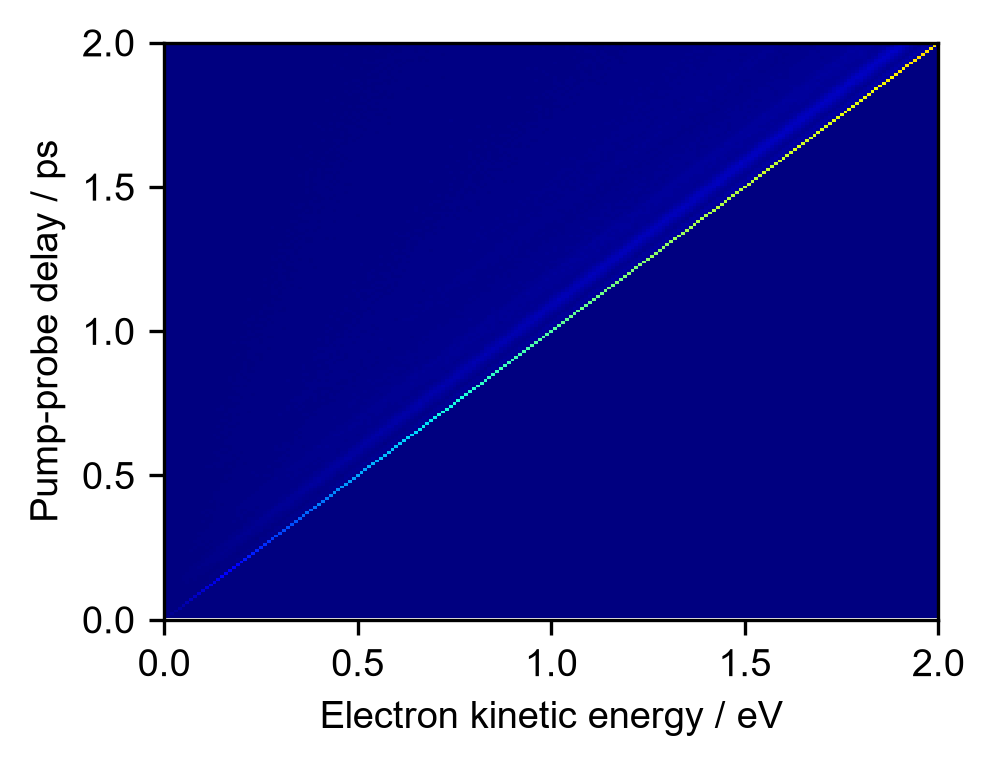

In [8]:
fig,ax = plt.subplots()
xs = np.arange(0.01,5.01,0.01)
crossSectionSetInd = 0
thresholdInd = 6
surfInd = 6

im0 = ax.pcolormesh(xs,xs,
                    allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,surfInd],
                    cmap='jet',
                    # shading='gouraud',
                   )


# ax.set_yscale('log')
ax.set_xlim(0,2)
ax.set_ylim(0,2)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

In [9]:
def interpolateData(data, min_eKE = 0,xs = np.arange(0.01,5.01,0.01)):
    data = np.asarray(data)
    itp = interp1d(data[0], data[1], bounds_error=False, fill_value=0.0)
    y_itp = itp(xs)
    x_above_cutoff = xs[xs>min_eKE]
    
    y_above_cutoff = y_itp[-x_above_cutoff.shape[0]:]

    return np.asarray((x_above_cutoff,y_above_cutoff))

In [10]:
# Multiple Gaussian function for fitting to bases
def multiple_gaussians(x, *params):
    y = np.zeros_like(x)
    for i in range(0, len(params), 3):
        amp = params[i]
        ctr = params[i+1]
        FWHM = params[i+2] 
        wid = FWHM * 0.60056
        y = y + amp * np.exp( -((x - ctr)/wid)**2)
    return y


class JetFitFunc():
    def __init__(self, num_surf, num_bulk, surf_bas, bulk_bas, min_eKE):
        self.num_surf = num_surf
        self.num_bulk = num_bulk
        self.num_peaks = self.num_surf + self.num_bulk
        self.surf_bas = surf_bas
        self.bulk_bas = bulk_bas
        self.min_eKE = min_eKE

    def f(self, x, *params):
        peaks_so_far = 0
        y = np.zeros_like(x)
 
        for i in range(0, len(params), 3):
            if peaks_so_far < self.num_surf:
                basis = self.surf_bas
            else:
                basis = self.bulk_bas
                
            amp = params[i]
            ctr = params[i+1]
            wid = params[i+2]*.60056
            y_tmp = amp * np.exp( -((x - ctr)/wid)**2)
            y += np.sum(basis.T * y_tmp, axis=1)
            
            peaks_so_far += 1
        
        x_above_cutoff = x[x>=self.min_eKE]
        y_above_cutoff = y[-x_above_cutoff.shape[0]:]
        
        return y_above_cutoff

### Calibration

In [6]:
# Instrument function
# IFparams = np.array([-0.16748183,  0.04899803])
# IFparams = np.array([-94.75912571,   0.03231905])
IFparams = np.array([-6.90359945,  0.02964122])
# cutoff at eKE = 0.126
IF_cutoff = 0.126

In [7]:
#Calibration
calParams = np.array([  0.62209127, 48.29925437,  1.10221363])

### Data info

In [5]:
#Streaming potentials
SP_250618a = np.array([0.04311971972339012,  0.11392843764785496])
SP_250618b = np.array([ -0.006693700629576166, 0.19740889917916987 ])
SP_250618c = np.array([0.037811958986494684,  0.12997911802896056 ])
SP_250618d = np.array([-0.004002254614469857,  0.20421880748289375 ])

####
SP=np.array((0,0))
#averages
sum(SP_250618a+SP_250618b)/2,sum(SP_250618c+SP_250618d)/2
sum(SP_250618c),sum(SP_250618d),sum(SP_250618c+SP_250618d)/2

(np.float64(0.16779107701545526),
 np.float64(0.2002165528684239),
 np.float64(0.18400381494193957))

In [8]:
# resultsFolder,date, fn, pump wl, pulseEnergy pump,probe wl, pulseEnergy probe, integration time, SP before, SP after 
resultsPath = r"data/"
resultsPath = r"D:\PhD 2026\pCE TRPES October 26\data/"
fileInfo_250618b = [
    (resultsPath,"180625","dt", 350.0, 5, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","dv", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","dx", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # # (resultsPath,"180625","dz", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","eb", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ec", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","eg", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ei", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ek", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","em", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
]

#Integration times may be wrong but it doesnt matter

fileInfos = [fileInfo_250618b,]

In [9]:
allDelays = []
print("Loading files")
for fileInfo in fileInfos:
    scanSet = tr.DelayScanSet()
    for info in fileInfo:

        scan = tr.DelayScan(resultsFolder = info[0],
                            date = info[1],
                            fileIndex = info[2],
                            pumpWavelength = info[3],
                            pumpPulseEnergy = info[4],
                            probeWavelength = info[5],
                            probePulseEnergy = info[6],
                            integrationTime = info[7],
                            timeZero = info[8],
                            SPbefore = info[9],
                            SPafter = info[10],
                            calParams = calParams,
                            IFparams = IFparams,
                            )
        scan.importData()
        scan.applyJacobian()
        scan.convert2eKE()
        scan.applyInstrumentFunction()
        scan.correctStreamingPotential()
        scan.normaliseByIntegrationTime()
        print(f"{info[1]}{info[2]}")

        scanSet.append(scan)
    allDelays.append(scanSet)
print("Files loaded")

Loading files
180625dt
180625dv
Files loaded


In [14]:
# As there is only one scanSet I will only define it here
scanSet = allDelays[0]


In [28]:
for k in scanSet[0].__dict__.keys():
    print(k)

scan.fileNames

resultsFolder
date
fileIndex
calParams
IFparams
pumpWavelength
probeWavelength
pumpPulseEnergy
probePulseEnergy
integrationTime
timeZero
SPbefore
SPafter
streamingPotentialCorrection
dataPath
directories
fileNames
file_names_split
delay_strings
allDelays
delays
delayTimes
TOFspectra
spectra
jacobianApplied
eKEconversionApplied
instrumentFunctionApplied
streamingPotentialCorrected
integrationTimeNormalised


['70p9846mm_0p0nm_pump_0p0nm_probe_Back.txt',
 '70p9846mm_0p0nm_pump_0p0nm_probe_LasBack1.txt',
 '70p9846mm_0p0nm_pump_0p0nm_probe_LasBack2.txt',
 '70p9846mm_0p0nm_pump_0p0nm_probe_SignalBack.txt',
 '71p2947mm_0p0nm_pump_0p0nm_probe_Back.txt',
 '71p2947mm_0p0nm_pump_0p0nm_probe_LasBack1.txt',
 '71p2947mm_0p0nm_pump_0p0nm_probe_LasBack2.txt',
 '71p2947mm_0p0nm_pump_0p0nm_probe_SignalBack.txt',
 '71p4767mm_0p0nm_pump_0p0nm_probe_Back.txt',
 '71p4767mm_0p0nm_pump_0p0nm_probe_LasBack1.txt',
 '71p4767mm_0p0nm_pump_0p0nm_probe_LasBack2.txt',
 '71p4767mm_0p0nm_pump_0p0nm_probe_SignalBack.txt',
 '71p5834mm_0p0nm_pump_0p0nm_probe_Back.txt',
 '71p5834mm_0p0nm_pump_0p0nm_probe_LasBack1.txt',
 '71p5834mm_0p0nm_pump_0p0nm_probe_LasBack2.txt',
 '71p5834mm_0p0nm_pump_0p0nm_probe_SignalBack.txt',
 '71p6460mm_0p0nm_pump_0p0nm_probe_Back.txt',
 '71p6460mm_0p0nm_pump_0p0nm_probe_LasBack1.txt',
 '71p6460mm_0p0nm_pump_0p0nm_probe_LasBack2.txt',
 '71p6460mm_0p0nm_pump_0p0nm_probe_SignalBack.txt',
 '71p6827m

In [24]:
methods = [
    print(attr) for attr, value in tr.DelayScan.__dict__.items() if callable(value) and not attr.startswith('__')
]
# print(methods)
# Output: ['method_one', 'method_two']
scan.integrationTimeNormalised

importData
delaystring2float
delaystrings2float
applyJacobian
timeToEnergyConversion
convert2eKE
instrumentFunction
applyInstrumentFunction
correctStreamingPotential
normaliseByIntegrationTime
pos2time
subtract


True

### Plot one delay (to determine indices of pp, pump, probe, nothing)

71.7605 mm
71.7605 mm
71.7605 mm
71.7605 mm


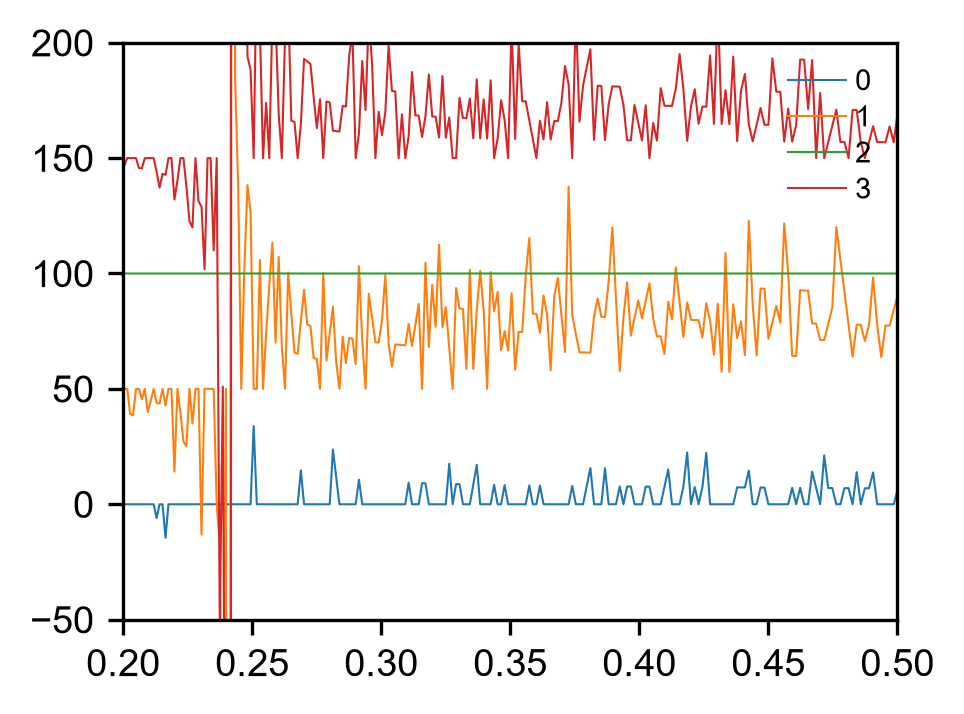

In [17]:
scan = scanSet[5]
#Here ind the index of teh time delay
ind= 5 #0 to (len(delays)/4)-1

ind*=4

for i,spectrum in enumerate(scan.spectra[ind:ind+4]):
    print(f"{scan.delays[ind]} mm")
    plt.plot(spectrum[0],spectrum[1]+i*50,lw=.5,label=i)
plt.xlim(0.2,.5)
plt.ylim(-50,200)
plt.legend()

In [18]:
0.12 + scan.streamingPotentialCorrection

np.float64(0.30400381494193957)

### Get subtracted spectra

In [ ]:
#Here you subtract pump probe and nothing from pp
print(scanSet[0].date)
for scan in scanSet:
    scan.subtract_background(1,3,0,2)

180625


### Plot heatmap of one scan

In [20]:
scan = scanSet[6]
subtracted_rebinned = []
rebins = 20
startRebins = int(rebins/2)

for spectrum in scan.subtracted:
    spectrum = spectrum[:,np.logical_and(spectrum[0]>=.30,spectrum[0]<=5)]
    rebinned_spectrum = reduceBins(spectrum,rebins)
    subtracted_rebinned.append(rebinned_spectrum)
subtracted_rebinned = np.array(subtracted_rebinned)


Text(0, 0.5, 'Pump-probe delay / ps')

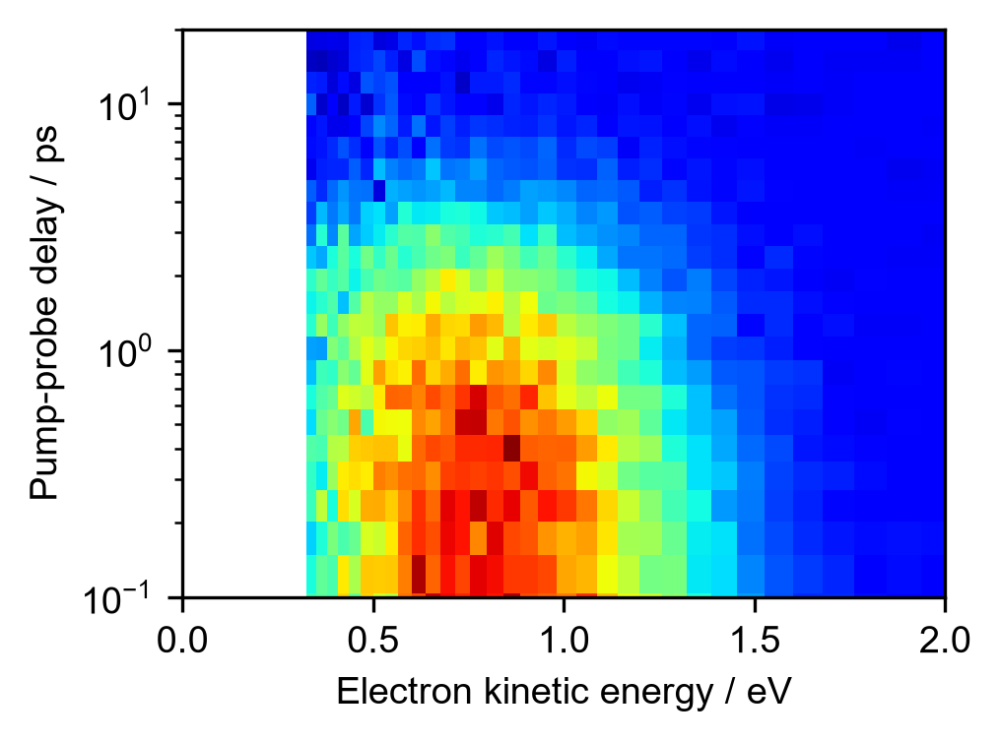

In [21]:
fig,ax = plt.subplots()

im0 = ax.pcolormesh(subtracted_rebinned[0,0],
                    scan.delayTimes,
                    subtracted_rebinned[:,1],
                    cmap='jet',
                    # shading='gouraud',
                   )


ax.set_yscale('log')
ax.set_xlim(0,2)
ax.set_ylim(.1,20)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

### Plot traces of each scan

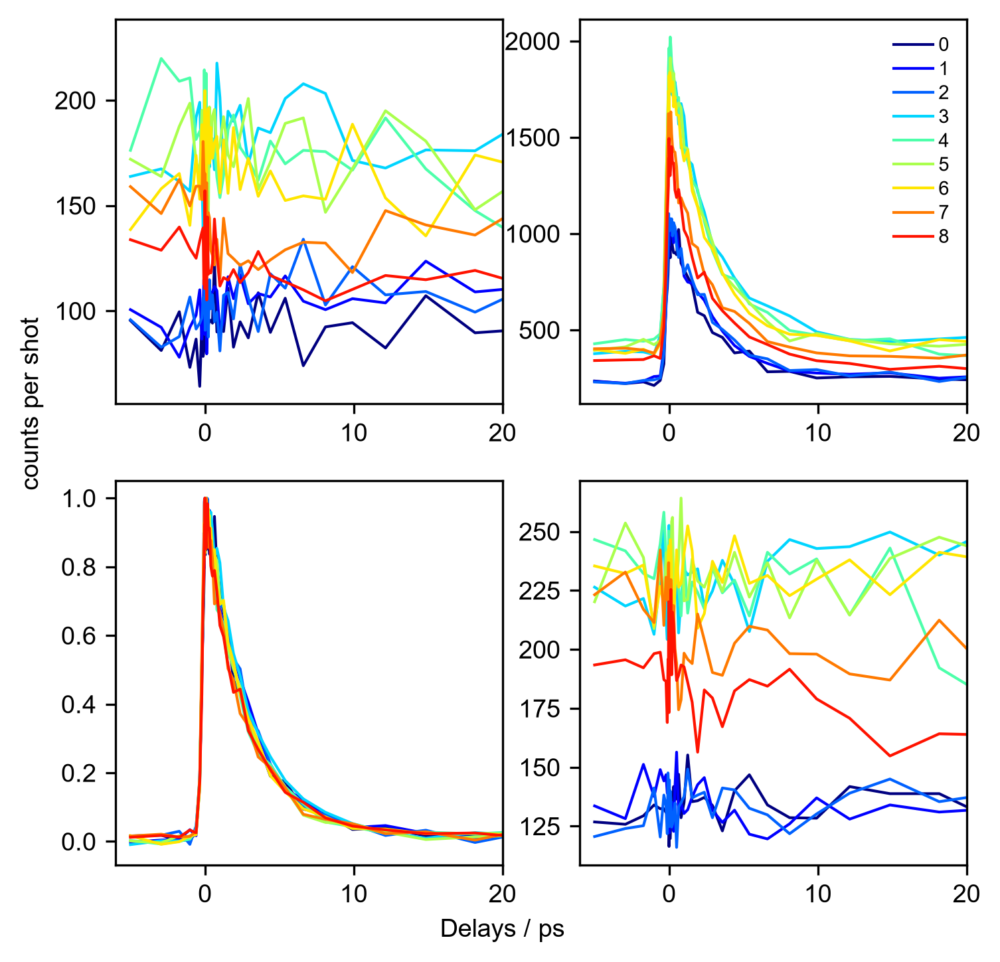

In [22]:
#Create and normalise color map
cmap = plt.get_cmap('jet')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=len(scanSet))  # Normalize data from 0 to 100


fig,axes = plt.subplots(2,2)
fig.set_size_inches(thesisWid,thesisWid)
for scan_ind,scan in enumerate(scanSet):
    integrated_counts = []
    for i,spectrum in enumerate(scan.TOFspectra):

        spectrum_to_integrate = spectrum[1]#[spectrum[1]>1]#[np.logical_and(spectrum[0]>400,spectrum[0]<1500)]
        integrated_counts.append(np.sum(spectrum_to_integrate))

    integrated_counts = np.array(integrated_counts)
    integrated_counts.shape
    integrated_counts = np.reshape(integrated_counts,(integrated_counts.shape[0]//4,4))

    for trace_ind,(trace,ax) in enumerate(zip(integrated_counts.T,axes.flatten())):
        if trace_ind==2:
            trace = integrated_counts.T[1]-integrated_counts.T[0]-integrated_counts.T[2]-integrated_counts.T[3]
            ax.plot(scan.delayTimes,trace/max(trace),c=cmap(norm(scan_ind)),label=scan_ind)            
        else:
            ax.plot(scan.delayTimes,trace/20*4,c=cmap(norm(scan_ind)),label=scan_ind)
for ax in axes.flatten():
    ax.set_xlim(-6,20)

axes[0,0].set_ylabel("counts per shot",y=0)
axes[1,0].set_xlabel("Delays / ps",x=1)
axes[0,1].legend()
# date,fileIndex = scan.date,scan.fileIndex
# m_counts = np.genfromtxt(resultsPath+rf"{date}\{date}{fileIndex}\{date}{fileIndex}{date}{fileIndex}.txt")
# plt.plot(scan.delayTimes,m_counts[:,1:]/20,'o--',ms=1)
# scan.fileIndex

# plt.ylim(0,10)

### Add scanSets from same day

1. Remove data points below eKE cutoff and above 5 eV
2. Sum intensities for the same eKE and time delay (here you assume that the time points and eKEs are the same, which is valid only if you didn't change the time points midway & are using the same SP measurements)
3. Rebin data if you like
4. Save extra data to scanSets

There is some confusion in the naming when it comes to summed and subtracted

In [23]:
IF_cutoff+scan.streamingPotentialCorrection

np.float64(0.31000381494193957)

In [24]:
# 1. Remove data points below low eKE cutoff and above 5 eV
for scanSet in allDelays:
    for scan in scanSet:
        subtracted_cut = [None for _ in scan.subtracted]
        for i,spectrum in enumerate(scan.subtracted):
            subtracted_cut[i] = spectrum[:,np.logical_and(spectrum[0]>=IF_cutoff+scan.streamingPotentialCorrection,spectrum[0]<=5)]
        scan.subtracted_cut = np.array(subtracted_cut)

In [25]:
# 2. Sum intensities for the same eKE and time delay
### ASSUMING TIME DELAYS ARE THE SAME AND LENGTH OF DELAYS IS THE SAME
### ASSUMING eKES ARE THE SAME

for scanSet in allDelays:
    # Create empty array with same shape as the individual subtracted data
    scanSet.subtracted = np.zeros_like(scanSet[0].subtracted_cut[:,1])

    #Sum over scans in scanSet scaled by the number of scans (i.e. average)
    for scan in scanSet:
        scanSet.subtracted += scan.subtracted_cut[:,1]/len(scanSet)
        
    
    #Normalise by highest intensity
    scanSet.subtracted /= np.max(scanSet.subtracted)
    #Save rebinned_energies
    scanSet.energies = scan.subtracted_cut[0,0]
    #Save delays
    scanSet.delays = scan.delayTimes
    


In [26]:
# 3. Rebin data

for scanSet in allDelays:

    subtracted_rebinned = []
    rebins = 10

    for spectrum in scanSet.subtracted:
        spectrum = np.asarray((scanSet.energies,spectrum))
        rebinned_spectrum = reduceBins(spectrum,rebins)[1]
        subtracted_rebinned.append(rebinned_spectrum)
    scanSet.subtracted_rebinned = np.array(subtracted_rebinned)

    #Normalise by highest intensity
    scanSet.subtracted_rebinned /= np.max(scanSet.subtracted_rebinned)
    #Save rebinned_energies
    scanSet.energies_rebinned = reduceBins(spectrum,rebins)[0]
    #Save rebins
    scanSet.rebins = rebins
    
    
# Reset scanSet so that is the one we care about
scanSet = allDelays[0]

### Heatmap

In [27]:
len(scanSet.delays)

47

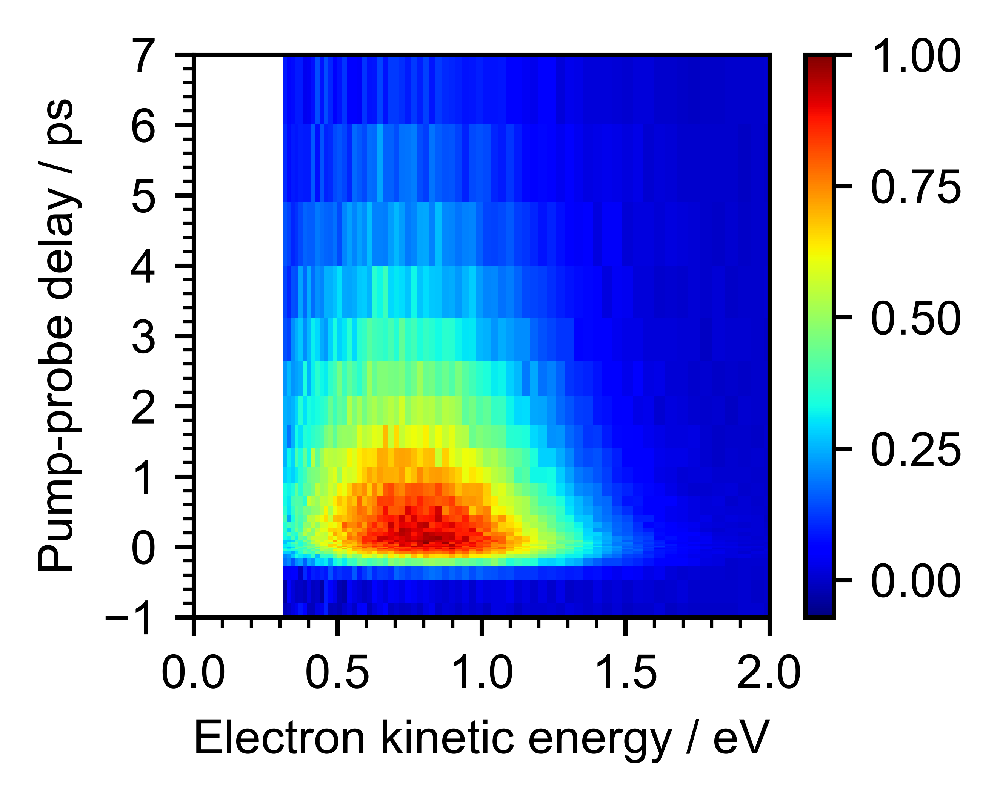

In [28]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

im0 = ax.pcolormesh(scanSet.energies_rebinned,
                    scanSet.delays,
                    scanSet.subtracted_rebinned,
                    cmap='jet',
                    # shading='gouraud',

                   )


ax.set_xlim(0,2)
ax.set_ylim(-1,7)
# ax.set_yscale('log')
# ax.set_ylim(0.01,10)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.yaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

In [29]:
#saveData
if False:
    savePath = cpath+r"/[CHANGE]\PhD\Thesis\Data\Chapter 5\Figure 5.4/"
    #Rebinned
    saveData = np.vstack((scanSet.delays,scanSet.subtracted_rebinned.T))
    saveEnergies = np.hstack(([0,],scanSet.energies_rebinned))
    saveData = np.vstack((saveEnergies,saveData.T))

    np.savetxt(savePath+"RebinnedExperimentalData.csv",saveData,
               delimiter=',',
              fmt='%.10e')
    #Not rebinned
    saveData = np.vstack((scanSet.delays,scanSet.subtracted.T))
    saveEnergies = np.hstack(([0,],scanSet.energies))
    saveData = np.vstack((saveEnergies,saveData.T))

    np.savetxt(savePath+"ExperimentalData.csv",saveData,
               delimiter=',',
              fmt='%.10e')


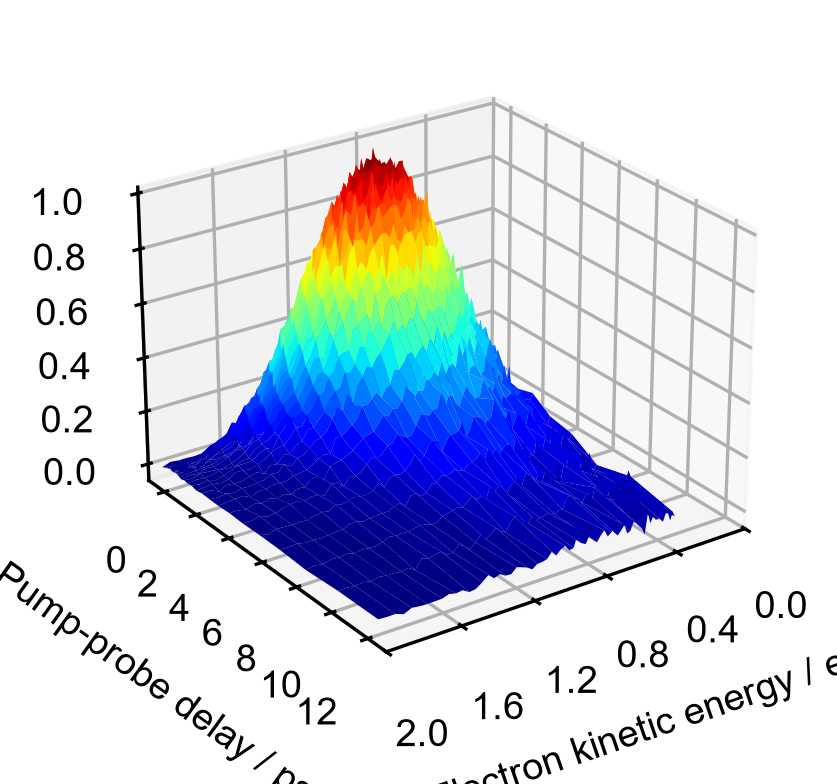

In [30]:
fig = plt.figure(constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
# fig.set_dpi(1000)

ax.set_xlim(0,2)
ax.set_ylim(-1,13)

x,y = scanSet.energies_rebinned, scanSet.delays
# Mask data outside of xlims and ylims
xmask = np.logical_and(x>ax.get_xlim()[0],x<ax.get_xlim()[1])
ymask = np.logical_and(y>ax.get_ylim()[0],y<ax.get_ylim()[1])
x = x[xmask]
y = y[ymask]
Z = scanSet.subtracted_rebinned.T[np.ix_(xmask,ymask)].T

X, Y = np.meshgrid(x,y)

ax.plot_surface(X,Y,Z,
                cmap='jet',)

ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")
ax.set_zlabel("Photoelectron signal / a.u.")

ax.xaxis.set_major_locator(MultipleLocator(.4))
ax.yaxis.set_major_locator(MultipleLocator(2))
ax.zaxis.set_major_locator(MultipleLocator(.2))

ax.view_init(elev=25, azim=55, roll=0)


plt.savefig('Heatmap.png',dpi=fig.dpi,bbox_inches='tight',pad_inches=.5)

### Total counts

In [31]:
def monoexponential_witht0(x,t0,A1,tau1):
    sigma = 0.320 / 2.355 #cross-corrleation with 250 & 267
    
    return A1 * np.exp((-1/tau1)*(x-t0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-t0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))

In [32]:
def biexponential_witht0(x,t0,A1,tau1,A2,tau2):
    sigma = 0.320 * 2.355 #cross-corrleation with 250 & 267
    return monoexponential_witht0(x,t0,A1,tau1)+monoexponential_witht0(x,t0,A2,tau2)

t0, A1, tau1
[-0.196, 0.557, 2.831]
[0.003, 0.003, 0.046]


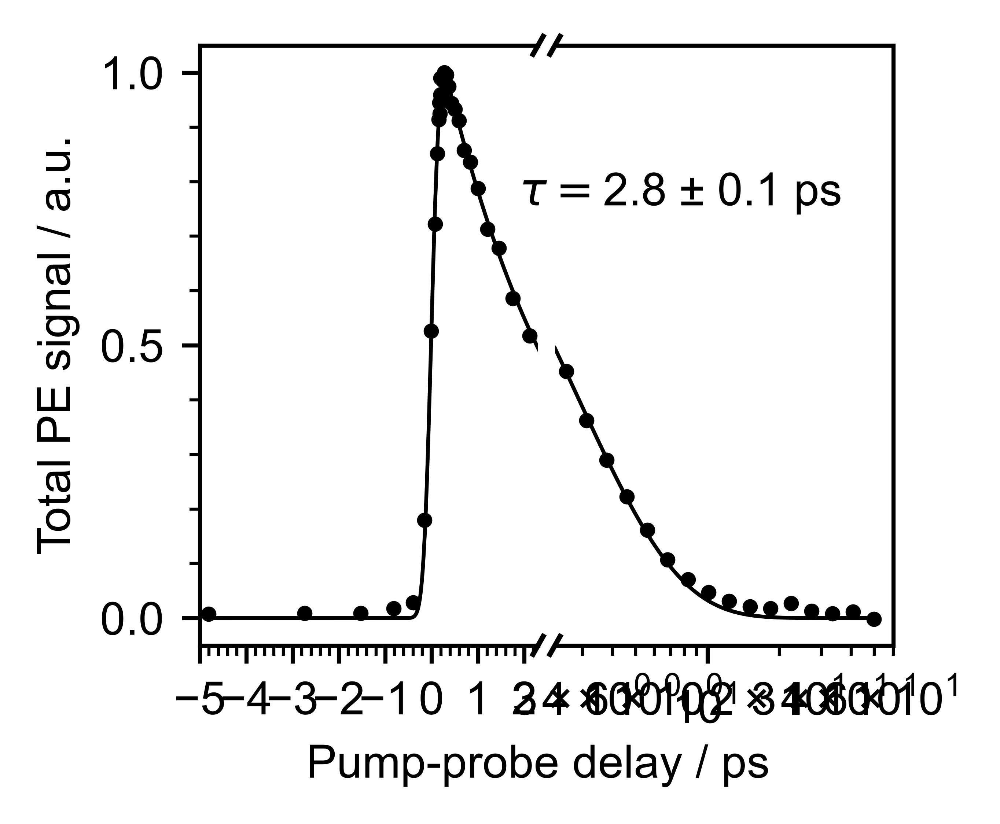

In [33]:
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.54/2.5)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)

delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

params,pcov=curve_fit(monoexponential_witht0,delays,trace,
                  p0=[.5,300,3])
perr = np.sqrt(np.diag(pcov))

t0 = params[0]
# Save t0 to scanSet
scanSet.t0 = params[0]

for ax in axes:
    ax.plot(delays-t0,trace,'ko',ms=2,zorder=100)
    ax.plot(ts-t0,monoexponential_witht0(ts,*params),'k',lw=.75)

print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax0.set_xlim(-5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

for ax in axes:
    ax.set_ylim(-.05,1.05)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

ax1.text(.85,.65,f"$\\tau =${params[2]:.1f} ± {0.1} ps\n",ha='right',transform=ax.transAxes)
   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(1))
ax0.xaxis.set_minor_locator(MultipleLocator(.2))

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\2343003590.py:4: RuntimeWarning: overflow encountered in exp
  return A1 * np.exp((-1/tau1)*(x-t0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-t0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))


t0, A1, tau1, A2, tau2
[-0.194, 0.544, 2.672, 0.015, 31.542]
[0.003, 0.009, 0.084, 0.01, 32.246]


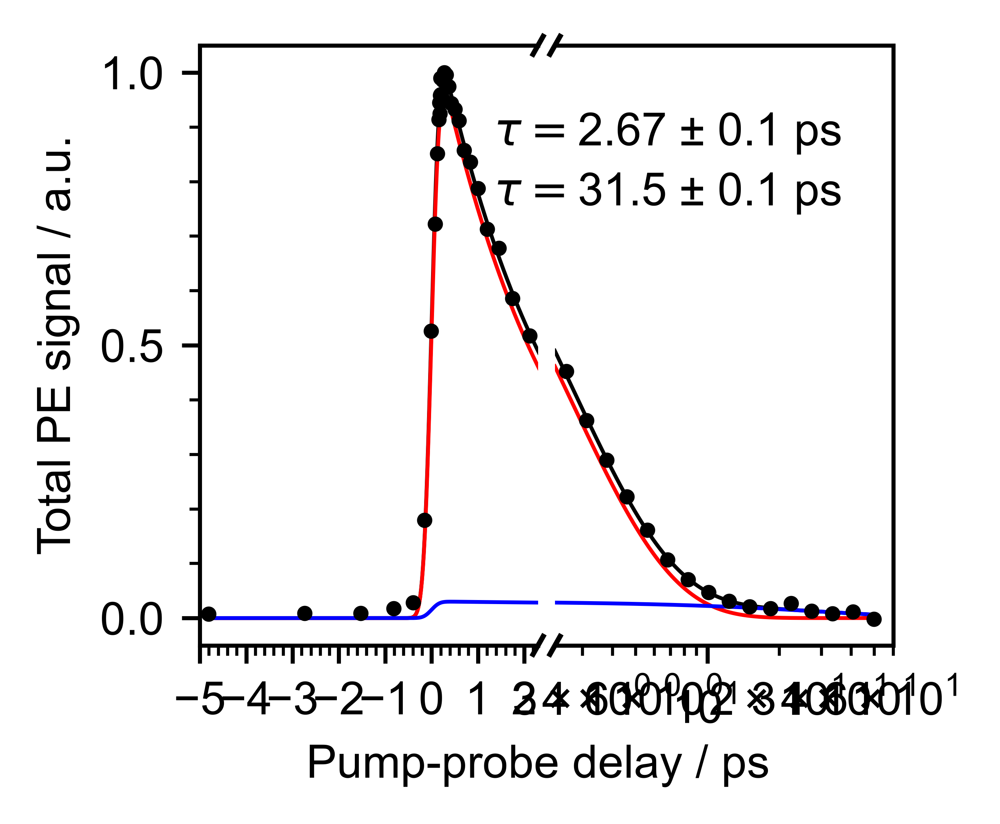

In [34]:
## biexponential
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.54/2.5)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)

delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

params,pcov=curve_fit(biexponential_witht0,delays,trace,
                  p0=[0.066, 0.101, 0.443, 0.495, 3.047],)#bounds=(0,np.inf))
perr = np.sqrt(np.diag(pcov))

t0 = params[0]

for ax in axes:
    ax.plot(delays-t0,trace,'ko',ms=2,zorder=100)
    ax.plot(ts-t0,biexponential_witht0(ts,*params),'k',lw=.75)
    ax.plot(ts-t0,monoexponential_witht0(ts,*params[:3]),'r',lw=.75)
    ax.plot(ts-t0,monoexponential_witht0(ts,t0,*params[3:]),'b',lw=.75)
    
print("t0, A1, tau1, A2, tau2")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax0.set_xlim(-5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

for ax in axes:
    ax.set_ylim(-.05,1.05)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

ax1.text(.85,.75,f"$\\tau =${params[2]:.2f} ± {0.1} ps\n",ha='right',transform=ax.transAxes)
ax1.text(.85,.65,f"$\\tau =${params[4]:.1f} ± {0.1} ps\n",ha='right',transform=ax.transAxes)
   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(1))
ax0.xaxis.set_minor_locator(MultipleLocator(.2))


# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

### save subtracted spectra using monoexp t0

In [35]:
# Save subtracted spectra to disk to compare with H2O
save_arr = np.zeros(np.array(scanSet.subtracted_rebinned.shape)+1,
                    dtype=scanSet.subtracted_rebinned.dtype)
save_arr[1:,1:] = scanSet.subtracted_rebinned
save_arr[0,1:] = scanSet.energies_rebinned
save_arr[1:,0] = scanSet.delays-scanSet.t0

np.savetxt("SubtractedSpectraH2O.txt",save_arr)

### Transients

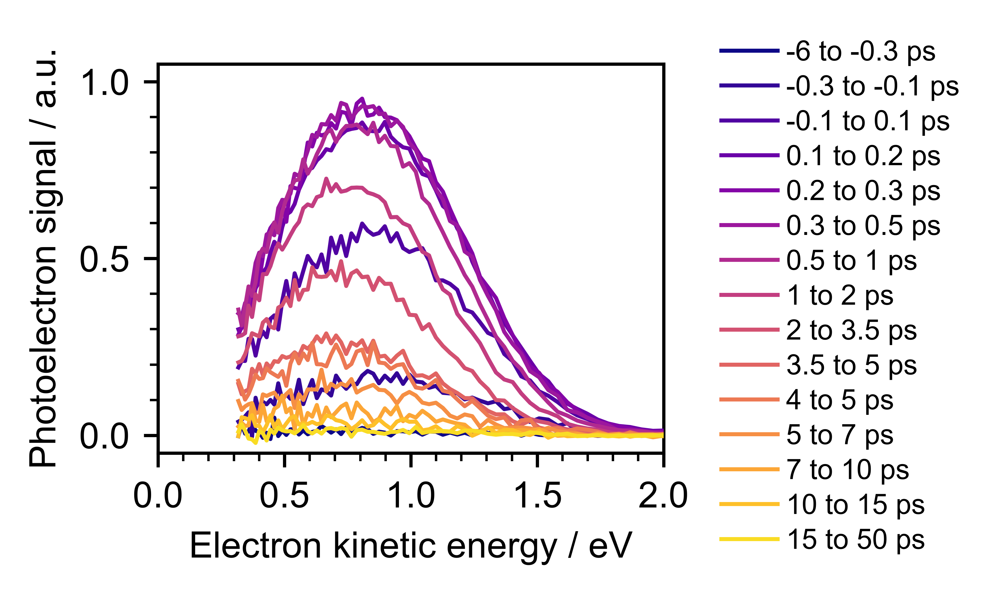

In [36]:
fig,ax = plt.subplots(1)
fig.set_dpi(1000)
fig.set_size_inches(20/3.5/2.54,15.5/2.54/3.5)

t0 = scanSet.t0
delays = scanSet.delays - t0

#Set limits for time ranges
timeRanges = [(-6,-.3),(-.3,-.1),(-.1,.1),(.1,.2),
              (.2,.3),(.3,.5),(.5,1),(1,2),(2,3.5),(3.5,5),(4,5),
              (5,7),(7,10),(10,15),(15,50),
             ]
#Create and normalise color map
cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=len(timeRanges))  # Normalize data from 0 to 100


for ind,timeRange in enumerate(timeRanges):
    #Mask data outside of time range
    mask = (np.logical_and(delays>timeRange[0],delays<=timeRange[1]))
    masked_data = scanSet.subtracted_rebinned[mask] 
    
    #Plot
    ax.plot(scanSet.energies_rebinned,np.mean(masked_data,axis=0),
            label = f"{timeRange[0]} to {timeRange[1]} ps",
            zorder=ind,
            c=cmap(norm(ind)),
           )

#Format
ax.set_xlim(0,2)
ax.set_ylim(-.05,1.05)

ax.set_ylabel("Photoelectron signal / a.u.")
ax.set_xlabel("Electron kinetic energy / eV")
    
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(.1))
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.legend(frameon=False,bbox_to_anchor=[1.35, 0.4], 
           loc='center',ncol=1)

fig.patch.set_alpha(0)

### ADEs

(-0.3, -0.1) ps	S1: 2.89, S0: 6.44
(-0.1, 0.1) ps	S1: 2.60, S0: 6.14
(0.1, 0.2) ps	S1: 2.62, S0: 6.16
(0.2, 0.3) ps	S1: 2.63, S0: 6.17
(0.3, 0.5) ps	S1: 2.56, S0: 6.10
(0.5, 1) ps	S1: 2.51, S0: 6.05
(1, 2) ps	S1: 2.60, S0: 6.14
(2, 3.5) ps	S1: 2.83, S0: 6.37
(3.5, 5) ps	S1: 2.81, S0: 6.35
(4, 5) ps	S1: 2.69, S0: 6.23
(5, 7) ps	S1: 2.64, S0: 6.18
(7, 10) ps	S1: 3.26, S0: 6.80


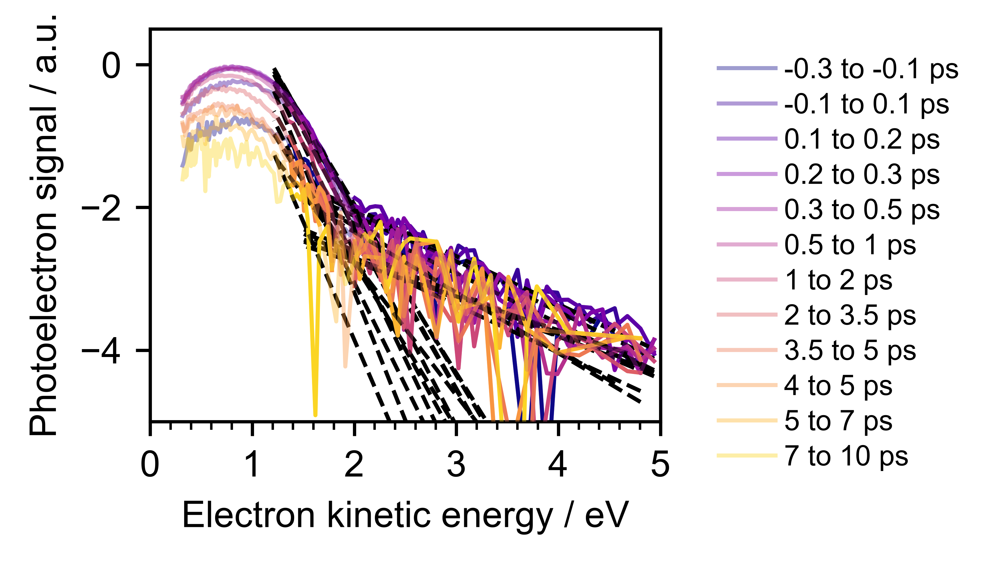

In [37]:
fig,ax = plt.subplots(1)
fig.set_dpi(1000)
fig.set_size_inches(20/3.5/2.54,15.5/2.54/3.5)

t0 = scanSet.t0
delays = scanSet.delays - t0

#Set limits for time ranges
timeRanges = [#(-6,-.3),
              (-.3,-.1),(-.1,.1),(.1,.2),
              (.2,.3),(.3,.5),(.5,1),(1,2),(2,3.5),(3.5,5),(4,5),
              (5,7),(7,10),#(10,15),(15,50),
             ]
# timeRanges = [(-.3,0),(0,.3),(.3,1),(1,3.5),(3.5,5),(5,10),
#               #(10,15),(15,50),
#              ]

#Create and normalise color map
cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=len(timeRanges))  # Normalize data from 0 to 100

ADEs_S0 = []
ADEs_S1 = []
for ind,timeRange in enumerate(timeRanges):
    # if ind <2: continue
    #Mask data outside of time range
    mask = (np.logical_and(delays>timeRange[0],delays<=timeRange[1]))
    masked_data = scanSet.subtracted_rebinned[mask] 
    # Mask for signal >0
    mask = np.mean(masked_data,axis=0)>0
    mean = (np.mean(masked_data,axis=0)[mask])
    # mean/=max(mean)
    # Log
    mean_log = np.log10(mean)
    energies_log = scanSet.energies_rebinned[mask]
    #Plot
    ax.plot(energies_log,mean_log,
            label = f"{timeRange[0]} to {timeRange[1]} ps",
            zorder=ind,
            c=cmap(norm(ind)),
            alpha=.4,
           )
    
    
    #Baseline line
    mask = np.logical_and(energies_log>2,energies_log<5)
    ax.plot(energies_log[mask],mean_log[mask],c=cmap(norm(ind)))
    # mask = np.logical_and(mask,fittableData[1]>0)

    params,_ = curve_fit(lambda x,m,c:m*x+c,energies_log[mask],mean_log[mask])
    m_b,c_b = params
    mask = np.logical_and(energies_log>1.5,mean_log<5)
    ax.plot(energies_log[mask],m_b*energies_log[mask]+c_b,'--',c='k')

    #Rising edge line
    mask = np.logical_and(energies_log>1.35,energies_log<1.8)
    ax.plot(energies_log[mask],mean_log[mask],c=cmap(norm(ind)))
    # mask = np.logical_and(mask,fittableData[1]>0)

    params,_ = curve_fit(lambda x,m,c:m*x+c,energies_log[mask],mean_log[mask])
    m, c = params
    mask = np.logical_and(energies_log>1.2,mean_log<2)
    ax.plot(energies_log[mask],m*energies_log[mask]+c,'--',c='k')
    
    ADE_eKE = (c_b-c)/(m-m_b)
    ADE_S1 = 1*1239.8/266.7-ADE_eKE
    ADE_S0 = 1*1239.8/350+1*1239.8/266.7-ADE_eKE
    print(f"{timeRange} ps\tS1: {ADE_S1:.2f}, S0: {ADE_S0:.2f}")
    
    ADEs_S0.append((np.mean(timeRange),ADE_S0))
    ADEs_S1.append((np.mean(timeRange),ADE_S1))
    # if ind==2:
    #     break
ADEs_S0 = np.array(ADEs_S0)
ADEs_S1 = np.array(ADEs_S1)
#Format
ax.set_xlim(0,5)
ax.set_ylim(-5,0.5)
ax.set_ylabel("Photoelectron signal / a.u.")
ax.set_xlabel("Electron kinetic energy / eV")
    
# ax.yaxis.set_major_locator(MultipleLocator(.5))
# ax.yaxis.set_minor_locator(MultipleLocator(.1))
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(.2))
ax.legend(frameon=False,bbox_to_anchor=[1.35, 0.4], 
           loc='center',ncol=1)

fig.patch.set_alpha(0)


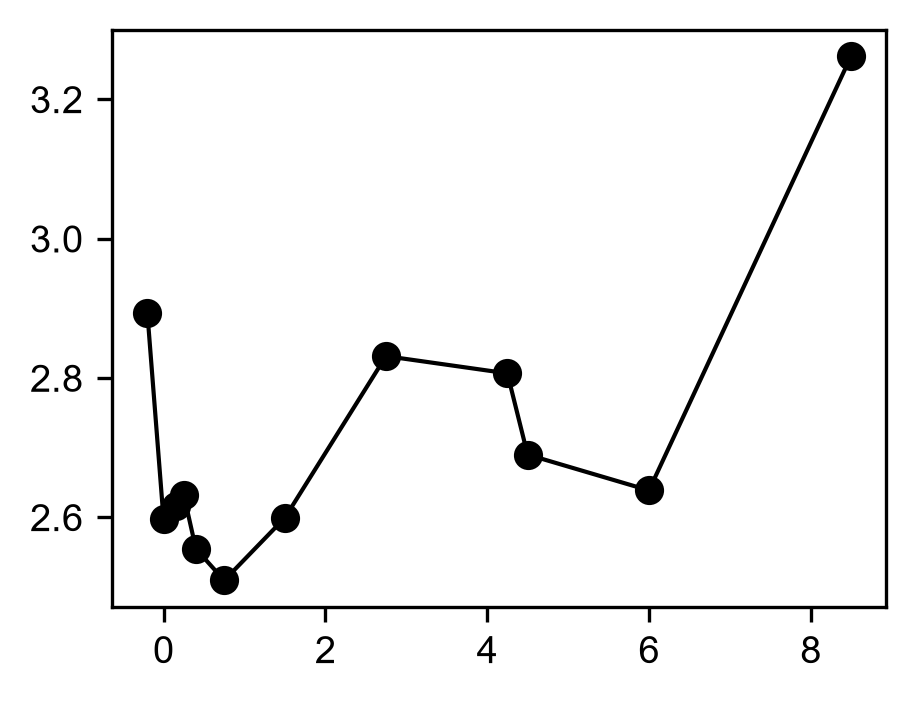

In [38]:

# plt.plot(*ADEs_S0.T,'ko-')
plt.plot(*ADEs_S1.T,'ko-')

### Retrieval

In [39]:
def rebinData(data,min_eKE = 0, x_bins = None,nanWarningSuppress = False):
    # Default bin edges if none selected
    if x_bins is None:
        x_bins = np.arange(0.00,5.01,0.01)

    # Get indices of the bins to which each value in x belongs
    bin_indices = np.digitize(data[0],x_bins)
    # !: This returns 1-based indices, i.e. the indices of the right edges
    #So you must subtract 1
    bin_indices -= 1
    
    # Bin y values according to bin_indices and average them
    binned_y = x_bins[1:]*0
    for i, bin in enumerate(binned_y):
        binned_y[i] = np.mean(data[1][bin_indices==i])

    # Remove data below min_eKE for retrieval fit
    binned_x = x_bins[1:][x_bins[1:]>min_eKE]
    binned_y = binned_y[x_bins[1:]>min_eKE]

    #If no value is present between 2 bins nan will be returned
    #However nan cannot be used in the fit
    # one way around is to interpolate thedata where nans are present
    # Otherwise we can set the data above the first nan to 0
    # As they appear at high eKEs only
    if any(np.isnan(binned_y)):
        #Find min x value with corresponidng y = nan
        min_nan_x = min(binned_x[np.isnan(binned_y)])
        if not nanWarningSuppress:
            print(f"'nan' values present above {min_nan_x:.2f}. y set ot 0 where y ='nan' above this value.")
        #Remove data above first nan
        binned_y[np.isnan(binned_y)] = 0
    
    return np.asarray((binned_x,binned_y))



#### Retrieve

In [40]:
scanSet.delays[5],scanSet.delays[41]

(np.float64(-0.34623953081570447), np.float64(18.161230727158614))

Cross-section set: 1b
Escape threshold: 1.0 eV
Concentration profile G amplitude: 4.6
Surface gaussians: 5
--------


C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


-0.15 ps [0.1025, 0.9983, 0.7991] [(7.19, 3.65)]
	G fit: [0.13, 0.88, 0.91]
-0.01 ps [0.3059, 0.9643, 0.8182] [(7.23, 3.68)]
	G fit: [0.39, 0.85, 0.91]
0.08 ps [0.4367, 0.9709, 0.7745] [(7.22, 3.68)]
	G fit: [0.54, 0.86, 0.88]
0.13 ps [0.5197, 0.9577, 0.7819] [(7.23, 3.69)]
	G fit: [0.64, 0.85, 0.88]
0.16 ps [0.565, 0.9473, 0.7805] [(7.24, 3.7)]
	G fit: [0.69, 0.84, 0.87]
0.17 ps [0.5911, 0.9535, 0.7666] [(7.24, 3.7)]
	G fit: [0.72, 0.84, 0.87]
0.18 ps [0.5747, 0.9483, 0.776] [(7.24, 3.7)]
	G fit: [0.7, 0.84, 0.87]
0.19 ps [0.5797, 0.9495, 0.7865] [(7.24, 3.7)]
	G fit: [0.71, 0.84, 0.88]
0.19 ps [0.5912, 0.9465, 0.7861] [(7.24, 3.7)]
	G fit: [0.73, 0.84, 0.87]
0.19 ps [0.5937, 0.9364, 0.7926] [(7.26, 3.71)]
	G fit: [0.73, 0.83, 0.88]
0.20 ps [0.6077, 0.9389, 0.7944] [(7.25, 3.71)]
	G fit: [0.75, 0.83, 0.87]
0.22 ps [0.6037, 0.9406, 0.7727] [(7.25, 3.71)]
	G fit: [0.74, 0.83, 0.86]
0.25 ps [0.6148, 0.9405, 0.7833] [(7.25, 3.71)]
	G fit: [0.75, 0.83, 0.87]
0.28 ps [0.6377, 0.9401, 0.7671

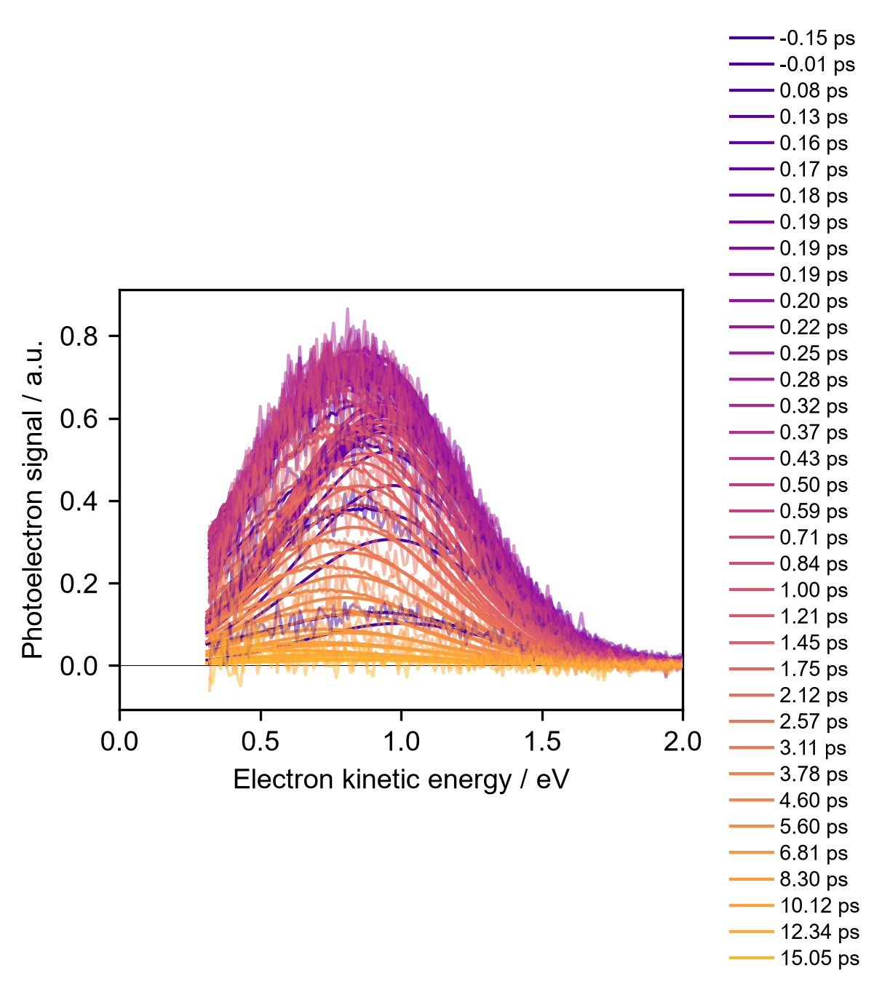

In [41]:
fig,ax = plt.subplots(1)
# ax0,ax1 = axes

#Retrieval parameters
all_params = [] 
all_perrs = [] 
#Gaussian fit parameters
all_params_gau = [] 
all_perrs_gau = [] 

#T0
t0 = scanSet.t0

xs = np.arange(0.01,5.01,0.01)
crossSectionSetInd = 0
thresholdInd = 6
surfInd = 6
num_surface = 5
num_bulk = 5

print(f"Cross-section set: {crossSectionSets[crossSectionSetInd]}")
print(f"Escape threshold: {E0s[thresholdInd]} eV")
print(f"Concentration profile G amplitude: {concAmps[surfInd]}")
print(f"Surface gaussians: {num_surface}")
print('-'*8)

cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=48)  # Normalize data 

# Change range to include more or less spectra.
# Those at negative and long delays will not fit so they
# are usually excluded
for ind in range(5,41): 

    fittableData = np.array((scanSet.energies,
                             scanSet.subtracted[ind]))

    #----------RETRIEVE-----------
    # Pick surface and bulk basis functions 
    surf_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,surfInd]
    bulk_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,0]
    surf_bas /= np.amax(surf_bas)

    #Rebin data ontoo 0.01 eV grid and cutoff below low eKE cutoff
    min_eKE = min(fittableData[0])
    rebinnedData = rebinData(fittableData,min_eKE,nanWarningSuppress=True)
    x_above_cutoff,y_above_cutoff = rebinnedData

    #Create fit functions with basis functions and min_eKE
    fitfunc = JetFitFunc(num_surface,num_bulk, surf_bas, bulk_bas, min_eKE)
    #Fit
    params,pcov = curve_fit(fitfunc.f, xs, y_above_cutoff,
                             p0 = [1,.9,1],
                             bounds = (0,np.inf)
                             )
    #Get errors of fit
    perrs = np.sqrt(np.diag(pcov))

    #Plot data
    ax.plot(x_above_cutoff,y_above_cutoff,
            zorder=ind,
            c=cmap(norm(ind)),
            alpha=.5
           )

    #Plot fit
    ax.plot(x_above_cutoff, fitfunc.f(xs, *params),
            c=cmap(norm(ind)),
            label = f"{scanSet[0].delayTimes[ind]-t0:.2f} ps",
           )
    #Plot retrieval
    ax.plot(spectrum[0],multiple_gaussians(spectrum[0],*params),
            c=cmap(norm(ind)))

    
    print(f"{scanSet[0].delayTimes[ind]-t0:.2f} ps",[float(f"{p:.4f}") for p in params], end=' ')
    # print([float(f"{p:.3f}") for p in params[1::3]])
    print([(float(f"{1239.8/350 + 1239.8/266.67 - p:.2f}"),float(f"{1239.8/266.67 - p:.2f}")) for p in params[1::3]])
    all_params.append([scanSet[0].delayTimes[ind]-t0,]+list(params))
    all_perrs.append([scanSet[0].delayTimes[ind]-t0,]+list(perrs))

    #-----------------Fit GAUSSIAN---------------
    params,pcov= curve_fit(multiple_gaussians,
                        fittableData[0],fittableData[1],
                        p0 = [1,.9,1],
                       bounds=[0,np.inf])
    perrs = np.sqrt(np.diag(pcov))
    all_params_gau.append([scanSet[0].delayTimes[ind]-t0,]+list(params))
    all_perrs_gau.append([scanSet[0].delayTimes[ind]-t0,]+list(perrs))
    print("\tG fit:", [float(f"{p:.2f}") for p in params])

all_params = np.array(all_params)
all_perrs = np.array(all_perrs)
all_params_gau = np.array(all_params_gau)
all_perrs_gau = np.array(all_perrs_gau)

ax.hlines(0,0,5,'k',lw=.25)

ax.set_xlim(0,2)

ax.set_ylabel("Photoelectron signal / a.u.")
ax.set_xlabel("Electron kinetic energy / eV")
    
# ax.yaxis.set_major_locator(MultipleLocator(.5))
# ax.yaxis.set_minor_locator(MultipleLocator(.1))
# ax.xaxis.set_major_locator(MultipleLocator(.5))
# ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.legend(frameon=True,facecolor='white', framealpha=1,edgecolor='white')
ax.legend(frameon=False,bbox_to_anchor=[1.2, 0.5], 
           loc='center')


#### Mean eKE of retrieved data

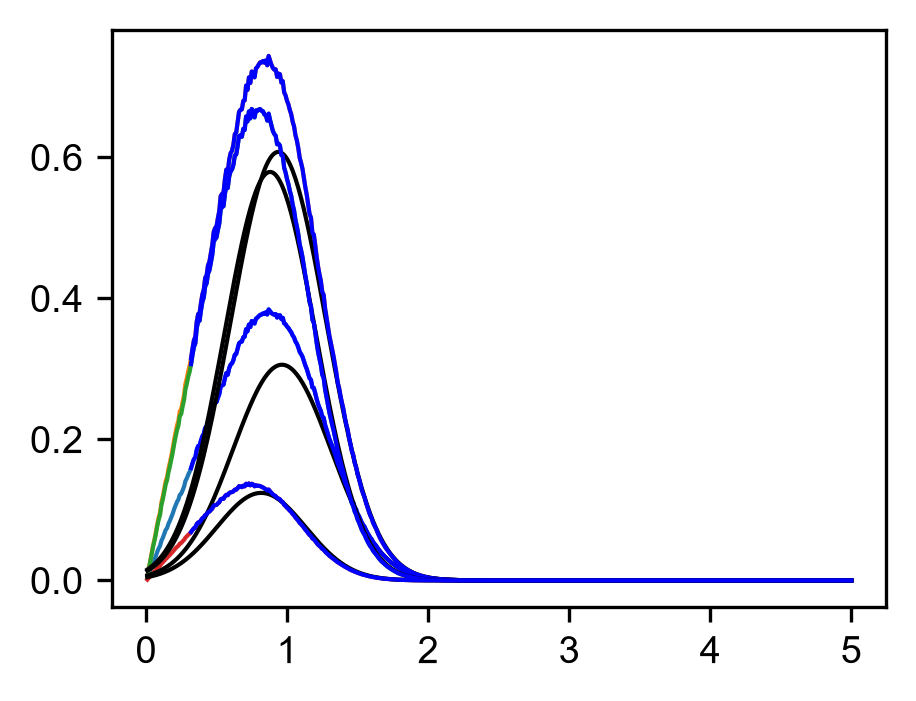

In [42]:
for i in (1,10,20,30):
    params = all_params[i]

    y_tmp = multiple_gaussians(xs, *params[1:])

    plt.plot(xs,multiple_gaussians(xs, *params[1:]),'k')
    # plt.plot(x_above_cutoff,multiple_gaussians(x_above_cutoff, *params[1:]))
    plt.plot(x_above_cutoff,fitfunc.f(xs,*params[1:]),'b')


    plt.plot(xs,np.sum(surf_bas.T * y_tmp, axis=1),zorder=0)

(np.float64(106.52968462343907), np.float64(1.0))

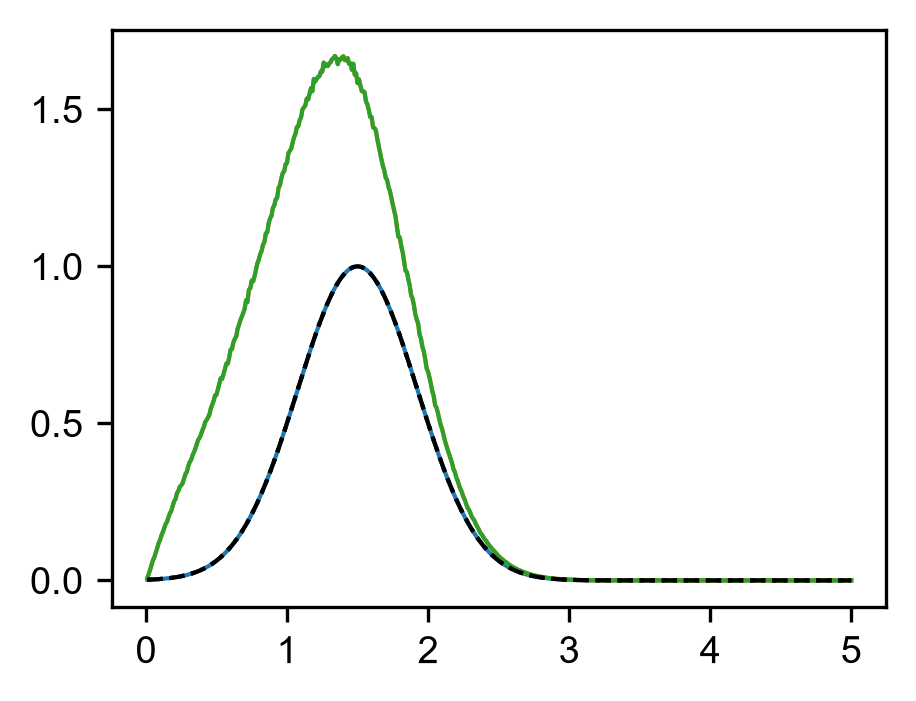

In [43]:
temp_surf_bas = np.copy(surf_bas)
temp_surf_bas[:300] = 0
temp_surf_bas[360:] = 0
# plt.plot(xs,np.sum(temp_surf_bas,axis=0))

y_tmp = multiple_gaussians(xs, 1,1.5,1.001)
plt.plot(xs,y_tmp,zorder=0)
scattered = np.sum(surf_bas.T * y_tmp, axis=1)
plt.plot(xs,scattered,zorder=0)

scattered1 = surf_bas.T @ y_tmp
plt.plot(xs,scattered1,zorder=0)


# scattered = surf_bas.T @ y_tmp      # project onto basis
scatered = scattered = np.linalg.solve(surf_bas, y_tmp)
unscattered = surf_bas @ scattered   #reconstruct signal
plt.plot(xs,unscattered,':',zorder=0,c='k')


scattered = np.linalg.solve(surf_bas, y_tmp)
unscattered = surf_bas @ scattered   #reconstruct signal
plt.plot(xs,unscattered,'--',zorder=0,c='k')

# plt.xlim(1.4,1.6)
np.sum(unscattered),np.sum(multiple_gaussians(xs, 1,1.5,0.001))


Text(0, 0.5, 'E$_f$')

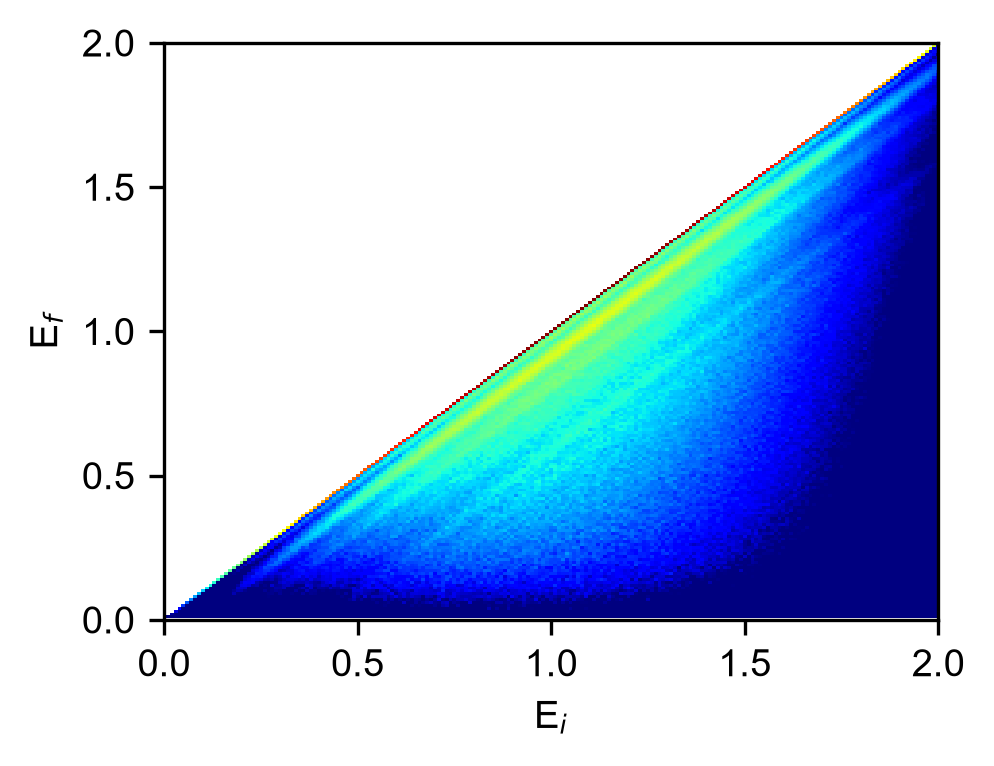

In [44]:
y_tmp = multiple_gaussians(xs, 1,1,1)

bas_gau = surf_bas.T * y_tmp
cutoff = 0.
bas_gau[xs<cutoff,:] = 0

plt.pcolormesh(xs,xs,bas_gau,
               cmap='jet',
               norm=mcolors.LogNorm(vmin=.001),
               
)
scattered.shape
plt.xlim(0,2)
plt.ylim(0,2)
plt.xlabel('E$_i$')
plt.ylabel('E$_f$')

np.float64(0.9979193577896105)

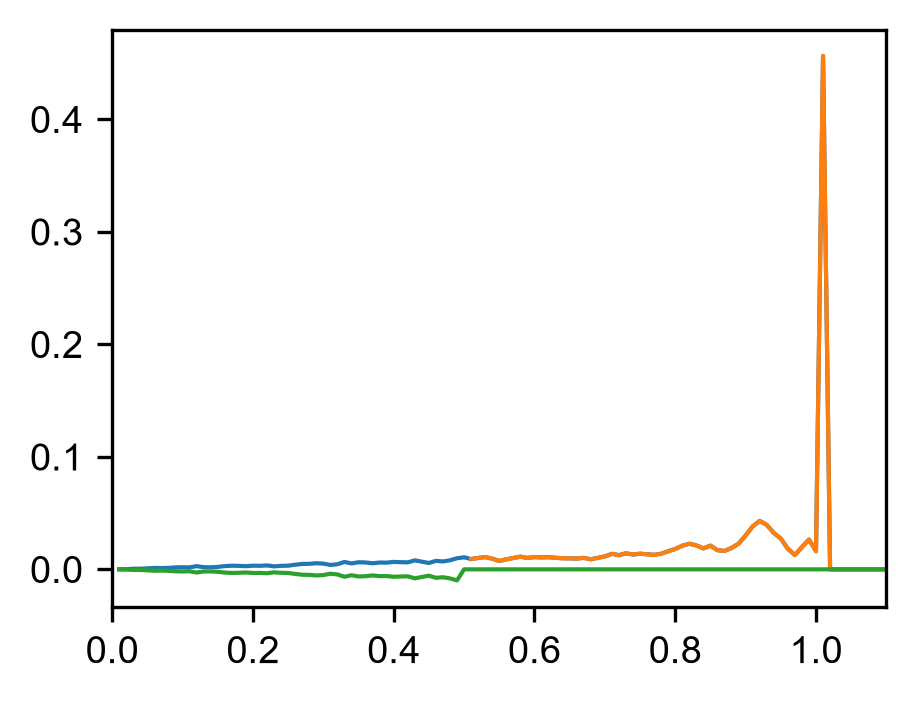

In [45]:
plt.plot(xs,surf_bas[100])
cutoff=.5
plt.plot(xs[xs>cutoff],surf_bas[100][xs>cutoff])
b = np.sum(surf_bas[100])*0.01
b_cut = np.sum(surf_bas[100][xs>cutoff])*0.01
a_cut = b_cut+1-b

cut_dist = np.copy(surf_bas[100])
cut_dist[xs<cutoff]=0

plt.plot(xs,cut_dist-surf_bas[100])

plt.xlim(0,1.1)
a_cut

Text(1.1, 0, 'Electron kinetic energy / eV')

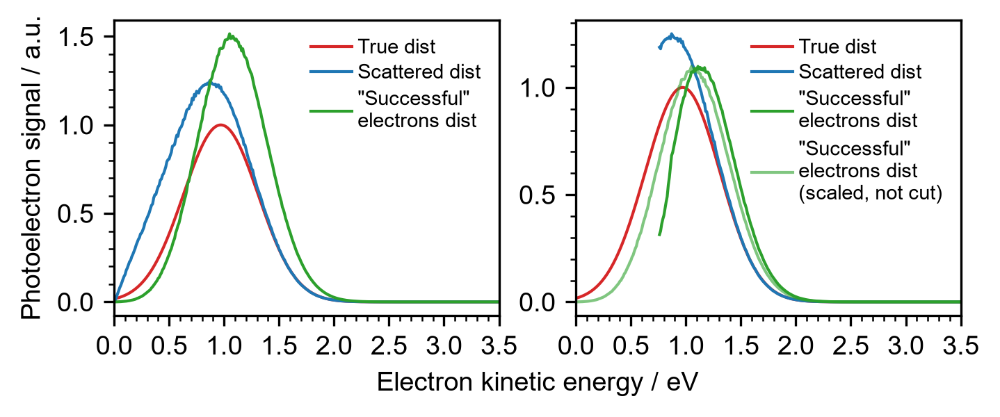

In [46]:
fig,axes = plt.subplots(1,2)
fig.set_size_inches(thesisWid*.95,thesisWid/2/1.5)

ax0,ax1 = axes
y_tmp = multiple_gaussians(xs,1,.97,.8)
bas_gau = surf_bas.T * y_tmp
ax0.plot(xs,y_tmp,'tab:red',label='True dist')
ax0.plot(xs,np.sum(bas_gau,axis=1),'tab:blue',label='Scattered dist')
ax0.plot(xs,np.sum(bas_gau,axis=0),'tab:green',label='"Successful"\nelectrons dist')

norm = max(np.sum(bas_gau,axis=0))

mask = xs>.75
bas_gau_cut = np.copy(bas_gau)
bas_gau_cut[~mask,:] = 0
ax1.plot(xs,y_tmp,'tab:red',label='True dist')
ax1.plot(xs[mask],np.sum(bas_gau_cut,axis=1)[mask],'tab:blue',label='Scattered dist')
ax1.plot(xs[mask],np.sum(bas_gau_cut,axis=0)[mask],'tab:green',label='"Successful"\nelectrons dist')

ax1.plot(xs,np.sum(bas_gau,axis=0)/max(np.sum(bas_gau,axis=0))*max(np.sum(bas_gau_cut,axis=0)),
         'tab:green',alpha=.6,label='"Successful"\nelectrons dist\n(scaled, not cut)')

ax = plt.gca()
for ax in axes:
    ax.legend()
    ax.set_xlim(0,3.5)


    ax.yaxis.set_major_locator(MultipleLocator(.5))
    ax.yaxis.set_minor_locator(MultipleLocator(.1))
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax0.set_ylabel("Photoelectron signal / a.u.")
ax0.set_xlabel("Electron kinetic energy / eV",x=1.1)


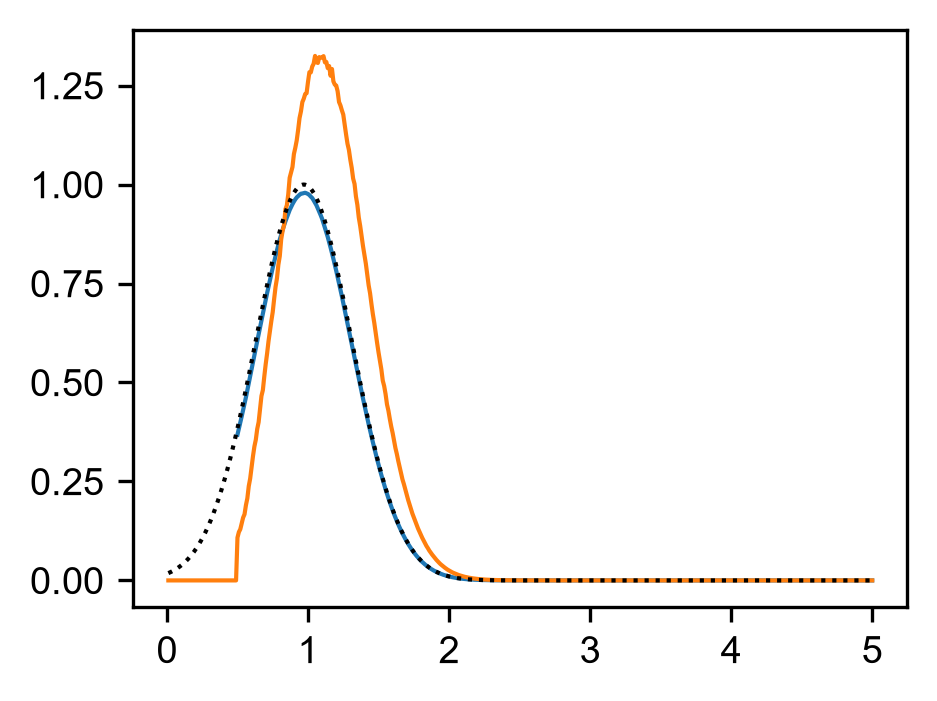

In [47]:
y_tmp = multiple_gaussians(xs,1,.97,.8)
bas_gau = surf_bas.T * y_tmp
mask = xs<.5
bas_gau[mask,:] = 0

recovered = y_tmp+np.sum(bas_gau,axis=0)-y_tmp*np.sum((surf_bas.T),axis=0)
# plt.plot(xs,recovered)
# plt.plot(xs[~mask],recovered[~mask])
recovered = 10*y_tmp+np.sum(bas_gau,axis=0)-y_tmp*np.sum((surf_bas.T),axis=0)
plt.plot(xs[~mask],recovered[~mask]/10)
# plt.plot(xs,recovered/max(recovered))
plt.plot(xs,np.sum(bas_gau,axis=0))

# for cutoff in 0,0.5,1:
#     bas_gau = surf_bas.T * y_tmp
#     mask = xs<cutoff
#     bas_gau[mask,:] = 0
#     plt.plot(xs[~mask],np.sum(bas_gau,axis=0)[~mask])

plt.plot(xs,y_tmp,'k:')

False


(500, 500)

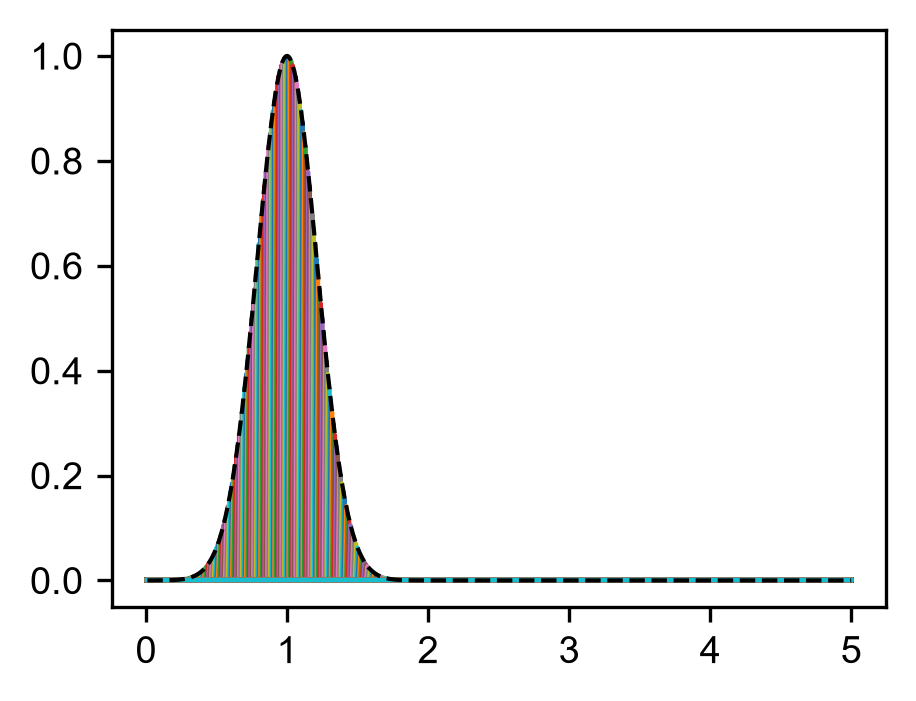

In [48]:
y_tmp = multiple_gaussians(xs, 1,1,.5)

cutoff = 0

 # multiply by surf_bas
bas_gau = surf_bas.T * y_tmp

# apply cutoff safely
cutoff = 0
mask = xs < cutoff
bas_gau = np.where(mask[:, None], 0, bas_gau)

# recover
recovered_y_tmp = np.linalg.inv(surf_bas.T) @ bas_gau

# check
if cutoff < xs.min():
    print(np.allclose(recovered_y_tmp, y_tmp))  # True
else:
    print("Cutoff affected y_tmp; recovered_y_tmp differs")
    
    
plt.plot(xs,recovered_y_tmp)
plt.plot(xs,y_tmp,'k--')
recovered_y_tmp.shape

#### Create retrieval dataset

In [49]:
# .. Create retrieved dataset

scanSet.subtracted_retrieved = np.zeros((len(all_params),len(x_above_cutoff)))
scanSet.subtracted_fit = np.zeros((len(all_params),len(x_above_cutoff)))
scanSet.subtracted_retrieved_full = np.zeros((len(all_params),len(xs)))

for i,params in enumerate(all_params):
    # Fit
    scanSet.subtracted_fit[i] = fitfunc.f(xs, *params[1:])
    # Retrieved above cutoff
    scanSet.subtracted_retrieved[i] = multiple_gaussians(x_above_cutoff, *params[1:])  
    # Retrieved full
    scanSet.subtracted_retrieved_full[i] = multiple_gaussians(xs, *params[1:])  

#Normalise dataset as absolute intensity is already scaled
scanSet.subtracted_retrieved/=np.amax(scanSet.subtracted_retrieved)
#Normalise dataset as absolute intensity is already scaled
scanSet.subtracted_retrieved_full/=np.amax(scanSet.subtracted_retrieved_full)
#Save delays of retrieved/fit spectra
scanSet.delays_retrieved = all_params[:,0]
#Save eKEs of retrieved/fit spectra
scanSet.energies_retrieved = x_above_cutoff
scanSet.energies_retrieved_full = xs
# Save fit parameters
scanSet.params_retrieved = all_params[:,1:]

#### Create rebinned dataset

In [50]:
# .. Create  dataset rebinned onto grid

scanSet.subtracted_grid = np.zeros((len(all_params),len(x_above_cutoff)))

for i,ind in enumerate(range(5,41)): 
    fittableData = np.array((scanSet.energies,
                             scanSet.subtracted[ind]))
    min_eKE = min(fittableData[0])
    rebinnedData = rebinData(fittableData,min_eKE,nanWarningSuppress=True)

    scanSet.subtracted_grid[i] = rebinnedData[1]


#### Retrieved heatmap

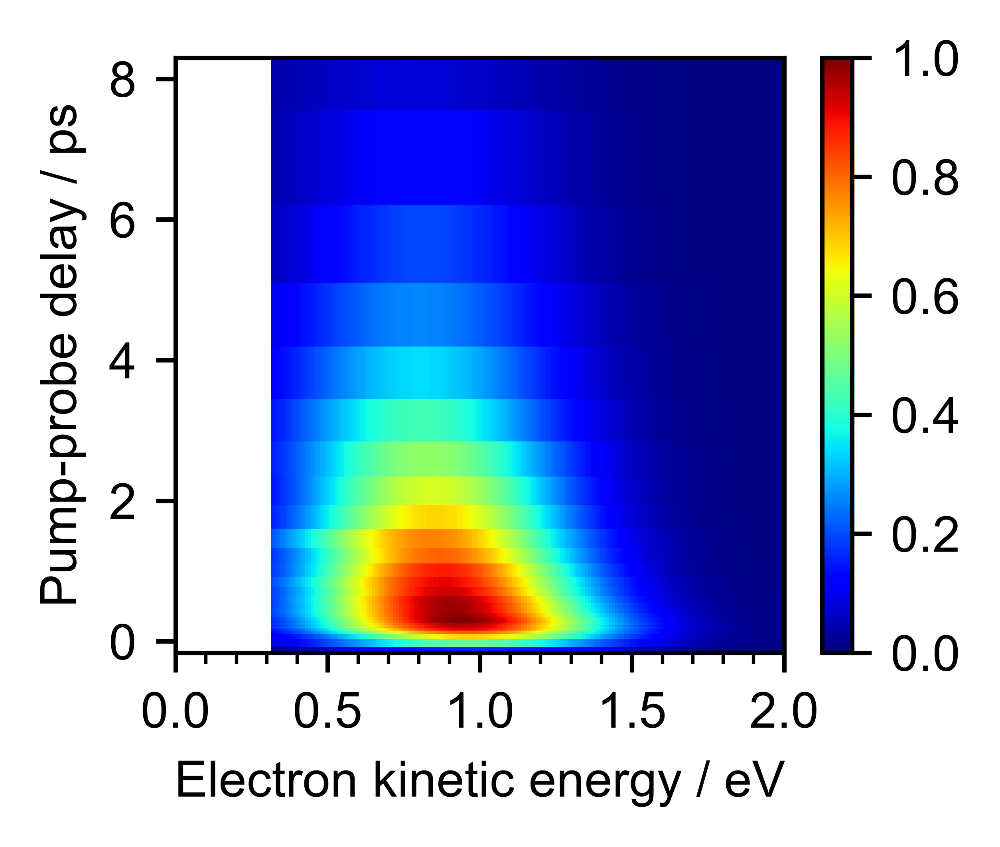

In [51]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)


im0 = ax.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_retrieved,
                    cmap='jet',
                    # shading='gouraud',
                    vmin=0

                   )
# ax.plot(scanSet.params_retrieved[:,1],scanSet.delays_retrieved,'o-',c='w',ms=1,alpha=1)


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
# ax.set_yscale('log')
# ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
# ax.yaxis.set_major_locator(MultipleLocator(1))
# ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

#### Fit heatmap

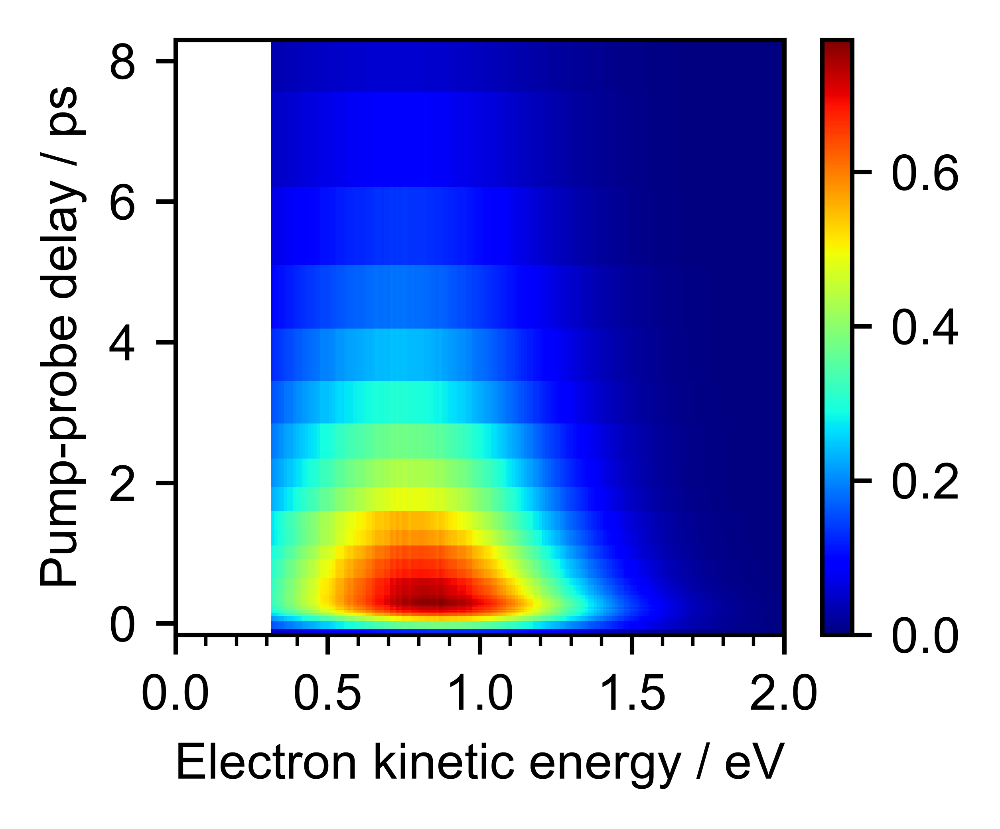

In [52]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)


im0 = ax.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_fit,
                    cmap='jet',
                    # shading='gouraud',
                    # vmin=-1

                   )


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
# ax.set_yscale('log')
# ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
# ax.yaxis.set_major_locator(MultipleLocator(1))
# ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

#### Rebinned onto grid heatmap

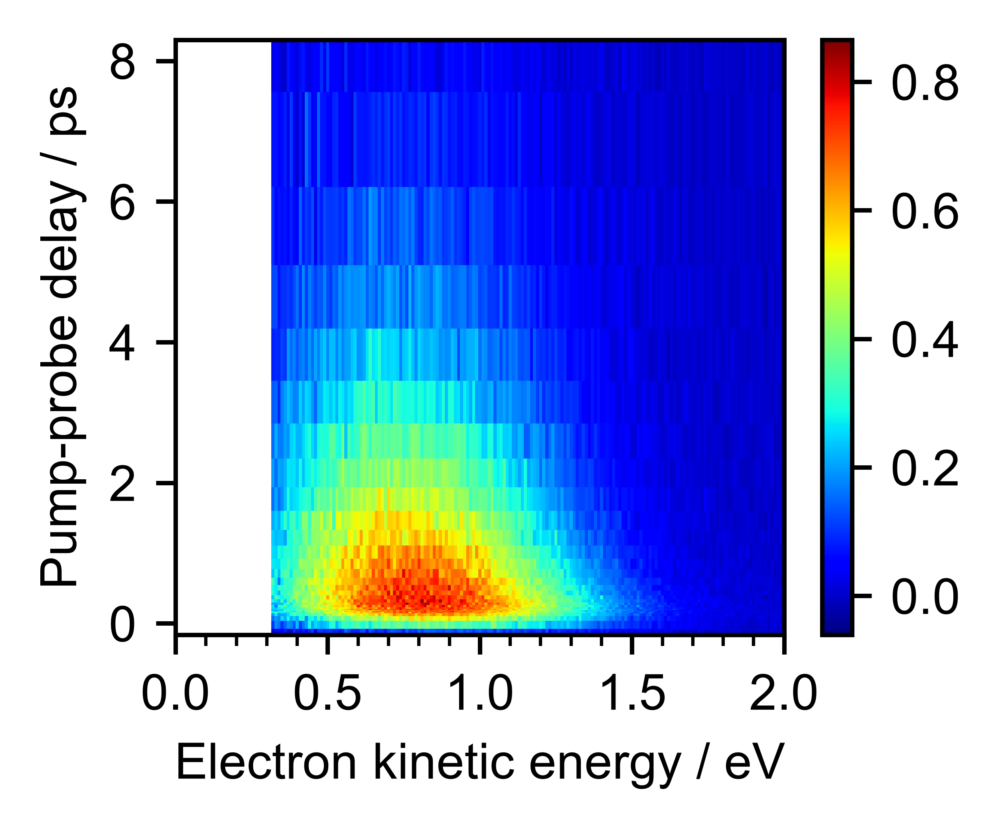

In [53]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)


im0 = ax.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_grid,
                    cmap='jet',
                    # shading='gouraud',
                    # vmin=-1

                   )


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
# ax.set_yscale('log')
# ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
# ax.yaxis.set_major_locator(MultipleLocator(1))
# ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

#### Residuals heatmap

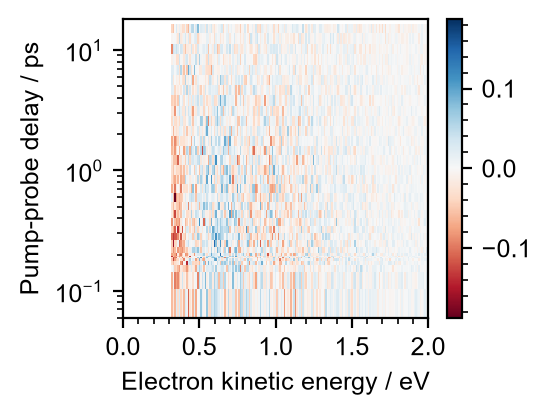

In [54]:
fig,ax = plt.subplots()
fig.set_dpi(200)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

im0 = ax.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_grid-scanSet.subtracted_fit,
                    cmap='RdBu',
                    #center color normalisation around 0
                    norm=mcolors.CenteredNorm()
                    # shading='gouraud',

                   )


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
ax.set_yscale('log')
ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
# ax.yaxis.set_major_locator(MultipleLocator(1))
# ax.yaxis.set_minor_locator(MultipleLocator(.2))
cbar = plt.colorbar(im0)
cbar.ax.yaxis.set_major_locator(MultipleLocator(.1))
cbar.ax.yaxis.set_minor_locator(MultipleLocator(.02))
plt.savefig('Residuals/Residuals_singleG_H2O.png',dpi=fig.dpi,bbox_inches='tight')


#### Total area

t0, A1, tau1
[0.016, 0.556, 3.315]
[0.003, 0.009, 0.084, 0.01, 32.246]
t0, A1, tau1
[-0.196, 0.557, 2.831]
[0.003, 0.003, 0.046]


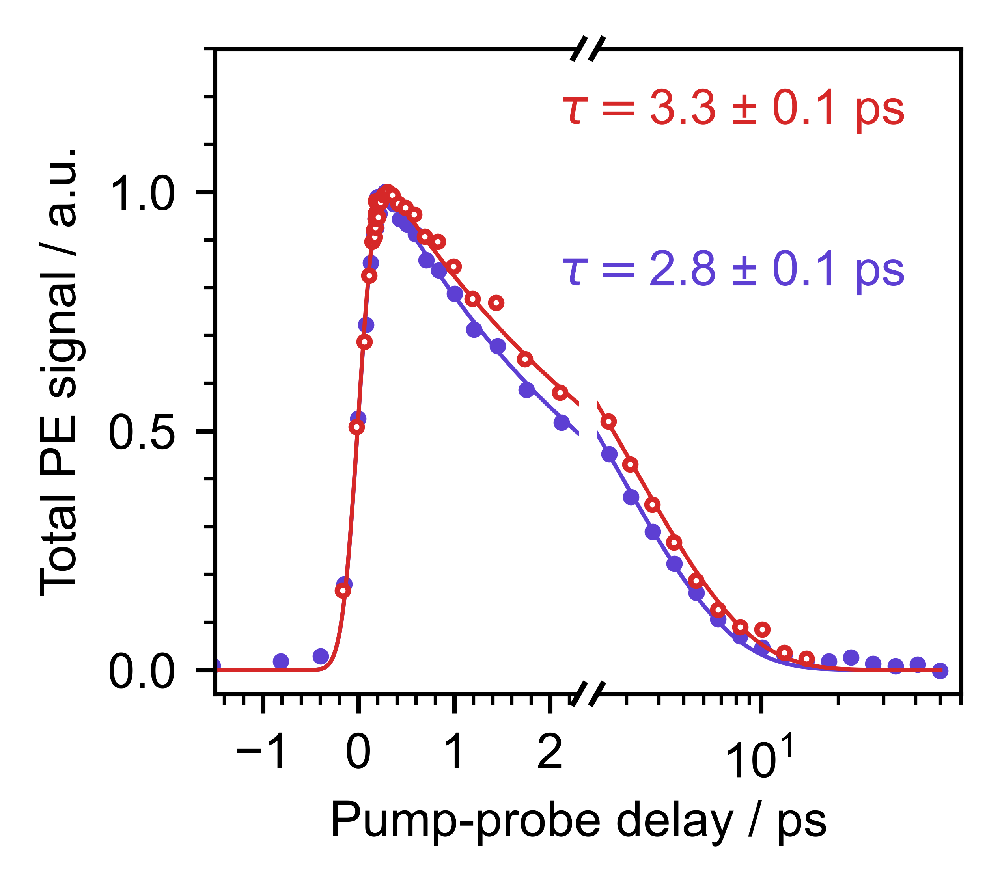

In [55]:
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(1000)
fig.set_size_inches(15.5/2.5/2.54,13.5/2.54/2.5)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)


delays = scanSet.delays_retrieved
trace = scanSet.params_retrieved[:,0]*scanSet.params_retrieved[:,2]
trace/=max(trace)

params,pcov=curve_fit(monoexponential_witht0, delays, trace,
                  p0=[0,1,3])

t0=params[0]

for ax in axes:
    ax.plot(delays-t0,trace,'o',c=red,markerfacecolor='w',ms=2,zorder=100)
    ax.plot(ts-t0,monoexponential_witht0(ts,*params),red,lw=.75)
    
    
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
    
ax1.text(.85,.8,f"$\\tau =${params[2]:.1f} ± {0.1} ps\n",ha='right',c=red,transform=ax.transAxes)

#### Total counts
delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

params,pcov=curve_fit(monoexponential_witht0,delays,trace,
                  p0=[.5,300,3])
perr = np.sqrt(np.diag(pcov))

t0 = params[0]
# Save t0 to scanSet
for ax in axes:
    ax.plot(delays-t0,trace,'o',c=violet,ms=2,zorder=0)
    ax.plot(ts-t0,monoexponential_witht0(ts,*params),c=violet,lw=.75,zorder=0)
       
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax1.text(.85,.55,f"$\\tau =${params[2]:.1f} ± {0.1} ps\n",c=violet,ha='right',transform=ax.transAxes)

### 
    
#Formatting
for ax in axes:
    ax.set_ylim(-.05,1.3)

ax0.set_xlim(-1.5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(1))
ax0.xaxis.set_minor_locator(MultipleLocator(.2))

ax1.xaxis.set_minor_formatter(NullFormatter())

# ax1.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto'))
# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

    
fig.patch.set_alpha(0)

#### Retrieve constrained

This doesn't change much. It just gets the large delays data to be closer ot the previous values but it is too noisy so its still not good enough

In [56]:
(min(scanSet.params_retrieved[:,1][scanSet.params_retrieved[:,1]>0.54]),
 max(scanSet.params_retrieved[:,1]),
 min(scanSet.params_retrieved[:,2]),
 max(scanSet.params_retrieved[:,2]))

bounds = np.array(((0,np.inf),
                   (0.77*0.9,1.00*1.1),
                   (0.70*0.9,1.12*1.1),)).T

Cross-section set: 1b
Escape threshold: 1.0 eV
Concentration profile G amplitude: 4.6
Surface gaussians: 5
--------


C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


[0.1, 1.0, 0.8] [7.19]
[0.13, 0.88, 0.91]
[0.31, 0.96, 0.82] [7.23]
[0.39, 0.85, 0.91]
[0.44, 0.97, 0.78] [7.22]
[0.54, 0.86, 0.88]
[0.52, 0.96, 0.78] [7.23]
[0.64, 0.85, 0.88]
[0.57, 0.95, 0.78] [7.24]
[0.69, 0.84, 0.87]
[0.59, 0.95, 0.77] [7.24]
[0.72, 0.84, 0.87]
[0.57, 0.95, 0.78] [7.24]
[0.7, 0.84, 0.87]
[0.58, 0.95, 0.79] [7.24]
[0.71, 0.84, 0.88]
[0.59, 0.95, 0.79] [7.24]
[0.73, 0.84, 0.87]
[0.59, 0.94, 0.79] [7.26]
[0.73, 0.83, 0.88]
[0.61, 0.94, 0.79] [7.25]
[0.75, 0.83, 0.87]
[0.6, 0.94, 0.77] [7.25]
[0.74, 0.83, 0.86]
[0.61, 0.94, 0.78] [7.25]
[0.75, 0.83, 0.87]
[0.64, 0.94, 0.77] [7.25]
[0.78, 0.83, 0.85]
[0.64, 0.93, 0.77] [7.26]
[0.77, 0.82, 0.86]
[0.63, 0.92, 0.78] [7.27]
[0.76, 0.82, 0.86]
[0.62, 0.91, 0.77] [7.28]
[0.74, 0.81, 0.86]
[0.62, 0.91, 0.77] [7.28]
[0.74, 0.8, 0.85]
[0.62, 0.9, 0.76] [7.29]
[0.73, 0.8, 0.84]
[0.59, 0.89, 0.75] [7.3]
[0.69, 0.79, 0.83]
[0.58, 0.88, 0.76] [7.31]
[0.68, 0.78, 0.84]
[0.56, 0.88, 0.74] [7.31]
[0.65, 0.78, 0.82]
[0.51, 0.87, 0.74] 

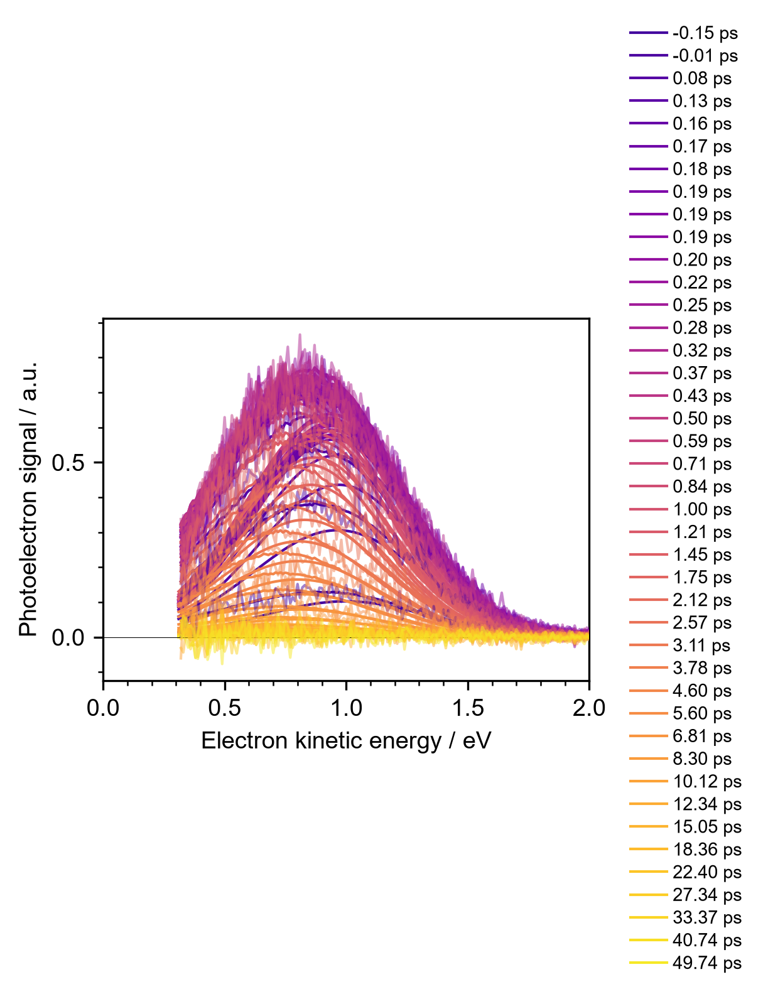

In [57]:
fig,ax = plt.subplots(1)
ax0,ax1 = axes

#Retrieval parameters
all_params = [] 
all_perrs = [] 
#Gaussian fit parameters
all_params_gau = [] 
all_perrs_gau = [] 

xs = np.arange(0.01,5.01,0.01)
crossSectionSetInd = 0
thresholdInd = 6
surfInd = 6
num_surface = 5
num_bulk = 5

print(f"Cross-section set: {crossSectionSets[crossSectionSetInd]}")
print(f"Escape threshold: {E0s[thresholdInd]} eV")
print(f"Concentration profile G amplitude: {concAmps[surfInd]}")
print(f"Surface gaussians: {num_surface}")
print('-'*8)

cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=48)  # Normalize data 
#Params for initial bounds
params = [0.14, 1.0, 0.79]

# Change range to include more or less spectra.
# Those at negative and long delays will not fit so they
# are usually excluded
for ind in range(5,47): 

    fittableData = np.array((scanSet.energies,
                             scanSet.subtracted[ind]))

    #----------RETRIEVE-----------
    # Pick surface and bulk basis functions 
    surf_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,surfInd]
    bulk_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,0]
    surf_bas /= np.amax(surf_bas)

    #Rebin data ontoo 0.01 eV grid and cutoff below low eKE cutoff
    min_eKE = min(fittableData[0])
    rebinnedData = rebinData(fittableData,min_eKE,nanWarningSuppress=True)
    x_above_cutoff,y_above_cutoff = rebinnedData

    #Create fit functions with basis functions and min_eKE
    fitfunc = JetFitFunc(num_surface,num_bulk, surf_bas, bulk_bas, min_eKE)
    #Base bounds on previous fit
    bounds =np.array(((0,np.inf),
                   (params[1]*0.95,params[1]*1.05),
                   (params[2]*0.95,params[2]*1.05),)).T
    #Fit
    params,pcov = curve_fit(fitfunc.f, xs, y_above_cutoff,
                             p0 = params,
                             bounds = bounds
                             )
    #Get errors of fit
    perrs = np.sqrt(np.diag(pcov))

    #Plot data
    ax.plot(x_above_cutoff,y_above_cutoff,
            zorder=ind,
            c=cmap(norm(ind)),
            alpha=.5
           )

    #Plot fit
    ax.plot(x_above_cutoff, fitfunc.f(xs, *params),
            c=cmap(norm(ind)),
            label = f"{scanSet[0].delayTimes[ind]-t0:.2f} ps",
           )
    #Plot retrieval
    ax.plot(spectrum[0],multiple_gaussians(spectrum[0],*params),
            c=cmap(norm(ind)))

    
    print([float(f"{p:.2f}") for p in params], end=' ')
    # print([float(f"{p:.3f}") for p in params[1::3]])
    print([float(f"{1239.8/350 + 1239.8/266.67 - p:.2f}") for p in params[1::3]])

    all_params.append([scanSet[0].delayTimes[ind]-t0,]+list(params))
    all_perrs.append([scanSet[0].delayTimes[ind]-t0,]+list(perrs))

    #-----------------Fit GAUSSIAN---------------
    params_gau,pcov= curve_fit(multiple_gaussians,
                        fittableData[0],fittableData[1],
                        p0 = [1,.9,1],
                       bounds=[0,np.inf])
    perrs = np.sqrt(np.diag(pcov))
    all_params_gau.append([scanSet[0].delayTimes[ind]-t0,]+list(params_gau))
    all_perrs_gau.append([scanSet[0].delayTimes[ind]-t0,]+list(perrs))
    print([float(f"{p:.2f}") for p in params_gau])

all_params = np.array(all_params)
all_perrs = np.array(all_perrs)
all_params_gau = np.array(all_params_gau)
all_perrs_gau = np.array(all_perrs_gau)

ax.hlines(0,0,5,'k',lw=.25)

ax.set_xlim(0,2)

ax.set_ylabel("Photoelectron signal / a.u.")
ax.set_xlabel("Electron kinetic energy / eV")
    
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(.1))
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax.legend(frameon=True,facecolor='white', framealpha=1,edgecolor='white')
ax.legend(frameon=False,bbox_to_anchor=[1.2, 0.5], 
           loc='center')


### Plots for thesis

#### Heatmaps (exp+retrieved)

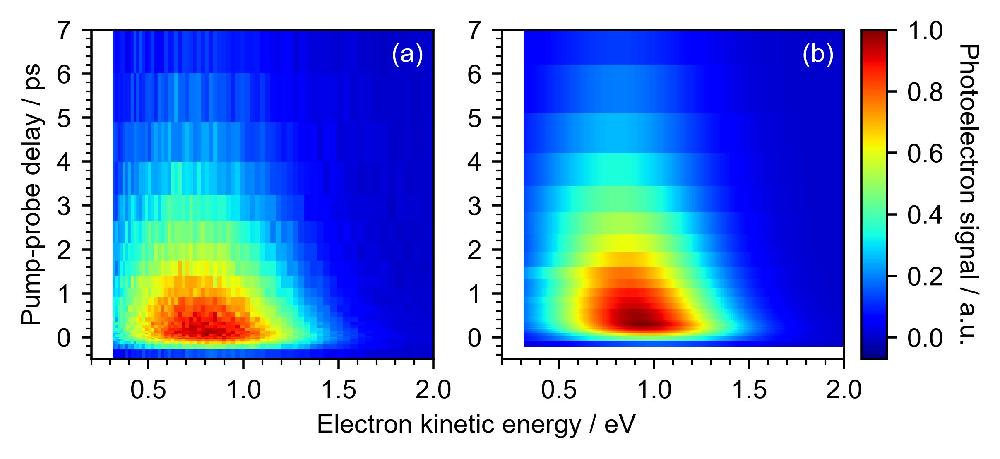

In [58]:
fig,(ax0,axd,ax1,axe,ax2) = plt.subplots(1,5,
                                 gridspec_kw={'width_ratios':[1,0.2,1,0.05,.075]})
plt.subplots_adjust(wspace=0)
fig.set_dpi(500)
fig.set_size_inches(thesisWid*.9,thesisWid/2*0.75)

vmin,vmax = np.amin(scanSet.subtracted_rebinned),np.amax(scanSet.subtracted_rebinned)

im0 = ax0.pcolormesh(scanSet.energies_rebinned,
                    scanSet.delays,
                    scanSet.subtracted_rebinned,
                    cmap='jet',
                    # shading='gouraud',
                    vmin=vmin,vmax=vmax,
                   )
im1 = ax1.pcolormesh(scanSet.energies_retrieved,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_retrieved/vmax,
                    cmap='jet',
                    # shading='gouraud',
                    vmin=vmin,vmax=vmax,
                   )

for ax in (ax0,ax1):
    ax.set_xlim(0.2,2)
    ax.set_ylim(-.5,7)
    # ax.set_yscale('log')
    # ax.set_ylim(0.01,10)

    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(.1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_minor_locator(MultipleLocator(.2))
ax0.set_ylabel("Pump-probe delay / ps")
# ax.set_xlabel("Electron kinetic energy / eV")
fig.supxlabel("Electron kinetic energy / eV",y=-0.075)
# plt.colorbar(im0)
fig.colorbar(im1, cax=ax2)
ax2.set_ylabel("Photoelectron signal / a.u.",rotation=270,va='bottom')
axd.set_axis_off()
axe.set_axis_off()

for ax,indx in zip((ax0,ax1),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.97,.96,f"({indx})", va = "top",ha = "right",c='w',transform = ax.transAxes)

plt.savefig('heatmaps.png',dpi=fig.dpi,bbox_inches='tight')

#### Transients

C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


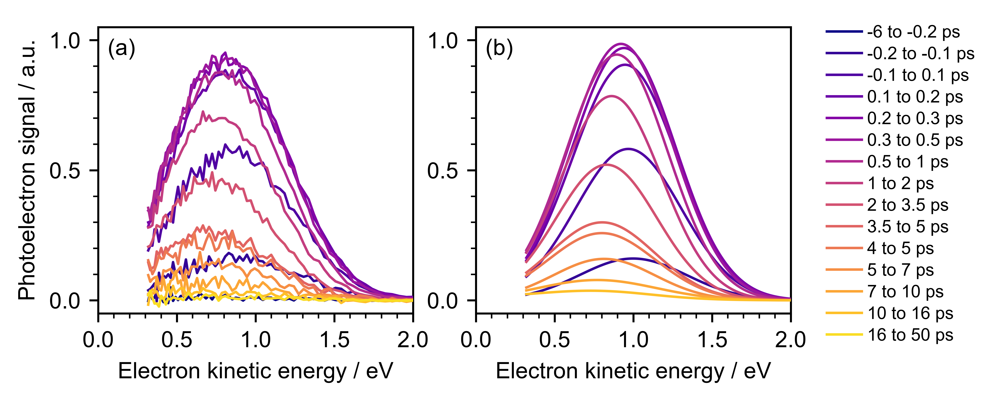

In [59]:
fig,(ax0,ax1) = plt.subplots(1,2)
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2*0.75)

t0 = scanSet.t0
delays = scanSet.delays - t0

#Set limits for time ranges
timeRanges = [(-6,-.2),(-.2,-.1),(-.1,.1),(.1,.2),
              (.2,.3),(.3,.5),(.5,1),(1,2),(2,3.5),(3.5,5),(4,5),
              (5,7),(7,10),(10,16),(16,50),
             ]
#Create and normalise color map
cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=len(timeRanges))  # Normalize data from 0 to 100


for ind,timeRange in enumerate(timeRanges):
    #Binned data
    #Mask data outside of time range
    mask = (np.logical_and(scanSet.delays-t0>timeRange[0],
                           scanSet.delays-t0<=timeRange[1]))
    masked_data = scanSet.subtracted_rebinned[mask] 
    
    #Plot
    ax0.plot(scanSet.energies_rebinned,np.mean(masked_data,axis=0),
            label = f"{timeRange[0]} to {timeRange[1]} ps",
            zorder=ind,
            c=cmap(norm(ind)),
           )
    
    #Retrieved data
    #Mask data outside of time range
    mask = (np.logical_and(scanSet.delays_retrieved>timeRange[0],
                           scanSet.delays_retrieved<=timeRange[1]))
    masked_data = scanSet.subtracted_retrieved[mask]
    
    #Plot
    ax1.plot(scanSet.energies_retrieved,np.mean(masked_data,axis=0),
            label = f"{timeRange[0]} to {timeRange[1]} ps",
            zorder=ind,
            c=cmap(norm(ind)),
           )

#Format
for ax in (ax0,ax1):
    ax.set_xlim(0,2)
    ax.set_ylim(-.05,1.05)

    ax.set_xlabel("Electron kinetic energy / eV")

    ax.yaxis.set_major_locator(MultipleLocator(.5))
    ax.yaxis.set_minor_locator(MultipleLocator(.1))
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax0.set_ylabel("Photoelectron signal / a.u.")
ax1.legend(frameon=False,bbox_to_anchor=[1.35, 0.45], 
               loc='center',ncol=1)

for ax,indx in zip((ax0,ax1),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.03,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)

# fig.patch.set_alpha(0)
plt.savefig('transients.png',dpi=fig.dpi,bbox_inches='tight')

In [60]:
mask = (np.logical_and(scanSet.delays_retrieved>-.1,
                       scanSet.delays_retrieved<=.05))
masked_data = scanSet.subtracted_retrieved[mask]
print(scanSet.energies_retrieved[np.argmax(np.mean(masked_data,axis=0))])
(scanSet.delays_retrieved)[mask]


0.96


array([-0.00609079])

#### Heatmaps + transients

(-6, -0.2) [-4.80741237 -2.73864786 -1.52447455 -0.81264877 -0.39502652]
(-0.2, -0.1) [-0.15019048]
(-0.1, 0.1) [-0.00609079  0.07796736]
(0.1, 0.2) [0.12733485 0.15668849 0.17336669 0.18337362 0.18937777 0.19271341
 0.1947148  0.19604905]
(0.2, 0.3) [0.21806428 0.24541654 0.27877295]
(0.3, 0.5) [0.31946777 0.36883525 0.42954392]


C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\_methods.py:137: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


(0.5, 1) [0.50359515 0.59432458 0.70506786 0.83982776]
(1, 2) [1.00460842 1.20608113 1.45158431 1.75179199]
(2, 3.5) [2.1187125  2.56702264 3.11406776]
(3.5, 5) [3.7825302  4.59842798]
(5, 7) [5.59578463 6.81329357]
(7, 10) [8.30098944]
(10, 16) [10.1175795  12.33644786 15.0469897 ]
(16, 50) [18.35727978 22.40007661 27.33882661 33.37033258 40.73742918 49.73565422]


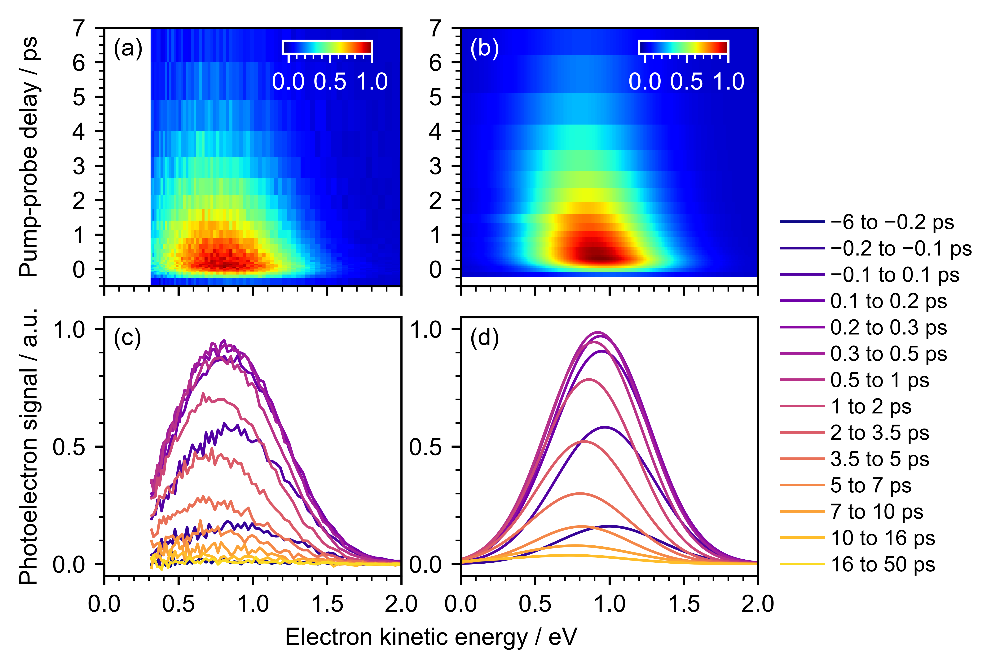

In [61]:
fig = plt.figure()

# Define GridSpec with custom width ratios
gs = gridspec.GridSpec(2, 3, figure=fig,
                       width_ratios = [1,0.2,1])

# heamaps
ax2 = fig.add_subplot(gs[0, 0])
ax3 = fig.add_subplot(gs[0, 2])
# ax_cbar = fig.add_subplot(gs[0, 4])

ax0 = fig.add_subplot(gs[1, 0])
ax1 = fig.add_subplot(gs[1, 2])

fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.8,thesisWid*.9*0.75)
plt.subplots_adjust(wspace=0,hspace=.12)

#### heatmap
vmin,vmax = np.amin(scanSet.subtracted_rebinned),np.amax(scanSet.subtracted_rebinned)

im0 = ax2.pcolormesh(scanSet.energies_rebinned,
                    scanSet.delays,
                    scanSet.subtracted_rebinned,
                    cmap='jet',
                    # shading='gouraud',
                    vmin=vmin,vmax=vmax,
                   )

im1 = ax3.pcolormesh(scanSet.energies_retrieved_full,
                    scanSet.delays_retrieved,
                    scanSet.subtracted_retrieved_full,
                    cmap='jet',
                    # shading='gouraud',
                    vmin=vmin,vmax=vmax,
                   )

for ax in (ax2,ax3):
    ax.set_xlim(0.,2)
    ax.set_ylim(-.5,7)
    # ax.set_yscale('log')
    # ax.set_ylim(0.01,10)

    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(.1))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_minor_locator(MultipleLocator(.25))
    ax.set_xticklabels([])
ax0.set_ylabel("Pump-probe delay / ps")
for ax in ax2,ax3:
    cax = ax.inset_axes([0.6, 0.9, 0.3, 0.05])
    cbar=fig.colorbar(im0, cax=cax, orientation='horizontal')

    cbar.outline.set_edgecolor('white')
    cbar.ax.tick_params(which='both',colors='white')
    cax.xaxis.set_major_locator(MultipleLocator(.5))
    cax.xaxis.set_minor_locator(MultipleLocator(.1))

# fig.colorbar(im1, cax=ax_cbar)
# ax_cbar.set_ylabel("Photoelectron signal / a.u.",rotation=270,va='bottom')

### transients
t0 = scanSet.t0
delays = scanSet.delays - t0

#Set limits for time ranges
timeRanges = [(-6,-.2),(-.2,-.1),(-.1,.1),(.1,.2),
              (.2,.3),(.3,.5),(.5,1),(1,2),(2,3.5),(3.5,5),
              (5,7),(7,10),(10,16),(16,50),
             ]
#Create and normalise color map
cmap = plt.get_cmap('plasma')  # You can choose any colormap
norm = mcolors.Normalize(vmin=0, vmax=len(timeRanges))  # Normalize data from 0 to 100
# save list
saveTransientsExp = []
saveTransientsRetr = []

for ind,timeRange in enumerate(timeRanges):
    #Binned data
    #Mask data outside of time range
    mask = (np.logical_and(scanSet.delays-t0>timeRange[0],
                           scanSet.delays-t0<=timeRange[1]))
    masked_data = scanSet.subtracted_rebinned[mask] 
    print(timeRange,delays[mask])

    # Change plot label dash to minus sign
    label = f"{timeRange[0]} to {timeRange[1]} ps"
    label = label.replace("-", "−") 

    #Plot
    ax0.plot(scanSet.energies_rebinned,np.mean(masked_data,axis=0),
            label = label,
            zorder=ind,
            c=cmap(norm(ind)),
           )
    
    saveTransientsExp.append((f"{timeRange[0]} to {timeRange[1]} ps",
                              np.mean(masked_data,axis=0)))
    
    #Retrieved data
    #Mask data outside of time range
    mask = (np.logical_and(scanSet.delays_retrieved>timeRange[0],
                           scanSet.delays_retrieved<=timeRange[1]))
    masked_data = scanSet.subtracted_retrieved_full[mask]
    # Get weighted average to ensure the relative height is consistent
    average_data = np.trapezoid(masked_data,axis=0,x=scanSet.delays_retrieved[mask])/(timeRange[1]-timeRange[0])

    
    #Plot
    ax1.plot(scanSet.energies_retrieved_full,np.mean(masked_data,axis=0),
    # ax1.plot(scanSet.energies_retrieved_full,average_data,
            label = label,
            zorder=ind,
            c=cmap(norm(ind)),
           )
    saveTransientsRetr.append((f"{timeRange[0]} to {timeRange[1]} ps",
                              np.mean(masked_data,axis=0)*1.1))
    #Format
for ax in (ax0,ax1):
    ax.set_xlim(0,2)
    ax.set_ylim(-.05,1.05)


    ax.yaxis.set_major_locator(MultipleLocator(.5))
    ax.yaxis.set_minor_locator(MultipleLocator(.1))
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(.1))
ax2.set_ylabel("Pump-probe delay / ps")
ax0.set_ylabel("Photoelectron signal / a.u.")
ax0.set_xlabel("Electron kinetic energy / eV",x=1.1)
ax1.legend(frameon=False,bbox_to_anchor=[1.4, 0.7], 
               loc='center',ncol=1,fontsize=8)
fig.align_ylabels((ax0,ax2))

for ax,indx in zip((ax2,ax3,ax0,ax1),('abcdefghijklmnopqrstuvwxyz')):
    if indx == 'b': c='w'
    else: c='k'
    ax.text(.03,.96,f"({indx})",c=c, va = "top",ha = "left",transform = ax.transAxes)
for ax in ax2,ax3,ax0,ax1:
    for spine in ax.spines.values():
        spine.set_zorder(100)
    
plt.savefig('heatmaps_transients.png',dpi=fig.dpi,bbox_inches='tight')


##### Save data

In [62]:
#Save data
if False:
    savePath = cpath+r"/[CHANGE]\PhD\Thesis\Data\Chapter 5\Figure 5.4/"

    #transients
    saveTransientsExp = np.array(saveTransientsExp,dtype=object)

    saveData = np.vstack((scanSet.energies_rebinned,
                         np.array(list(saveTransientsExp[:,1]))))
    header = ', '.join(['eKE',]+list(saveTransientsExp[:,0]))
    
    np.savetxt(savePath+"RebinnedExperimentalTransients.csv",saveData.T,
               header=header,
               delimiter=','
              )
    #transients retrieved
    saveTransientsRetr = np.array(saveTransientsRetr,dtype=object)

    saveData = np.vstack((scanSet.energies_retrieved_full,
                         np.array(list(saveTransientsRetr[:,1]))))
    header = ', '.join(['eKE',]+list(saveTransientsRetr[:,0]))
    
    np.savetxt(savePath+"RebinnedRetrievedTransients.csv",saveData.T,
               header=header,
               delimiter=','
              )
    #retrieved heatmap

    saveData = np.vstack((scanSet.delays_retrieved,scanSet.subtracted_retrieved_full.T/vmax))
    saveEnergies = np.hstack(([0,],scanSet.energies_retrieved_full))
    saveData = np.vstack((saveEnergies,saveData.T))

    np.savetxt(savePath+"RetrievedData.csv",saveData,
               delimiter=',',
              fmt='%.10e')    

#     scanSet.energies_retrieved_full,
#                     scanSet.delays_retrieved,
#                     scanSet.subtracted_retrieved_full/vmax

#### eKE shift

In [63]:
def monoexponential_energy(x,A1,tau1,y0):
    return A1 * np.exp(-x/tau1) + y0

In [64]:
def average_eKE(x,y,axis=-1):
    """Computes the average eKE by weighing the x values by the area of the trapezoid"""
    
    dx = np.diff(x, axis=axis)  # differences along axis
    area = (y[..., 1:] + y[..., :-1]) / 2 * dx  # trapezoid areas

    # Move axis to last for easier broadcasting
    x0 = np.moveaxis(x, axis, -1)
    area0 = np.moveaxis(area, axis, -1)

    # Weighted sum
    weighted_sum = np.sum(x0[..., :-1] * area0, axis=-1)
    total_area = np.sum(area0, axis=-1)
    
    return weighted_sum / total_area    


[0.16452661 1.11692936 0.80673005]
[0.11674635 0.73094203 0.81854146]


(0.19600000000000006, 0.134, 0.1100000000000001)

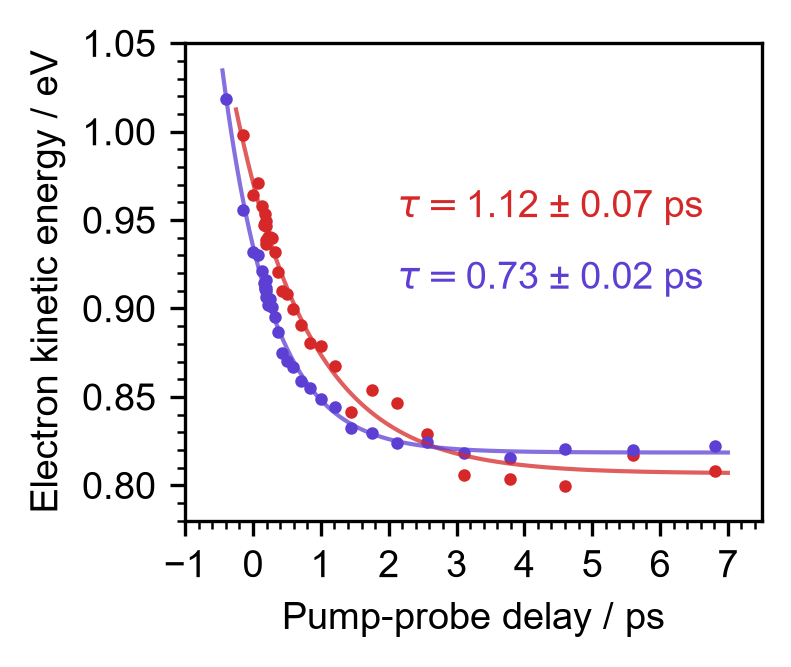

In [65]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)



#Plot mean retrieved eKE
ax.plot(scanSet.delays_retrieved,scanSet.params_retrieved[:,1],'o',c=red,ms=2,label='Retrieved')

#Find weighted average (mean eKE)
delays = scanSet.delays-scanSet.t0
#Stack energies
tiled_energies = np.tile(scanSet.energies,(len(delays),1))
# Get weighted average
weighted_average = average_eKE(tiled_energies,scanSet.subtracted)

# Plot mean eKE (withour data below 0.6ps which has 0 intensity)
ax.plot(delays[delays>-.6],weighted_average[delays>-.6],'o',c=violet,ms=2,label='Mean eKE')

# ######### # retrieved mean_eKE
# #Find weighted average (mean eKE)
# delays = scanSet.delays_retrieved
# #Stack energies
# tiled_energies = np.tile(scanSet.energies_retrieved,(len(delays),1))
# # Get weighted average
# weighted_average = average_eKE(tiled_energies,scanSet.subtracted_retrieved)

# # Plot mean eKE (withour data below 0.6 which has 0 intensity)
# ax.plot(delays[delays>-.6],weighted_average[delays>-.6],'o',c=green,ms=2,label='Mean eKE (retr)')

##### Fit retrieved with monoexponential
ds=np.linspace(-0.25,7,501) 
mask = scanSet.delays_retrieved<8
#Fit
params,pcov=curve_fit(monoexponential_energy,
                      scanSet.delays_retrieved[mask],scanSet.params_retrieved[:,1][mask],
                        p0=[1,3,.7])
perr = np.sqrt(np.diag(pcov))
print(params)
ax.plot(ds,monoexponential_energy(ds,*params),c=red,alpha=.75)
ax.text(.9,.55, f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c=red,transform=ax.transAxes)

##### Fit mean eKE with monoexponential
ds=np.linspace(-0.45,7,501) 

mask = np.logical_and(delays>-.5,delays<8)

#Fit
params,pcov=curve_fit(monoexponential_energy,
                      delays[mask],weighted_average[mask],
                        p0=[1,3,.7])
perr = np.sqrt(np.diag(pcov))
print(params)
ax.plot(ds,monoexponential_energy(ds,*params),c=violet,alpha=.75)
ax.text(.9,.4, f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c=violet,transform=ax.transAxes)

ax.yaxis.set_major_locator(MultipleLocator(.05))
ax.yaxis.set_minor_locator(MultipleLocator(.01))
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.xaxis.set_minor_locator(MultipleLocator(.2))
ax.set_xlim(-1,7.5)
ax.set_ylim(0.78 ,1.05)
ax.set_xlabel("Pump-probe delay / ps")
ax.set_ylabel("Electron kinetic energy / eV")

# fig.patch.set_alpha(0)
# ax.patch.set_alpha(0)
# plt.savefig('eKEshift.png',dpi=fig.dpi,bbox_inches='tight')
# print(np.array((delays[delays>-.6],weighted_average[delays>-.6])))
1.018-0.822,0.956-0.822,0.932-0.822

In [66]:
for d, a in zip(scanSet.delays_retrieved,scanSet.params_retrieved[:,1]):
    print(d,a)

-0.1501904776834307 0.9982553313857895
-0.006090788557785609 0.9642742457608263
0.07796736343209502 0.9709097560373009
0.1273348495214487 0.9577306557712562
0.15668848989891246 0.9473162134426407
0.1733666946588049 0.9534897868761166
0.18337361751470244 0.9483466810786885
0.18937777122827887 0.9494897891232066
0.19271341218027632 0.946491279081773
0.19471479675143688 0.9363940850539053
0.19604905313227378 0.9388558977412335
0.21806428341532422 0.9405588085407298
0.24541653922162743 0.9404603612442866
0.2787729487414123 0.9400939799253426
0.3194677683556105 0.9318081062988058
0.36883525444486936 0.9206308374801216
0.42954391977095746 0.9100794103041872
0.5035951489049406 0.9080241924904394
0.5943245827989109 0.8997696344172089
0.7050678624046762 0.8908580473561313
0.8398277568647474 0.8802168815840189
1.004608419892606 0.878529068445639
1.206081133392247 0.8675250412791138
1.4515843074580836 0.8413733696586906
1.7517919931364319 0.8540072103716247
2.1187124978544447 0.8465460541194839
2

In [67]:
# for d in delays[delays>-.6]*1000:
#     print(f"{d:.0f}")
len(delays)

47

#### Total counts/area

t0, A1, tau1
[0.016, 0.556, 3.315]
[0.004, 0.004, 0.073]
t0, A1, tau1
[-0.196, 0.557, 2.831]
[0.003, 0.003, 0.046]


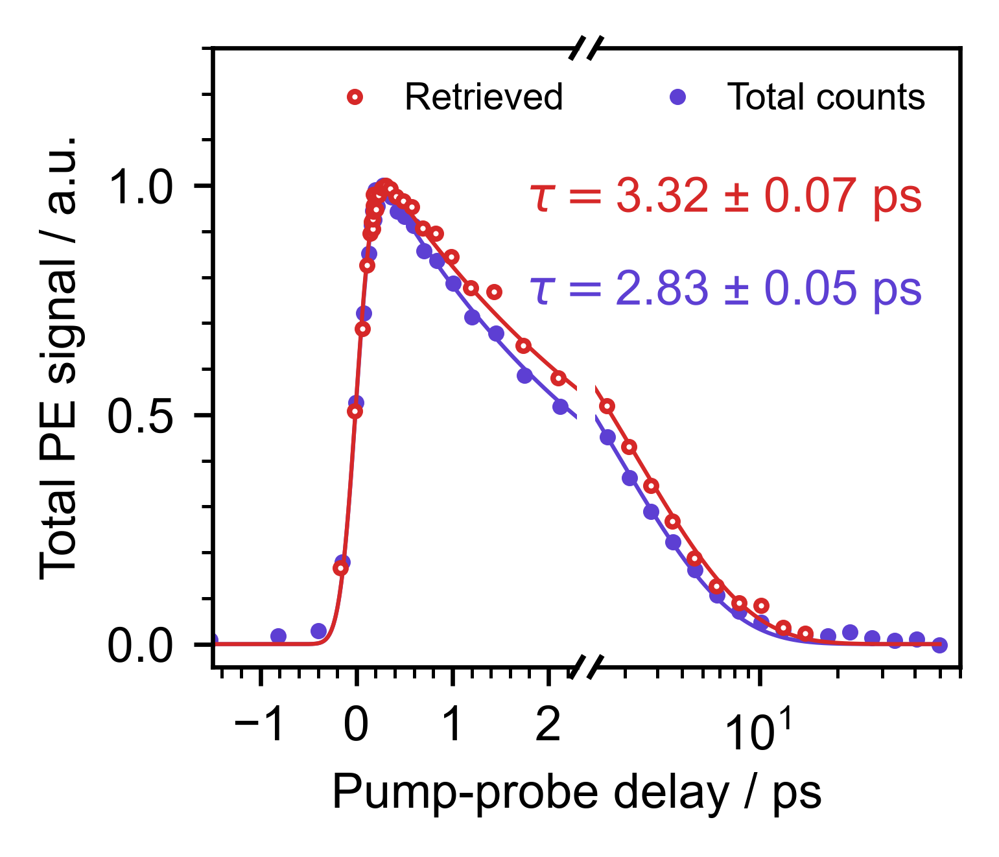

In [68]:
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(600)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)

delays = scanSet.delays_retrieved
trace = scanSet.params_retrieved[:,0]*scanSet.params_retrieved[:,2]
trace/=max(trace)

params,pcov=curve_fit(monoexponential_witht0, delays, trace,
                  p0=[0,1,3])
perr = np.sqrt(np.diag(pcov))
t0=params[0]

for ax in axes:
    ax.plot(delays-t0,trace,'o',c=red,markerfacecolor='w',ms=2,zorder=100,label='Retrieved')
    ax.plot(ts-t0,monoexponential_witht0(ts,*params),red,lw=.75)
    
    
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])

ax1.text(.9,.65,f"$\\tau =${params[2]:.2f} ± {perr[2]:.2f} ps\n",ha='right',c=red,transform=ax.transAxes)

#### Total counts
delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

params,pcov=curve_fit(monoexponential_witht0,delays,trace,
                  p0=[.5,300,3])
perr = np.sqrt(np.diag(pcov))

t0 = params[0]
# Save t0 to scanSet
for ax in axes:
    ax.plot(delays-t0,trace,'o',c=violet,ms=2,zorder=0,label='Total counts')
    ax.plot(ts-t0,monoexponential_witht0(ts,*params),c=violet,lw=.75,zorder=0)
       
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax1.text(.9,.5,f"$\\tau =${params[2]:.2f} ± {perr[2]:.2f} ps\n",c=violet,ha='right',transform=ax.transAxes)

### 
    
#Formatting
for ax in axes:
    ax.set_ylim(-.05,1.3)
ax0.set_xlim(-1.5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(1))
ax0.xaxis.set_minor_locator(MultipleLocator(.2))
ax1.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal


## Legend
ax1.legend(ncol=2,loc='upper right')


##### Residuals

t0, A1, tau1
[0.016, 0.556, 3.315]
[0.004, 0.004, 0.073]
t0, A1, tau1
[-0.196, 0.557, 2.831]
[0.003, 0.003, 0.046]


C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\1797623485.py:90: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(ncol=2,loc='upper right')


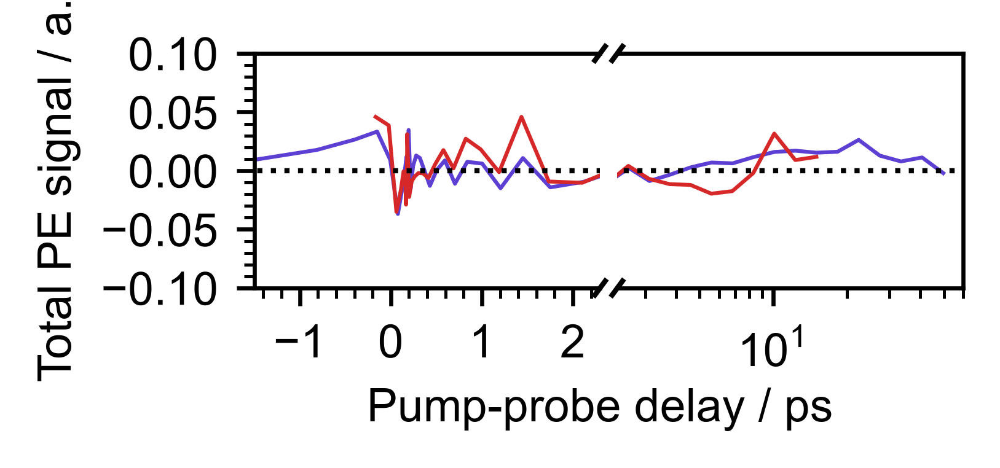

In [69]:
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(600)
fig.set_size_inches(thesisWid*.45,thesisWid/5*0.75)

ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)

delays = scanSet.delays_retrieved
trace = scanSet.params_retrieved[:,0]*scanSet.params_retrieved[:,2]
trace/=max(trace)

params,pcov=curve_fit(monoexponential_witht0, delays, trace,
                  p0=[0,1,3])
perr = np.sqrt(np.diag(pcov))
t0=params[0]

for ax in axes:
    # ax.plot(delays-t0,trace,'o',c=red,markerfacecolor='w',ms=2,zorder=100,label='Retrieved')
    ax.plot(delays-t0,trace-monoexponential_witht0(delays,*params),red,lw=.75)
    
    
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])

# ax1.text(.9,.6,f"$\\tau =${params[2]:.1f} ± {perr[2]:.1f} ps\n",ha='right',c=red,transform=ax.transAxes)

#### Total counts
delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

params,pcov=curve_fit(monoexponential_witht0,delays,trace,
                  p0=[.5,300,3])
perr = np.sqrt(np.diag(pcov))

t0 = params[0]
# Save t0 to scanSet
for ax in axes:
    # ax.plot(delays-t0,trace,'o',c=violet,ms=2,zorder=0,label='Total counts')
    ax.plot(delays-t0,trace-monoexponential_witht0(delays,*params),c=violet,lw=.75,zorder=0)
       
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
# ax1.text(.9,.45,f"$\\tau =${params[2]:.1f} ± {0.1} ps\n",c=violet,ha='right',transform=ax.transAxes)

### 
    
#Formatting
for ax in axes:
    ax.hlines(0,-5,300,'k',':')
    ax.set_ylim(-.1,0.1)
ax0.set_xlim(-1.5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.05))
ax0.yaxis.set_minor_locator(MultipleLocator(.01))
ax0.xaxis.set_major_locator(MultipleLocator(1))
ax0.xaxis.set_minor_locator(MultipleLocator(.2))
ax1.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m= 2# Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal


## Legend
ax1.legend(ncol=2,loc='upper right')

#### Total counts/area kinetic model

In [70]:
def I(t,k,sigma):
    """Monoexponential helper function"""
    tau1=1/k
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))
    # return 1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2/(k1*(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    
def kinetic_model_gau_witht0(x,t0,A1,A2,tau1,tau2):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    return A_model(x-t0,A1,tau1,sigma) + B_model(x-t0,A2,tau1,tau2,sigma)


[2.83290060e-03 1.03750448e+00 1.00000000e+01 3.23911056e-01
 3.12225701e+00]
t0, A1, A2, tau1, tau2
[0.003, 1.038, 10.0, 0.324, 3.122]
[0.008, 0.058, 16.121, 0.25, 0.115]
t0, A1, A2, tau1, tau2
[-0.192, 1.105, 0.04, 2.212, 3.0]
[0.003, 0.008, 0.756, 6.354, 3.965]


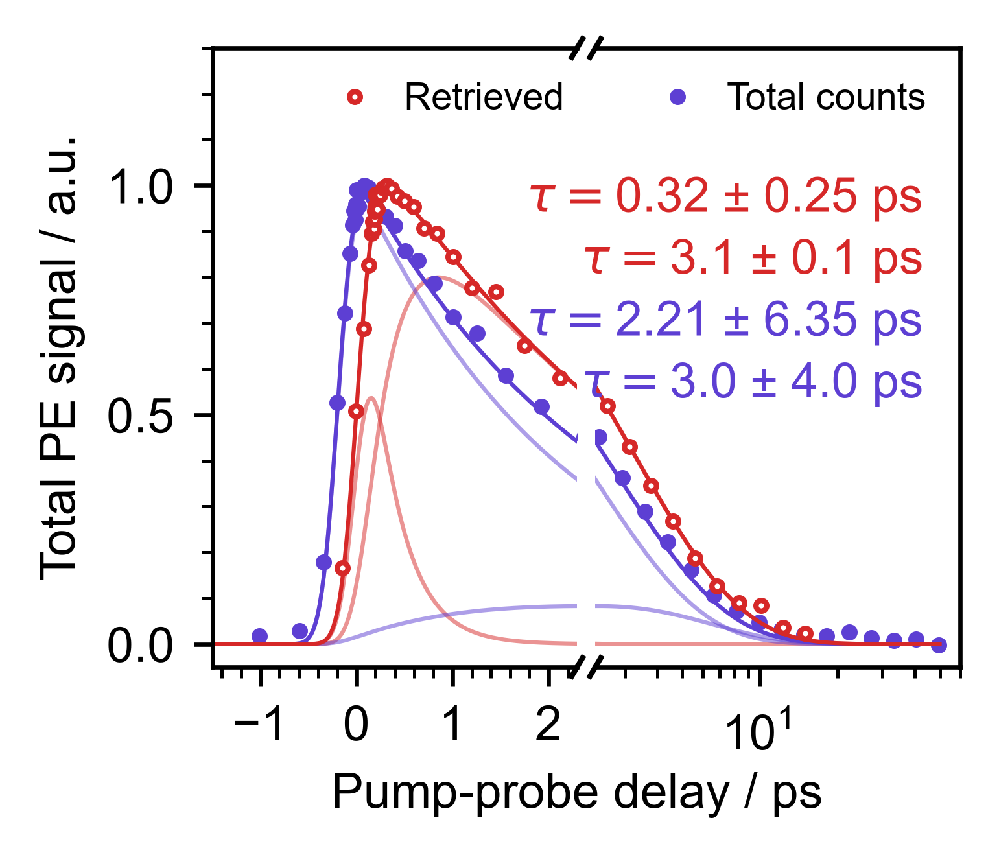

In [71]:
fig,axes = plt.subplots(1,2)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(600)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)
ax0,ax1 = axes
ts  =np.arange(-5,50,0.020)
sigma = 0.320 / 2.355

delays = scanSet.delays_retrieved
trace = scanSet.params_retrieved[:,0]*scanSet.params_retrieved[:,2]
trace/=max(trace)

params,pcov=curve_fit(kinetic_model_gau_witht0, delays, trace,
                  p0=[0,1,1,.9,3],maxfev=5000,bounds=(-10,10))
perr = np.sqrt(np.diag(pcov))

print(params)

for ax in axes:
    ax.plot(delays,trace,'o',c=red,markerfacecolor='w',ms=2,zorder=100,label='Retrieved')
    ax.plot(ts,kinetic_model_gau_witht0(ts,*params),red,lw=.75)
    ax.plot(ts,A_model(ts-params[0],params[1],params[3],sigma),c=red,lw=.75,zorder=0,alpha=.5)
    ax.plot(ts,B_model(ts-params[0],*params[2:],sigma),c=red,lw=.75,zorder=0,alpha=.5)

    
print("t0, A1, A2, tau1, tau2")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])

ax1.text(.9,.65,f"$\\tau =${params[3]:.2f} ± {perr[3]:.2f} ps\n",ha='right',c=red,transform=ax.transAxes)
ax1.text(.9,.55,f"$\\tau =${params[4]:.1f} ± {perr[4]:.1f} ps\n",ha='right',c=red,transform=ax.transAxes)

#### Total counts
delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

params,pcov=curve_fit(kinetic_model_gau_witht0, delays, trace-0.015,
                  p0=[0,.5,1,.9,3],maxfev=5000,bounds=(-10,3))
perr = np.sqrt(np.diag(pcov))

# Save t0 to scanSet
for ax in axes:
    ax.plot(delays,trace,'o',c=violet,ms=2,zorder=0,label='Total counts')
    ax.plot(ts,kinetic_model_gau_witht0(ts,*params),c=violet,lw=.75,zorder=0)
    ax.plot(ts,A_model(ts-params[0],params[1],params[3],sigma),c=violet,lw=.75,zorder=0,alpha=.5)
    ax.plot(ts,B_model(ts-params[0],*params[2:],sigma),c=violet,lw=.75,zorder=0,alpha=.5)
       
print("t0, A1, A2, tau1, tau2")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax1.text(.9,.45,f"$\\tau =${params[3]:.2f} ± {perr[3]:.2f} ps\n",ha='right',c=violet,transform=ax.transAxes)
ax1.text(.9,.35,f"$\\tau =${params[4]:.1f} ± {perr[4]:.1f} ps\n",ha='right',c=violet,transform=ax.transAxes)

### 
    
#Formatting
for ax in axes:
    ax.set_ylim(-.05,1.3)
ax0.set_xlim(-1.5,2.299)

ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)

ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)

   
    
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0.xaxis.set_major_locator(MultipleLocator(1))
ax0.xaxis.set_minor_locator(MultipleLocator(.2))
ax1.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal


## Legend
ax1.legend(ncol=2,loc='upper right')

#### eKE shift + total Area

First retrieved delay: -0.166 ps
Last retrieved delay: 15.031 ps
t0, A1, tau1
[0.016, 0.556, 3.315]
[0.004, 0.004, 0.073]
t0, A1, tau1
[-0.196, 0.557, 2.831]
[0.003, 0.003, 0.046]
Average retrieved eKE within cross-correlation; 0.968 eV
Retrieved eKE at t = -0.01 ps: 0.964 eV
[0.16452661 1.11692936 0.80673005]
Red: Central eKE (retr, eKE>cutoff)
[0.11674635 0.73094203 0.81854146]
Violet: mean eKE (meas, eKE>cutoff)
Green: Mean eKE (retr, eKE>cutoff)
[0.13867685 0.94956817 0.8499145 ]


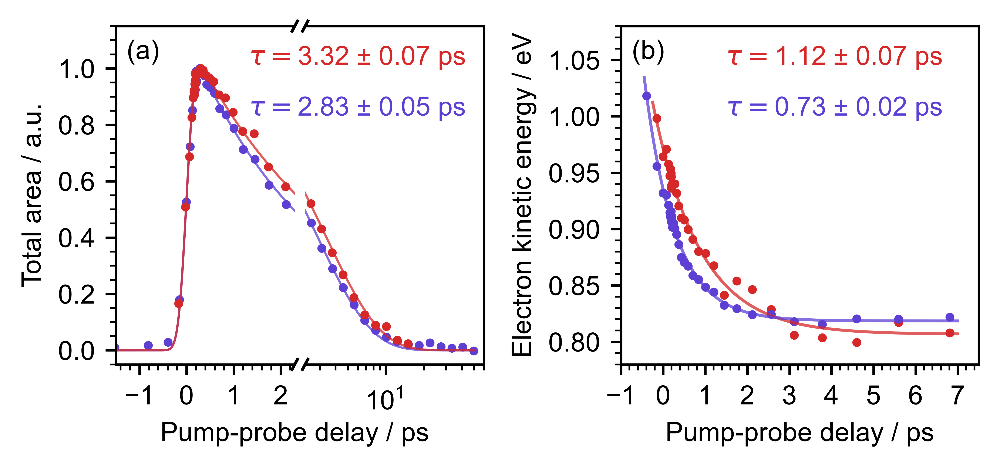

In [72]:
fig,(ax0,ax1,ax2,ax3) = plt.subplots(1,4,
                                 gridspec_kw={'width_ratios':[1,1,0.65,2]})
ax2.set_axis_off()
plt.subplots_adjust(wspace=0.05)                            
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.95,thesisWid/2*0.75)

ts  =np.arange(-5,50,0.020)
#### Retreived
delays = scanSet.delays_retrieved
trace = scanSet.params_retrieved[:,0]*scanSet.params_retrieved[:,2]
trace/=max(trace)

params,pcov=curve_fit(monoexponential_witht0, delays, trace,
                  p0=[0,1,3])

perr = np.sqrt(np.diag(pcov))
t0=params[0]

for ax in (ax0,ax1):
    ax.plot(delays-t0,trace,'o',c=red,markerfacecolor=red,ms=2,zorder=100,label='Retrieved')
    ax.plot(ts-t0,monoexponential_witht0(ts,*params),red,lw=.75,alpha=.75)
    
print(f"First retrieved delay: {scanSet.delays_retrieved[0]-t0:.3f} ps")
print(f"Last retrieved delay: {scanSet.delays_retrieved[-1]-t0:.3f} ps")
    
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])

ax1.text(.9,.8,f"$\\tau =${params[2]:.2f} ± {perr[2]:.2f} ps\n",ha='right',c=red,transform=ax.transAxes)

#for saving
retrievedTrace = np.asarray((delays-t0,trace))
retrievedFit = np.asarray((ts-t0,monoexponential_witht0(ts,*params)))

#### Total counts
delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

params,pcov=curve_fit(monoexponential_witht0,delays,trace,
                  p0=[.5,300,3])
perr = np.sqrt(np.diag(pcov))

t0 = params[0]
# Save t0 to scanSet
for ax in (ax0,ax1):
    ax.plot(delays-t0,trace,'o',c=violet,ms=2,zorder=0,label='Total counts')
    ax.plot(ts-t0,monoexponential_witht0(ts,*params),c=violet,lw=.75,zorder=0,alpha=.75)
       
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
ax1.text(.9,.65,f"$\\tau =${params[2]:.2f} ± {perr[2]:.2f} ps\n",c=violet,ha='right',transform=ax.transAxes)

#for saving
totalCountsTrace = np.asarray((delays-t0,trace))
totalCountsFit = np.asarray((ts-t0,monoexponential_witht0(ts,*params)))

#Formatting
for ax in (ax0,ax1):
    ax.set_ylim(-.05,1.15)
ax0.set_xlim(-1.5,2.299)
ax1.set_xscale('log')
ax1.set_xlim(ax0.get_xlim()[1],60)
ax1.set_yticklabels([])
ax1.set_yticks([])
ax0.set_ylabel("Total area / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1)
  
ax0.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.2))
ax0.yaxis.set_minor_locator(MultipleLocator(.05))
ax0.xaxis.set_major_locator(MultipleLocator(1))
ax0.xaxis.set_minor_locator(MultipleLocator(.2))
ax1.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
kwargs = dict(transform=ax0.transAxes, color='k', clip_on=False)
ax0.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
ax0.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

kwargs.update(transform=ax1.transAxes)  # switch to bottom axes
ax1.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
ax1.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal
# ## Legend
# ax1.legend(ncol=2,loc='upper right')
# ax1.legend(bbox_to_anchor=[-.025, 0.9], 
#            loc='center',ncol=2)

#########################

#Plot mean retrieved eKE
ax3.plot(scanSet.delays_retrieved,scanSet.params_retrieved[:,1],'o',c=red,ms=2,label='Retrieved')

cs_mask = (scanSet.delays_retrieved>=-.320/2)&(scanSet.delays_retrieved<=.320/2)
avg_cs_eKE = np.mean(scanSet.params_retrieved[:,1][cs_mask])
print(f"Average retrieved eKE within cross-correlation; {avg_cs_eKE:.3f} eV")
print(f"Retrieved eKE at t = {scanSet.delays_retrieved[1]:.2f} ps: {scanSet.params_retrieved[1,1]:.3f} eV")


#Find weighted average (mean eKE)
delays = scanSet.delays-scanSet.t0
#Stack energies
tiled_energies = np.tile(scanSet.energies,(len(delays),1))
# Get weighted average
weighted_average = average_eKE(tiled_energies,scanSet.subtracted)

# Plot mean eKE (withour data below -0.6 ps which has 0 intensity)
ax3.plot(delays[delays>-.6],weighted_average[delays>-.6],'o',c=violet,ms=2,label='Mean eKE')

#for saving
retrieved_eKE_trace = np.asarray((scanSet.delays_retrieved,scanSet.params_retrieved[:,1]))
average_eKE_trace = np.asarray((delays[delays>-.6],weighted_average[delays>-.6]))

##### Fit retrieved with monoexponential
ds=np.linspace(-0.25,7,501) 
mask = scanSet.delays_retrieved<8
#Fit
params,pcov=curve_fit(monoexponential_energy,
                      scanSet.delays_retrieved[mask],scanSet.params_retrieved[:,1][mask],
                        p0=[1,3,.7])
perr = np.sqrt(np.diag(pcov))
print(params)
ax3.plot(ds,monoexponential_energy(ds,*params),c=red,alpha=.75)
ax3.text(.9,.8, f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c=red,transform=ax3.transAxes)
print("Red: Central eKE (retr, eKE>cutoff)")

#for saving
retrieved_eKE_fit = np.asarray((ds,monoexponential_energy(ds,*params)))

##### raw gaussian max
# ax3.plot(all_params_gau[:,0],all_params_gau[:,2]+.1,'ko',ms=2)
params,pcov=curve_fit(monoexponential_energy,
                      all_params_gau[:,0],all_params_gau[:,2],
                        p0=[1,3,.7])
# ax3.plot(ds,monoexponential_energy(ds,*params)+.1,c='k',alpha=.75)
# ax3.text(.9,.35, f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c='k',transform=ax3.transAxes)
# print("Black     : Central eKE + 0.1 eV (retr, eKE>cutoff)")


##### Fit mean eKE with monoexponential
ds=np.linspace(-0.45,7,501) 

mask = np.logical_and(delays>-.5,delays<8)

#Fit
params,pcov=curve_fit(monoexponential_energy,
                      delays[mask],weighted_average[mask],
                        p0=[1,3,.7])
perr = np.sqrt(np.diag(pcov))
print(params)
ax3.plot(ds,monoexponential_energy(ds,*params),'-',c=violet,alpha=.75)
ax3.text(.9,.65, f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c=violet,transform=ax3.transAxes)
print("Violet: mean eKE (meas, eKE>cutoff)")
average_eKE_fit = np.asarray((ds,monoexponential_energy(ds,*params)))

#Plot retrieved mean_eKE
#Find weighted average (mean eKE)
delays = scanSet.delays_retrieved
#Stack energies
tiled_energies = np.tile(scanSet.energies_retrieved,(len(delays),1))
# Get weighted average
weighted_average = average_eKE(tiled_energies,scanSet.subtracted_retrieved)

# Plot mean eKE (withour data below 0.6 which has 0 intensity)
# ax3.plot(delays[delays>-.6],weighted_average[delays>-.6],'o',c=green,ms=2,label='Mean eKE (retr)')
print("Green: Mean eKE (retr, eKE>cutoff)")

# Fit mean retrieved eKE with monoexponential
ds=np.linspace(-0.25,7,501) 

mask = np.logical_and(delays>-.5,delays<8)

#Fit
params,pcov=curve_fit(monoexponential_energy,
                      delays[mask],weighted_average[mask],
                        p0=[1,3,.7])
perr = np.sqrt(np.diag(pcov))
print(params)
# ax3.plot(ds,monoexponential_energy(ds,*params),'-',c=green,alpha=.75)
# ax3.text(.9,.5, f"$\\tau =${params[1]:.2f} ± {perr[1]:.2f} ps\n",ha='right',c=green,transform=ax3.transAxes)



ax3.yaxis.set_major_locator(MultipleLocator(.05))
ax3.yaxis.set_minor_locator(MultipleLocator(.01))
ax3.xaxis.set_major_locator(MultipleLocator(1))
ax3.xaxis.set_minor_locator(MultipleLocator(.2))
ax3.set_xlim(-1,7.5)
ax3.set_ylim(0.78 ,1.08)
ax3.set_xlabel("Pump-probe delay / ps")
ax3.set_ylabel("Electron kinetic energy / eV")

ax0.text(.06,.96,f"({'a'})", va = "top",ha = "left",transform = ax0.transAxes)
ax3.text(.03,.96,f"({'b'})", va = "top",ha = "left",transform = ax3.transAxes)


plt.savefig('Area_eKE_decay.png',dpi=fig.dpi,bbox_inches='tight')

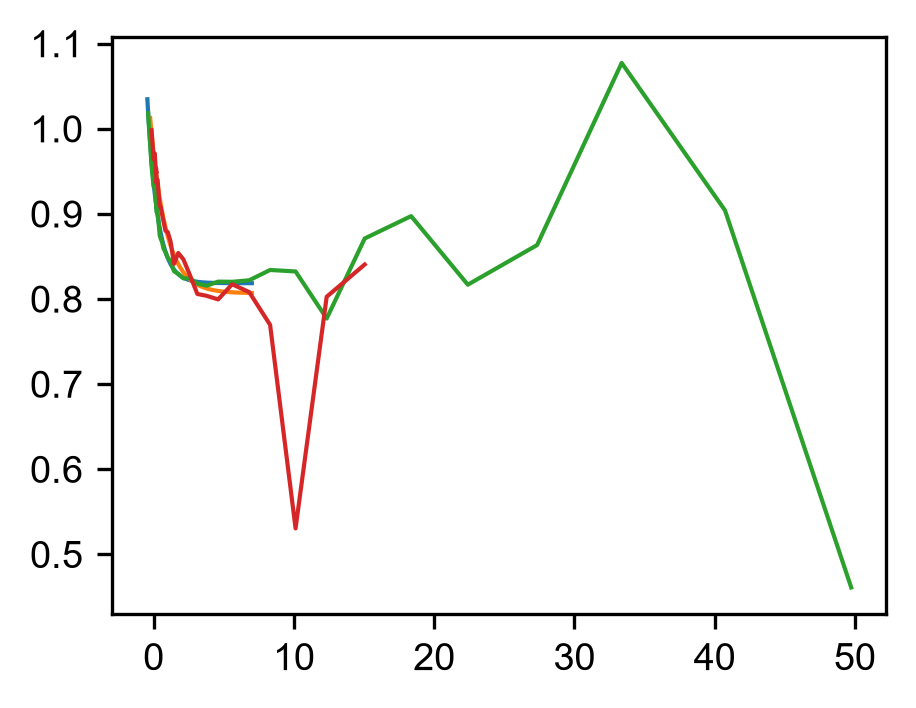

In [73]:
#for saving
# plt.plot(*totalCountsTrace,'o')
# plt.plot(*totalCountsFit)

# plt.plot(*retrievedTrace,'o')
# plt.plot(*retrievedFit)


plt.plot(*average_eKE_fit)
plt.plot(*retrieved_eKE_fit)
plt.plot(*average_eKE_trace)
plt.plot(*retrieved_eKE_trace)

##### Save data

In [74]:
#Save data
if False:
    savePath = cpath+r"/[CHANGE]\PhD\Thesis\Data\Chapter 5\Figure 5.6/"

    np.savetxt(savePath+"total_counts_trace.csv",totalCountsTrace.T,
           header="Delay / ps, Counts",
           delimiter=','
          )
    np.savetxt(savePath+"total_counts_fit.csv",totalCountsFit.T,
           header="Delay / ps, Counts",
           delimiter=','
          )
    np.savetxt(savePath+"retrieved_counts_trace.csv",retrievedTrace.T,
           header="Delay / ps, Counts",
           delimiter=','
          ) 
    np.savetxt(savePath+"retrieved_counts_fit.csv",retrievedFit.T,
           header="Delay / ps, Counts",
           delimiter=','
          )

    #eke
    np.savetxt(savePath+"average_eKE_fit.csv",average_eKE_fit.T,
       header="Delay / ps, eKE / eV",
       delimiter=','
      )
    np.savetxt(savePath+"retrieved_eKE_fit.csv",retrieved_eKE_fit.T,
       header="Delay / ps, eKE / eV",
       delimiter=','
      )
    np.savetxt(savePath+"average_eKE_trace.csv",average_eKE_trace.T,
       header="Delay / ps, eKE / eV",
       delimiter=','
      )
    np.savetxt(savePath+"retrieved_eKE_trace.csv",retrieved_eKE_trace.T,
       header="Delay / ps, eKE / eV",
       delimiter=','
      )



    

In [75]:
1239.8/266.7 - 0.969, 1239.8/350.0 - (1239.8/266.7 - 0.969)

(3.679668916385452, -0.13738320209973764)

### Evolution-associated spectra

#### The model

See notebook for derivation

In [76]:
def I(t,k,sigma):
    """Monoexponential helper function"""
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2*(k1/(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    

def kinetic_model_gau(x,A1,A2,tau1,tau2):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A_model(x-t0,A1,tau1,sigma) + B_model(x-t0,A2,tau1,tau2,sigma)

def global_fit(flat_delays, tau1, tau2, *amplitudes):
    traces_number = 70
    points_per_trace = 47

    delays = flat_delays.reshape(traces_number, points_per_trace)
    amps = np.array(amplitudes).reshape(traces_number, 2)  

    return kinetic_model_gau(
        delays,
        amps[:, 0][:, None], 
        amps[:, 1][:, None],
        tau1, tau2,
    ).ravel()

#### Flatten delays + traces

In [77]:
#Mask traces
mask = scanSet.energies_rebinned<2.2
traces = scanSet.subtracted_rebinned[:,mask]
traces.shape

(47, 70)

In [78]:
# Normalise traces
#Total counts
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
traces /= max(trace)

In [79]:
#Flatten delays
delays = scanSet.delays-scanSet.t0
# Tile delays
flat_delays = np.tile(delays,(traces.shape[1]))
#Flatten traces
flat_traces = traces.T.flatten() 
flat_traces.shape,flat_delays.shape

((3290,), (3290,))

#### Fit

In [80]:
p0 = [1,3.5]+[x for n in range(70) for x in (2*n, n)]

params,pcov = curve_fit(global_fit,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
perr = np.sqrt(np.diag(pcov))
params[:2],params[2:]

(array([0.54994703, 2.8432842 ]),
 array([ 1.59187902e-02, -5.87488963e-04,  1.56286062e-02, -2.39795880e-04,
         1.90217407e-02,  1.99860576e-03,  2.27903181e-02, -4.20828549e-04,
         2.10729304e-02,  3.05283403e-03,  2.87973014e-02,  4.12545394e-03,
         3.84547401e-02,  4.91153363e-03,  4.60567353e-02,  2.85401202e-03,
         6.21095380e-02,  6.36141561e-03,  7.64091004e-02,  1.62730053e-02,
         1.02820898e-01,  1.88643767e-02,  1.29392626e-01,  2.70571863e-02,
         1.59954235e-01,  3.21418610e-02,  2.07340557e-01,  5.42566272e-02,
         2.56452238e-01,  7.05399776e-02,  3.01083671e-01,  9.10440312e-02,
         3.48860728e-01,  1.16282890e-01,  4.05568940e-01,  1.58477213e-01,
         4.66195813e-01,  1.92471684e-01,  5.25669226e-01,  2.25041451e-01,
         6.06629006e-01,  2.47941050e-01,  6.59976850e-01,  3.13449064e-01,
         7.06978514e-01,  3.75863537e-01,  7.82961540e-01,  4.40067582e-01,
         8.64824553e-01,  4.63001295e-01,  9.23674846e

#### Plot results of fit and residuals for each trace

0.5499470273833391 2.8432842042892514


(-1.0, 5.0)

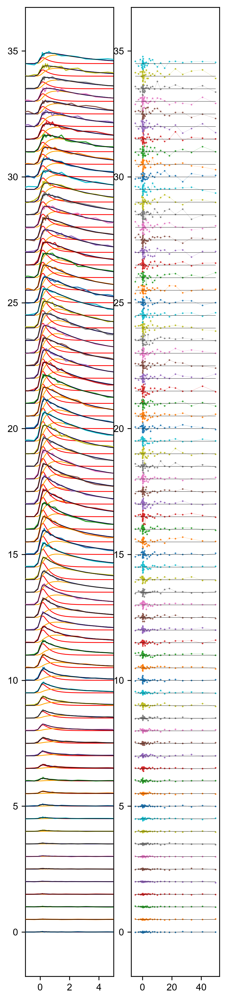

In [81]:
fig, (ax0,ax1) = plt.subplots(1,2)
# params=p0
tau1,tau2, amplitudes = params[0],params[1],params[2:]
tau1_err,tau2_err, amplitudes_err = perr[0],perr[1],perr[2:]
print(tau1,tau2)
sigma = 0.320 / 2.355 #cross-correlation with 250 & 267
t0 = 0

for n in range(70):
    
    ax0.plot(delays,traces[:,n]+.5*n,zorder=20)
    
    trace = kinetic_model_gau(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax0.plot(delays,trace+.5*n,'k',zorder=30,lw=.5)
    
    
    trace =  A_model(delays,amplitudes[2*n],tau1,sigma)
    ax0.plot(delays,trace+.5*n,'r',lw=.75)
    
    trace =  B_model(delays,amplitudes[2*n+1],tau1,tau2,sigma)
    ax0.plot(delays,trace+.5*n,'orange',lw=.75)
    ax0.plot(delays,A_model(delays,amplitudes[2*n],tau1,sigma)+trace+.5*n,'b',lw=.75)

    # Residuals
    trace = kinetic_model_gau(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax1.plot(delays,3*(traces[:,n]-trace)+.5*n,'o-',zorder=20,ms=.5,lw=.1)
    ax1.plot(delays,delays*0+.5*n,'k',zorder=30,lw=.25)
    
ax1.set_ylim(ax0.get_ylim())
plt.gcf().set_size_inches(ACSwid,ACSwid*5)

ax0.set_xlim(-1,5)

In [82]:
traces

array([[-3.64998907e-03,  6.47297719e-03,  1.13412629e-02, ...,
         2.99130713e-02,  4.92205014e-02,  3.09910069e-02],
       [ 4.78544460e-04, -4.21496416e-04,  5.69339587e-03, ...,
        -1.74699873e-03,  3.05490240e-02, -3.32661181e-02],
       [ 4.49983828e-03,  3.65222922e-03,  3.77695538e-03, ...,
        -3.87153323e-02,  5.88021951e-02,  5.56641875e-02],
       ...,
       [-1.58215511e-05, -2.78059513e-03,  2.35469882e-03, ...,
        -3.11102383e-03,  6.81427407e-02,  2.30405453e-02],
       [ 3.60368848e-03, -4.97424832e-04,  5.69698688e-03, ...,
         4.06400129e-02,  8.34519026e-02,  2.91259027e-02],
       [-4.84183535e-04,  6.97845874e-03, -1.88846722e-03, ...,
        -4.37383652e-02, -2.75148418e-02,  1.82110962e-02]],
      shape=(47, 70))

#### Residuals heatmap

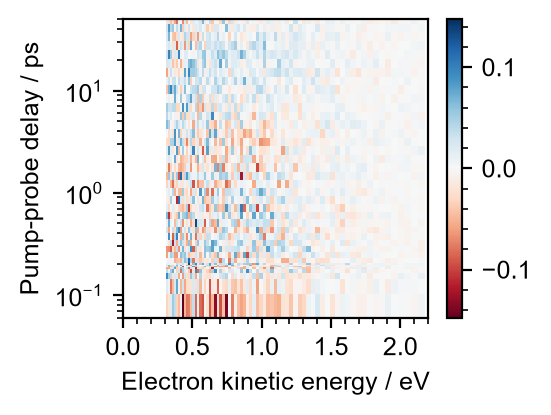

In [83]:
fig,ax = plt.subplots()
fig.set_dpi(200)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

im0 = ax.pcolormesh(scanSet.energies_rebinned[mask],
                    delays,
                    flat_traces.reshape(70,47).T-
                    global_fit(flat_delays,*params).reshape(70,47).T,
                    cmap='RdBu',
                    # shading='gouraud',
                    norm = mcolors.CenteredNorm()
                   )
ax.set_xlim(0,2.2)
ax.set_ylim(-0.16,8.3)
ax.set_yscale('log')
ax.set_ylim(0.06,50)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
cbar = plt.colorbar(im0)
cbar.ax.yaxis.set_major_locator(MultipleLocator(.1))
cbar.ax.yaxis.set_minor_locator(MultipleLocator(.02))
plt.savefig('Residuals/Residuals_EAS_H2O.png',dpi=fig.dpi,bbox_inches='tight')


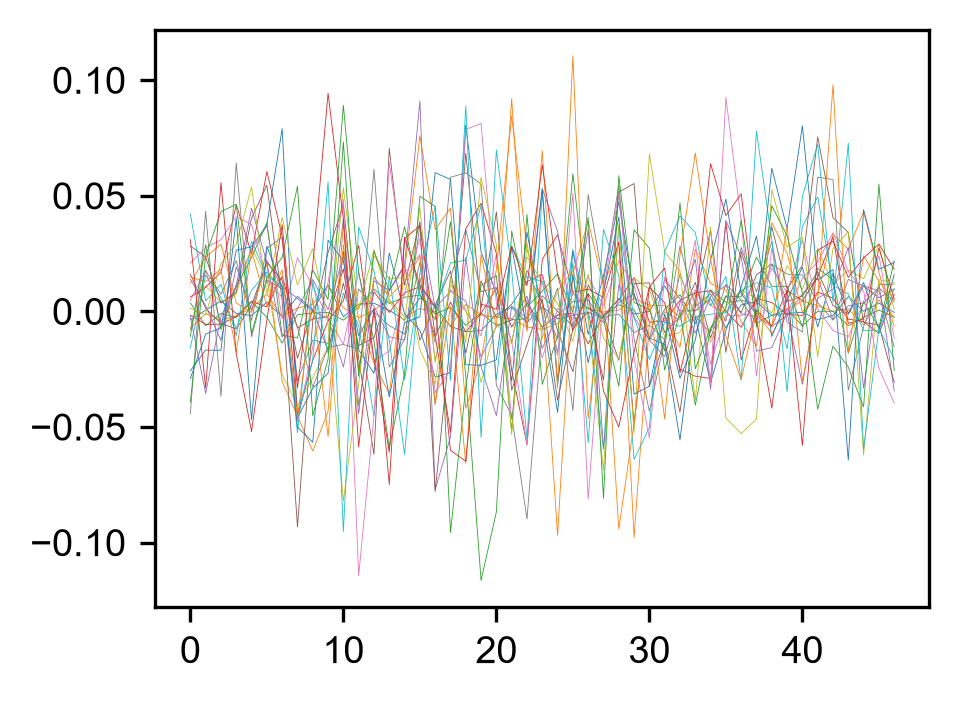

In [84]:
for i in range(0,70,3):
    plt.plot((flat_traces.reshape(70,47).T-
                    global_fit(flat_delays,*params).reshape(70,47).T)[:,i],lw=.2)

#### Plot EAS

Text(0, 0.5, 'Photoelectron signal / a.u.')

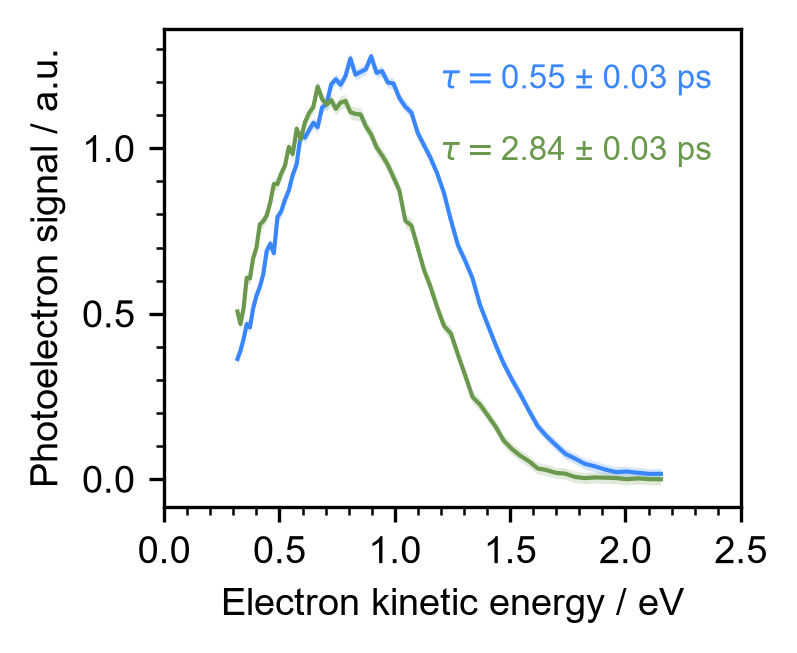

In [85]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)

A1s = amplitudes[0::2]
A2s = amplitudes[1::2]
A1s_err = amplitudes_err[0::2]
A2s_err = amplitudes_err[1::2]
energies = scanSet.energies_rebinned[mask]

ax.plot(energies,A1s,'-',c=blue,ms=1,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
ax.plot(energies,A2s,'-',c=green,ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.2,color=blue,lw=0)
ax.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.2,color=green,lw=0)

ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
# ax.set_ylim(0,1.2)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")


In [86]:
A1s_EAS = amplitudes[0::2]
A2s_EAS = amplitudes[1::2]
A1s_err_EAS = amplitudes_err[0::2]
A2s_err_EAS = amplitudes_err[1::2]
energies_EAS = scanSet.energies_rebinned[mask]

params_EAS = params

In [87]:
def global_fit_EAS(flat_delays, tau1, tau2, *amplitudes,time_points=47):
    traces_number = 70
    points_per_trace = time_points

    delays = flat_delays.reshape(traces_number, points_per_trace)
    amps = np.array(amplitudes).reshape(traces_number, 2)  

    return kinetic_model_gau(
        delays,
        amps[:, 0][:, None], 
        amps[:, 1][:, None],
        tau1, tau2,
    ).ravel()

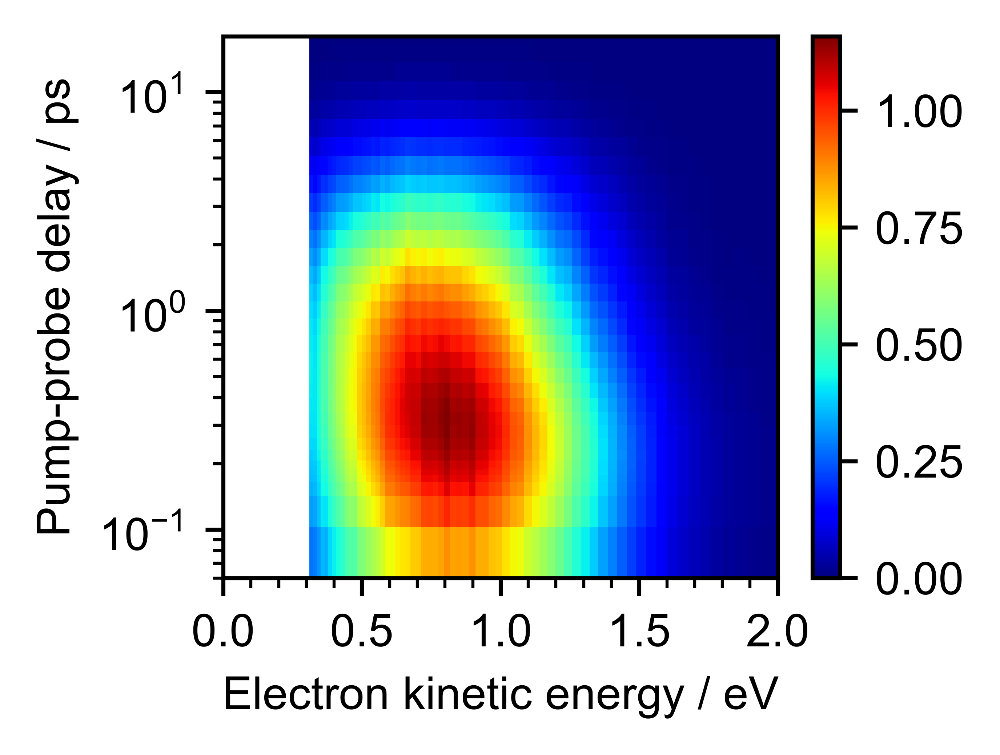

In [88]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)


im0 = ax.pcolormesh(scanSet.energies_rebinned[mask],
                    delays,

                    global_fit(flat_delays,*params).reshape((70, 47)).T,
                    cmap='jet',
                    # shading='gouraud',

                   )


ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
ax.set_yscale('log')
ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
# ax.yaxis.set_major_locator(MultipleLocator(1))
# ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

[1.26911737 0.87260793 0.87861502]
[1.16073145 0.74739626 0.80868385]


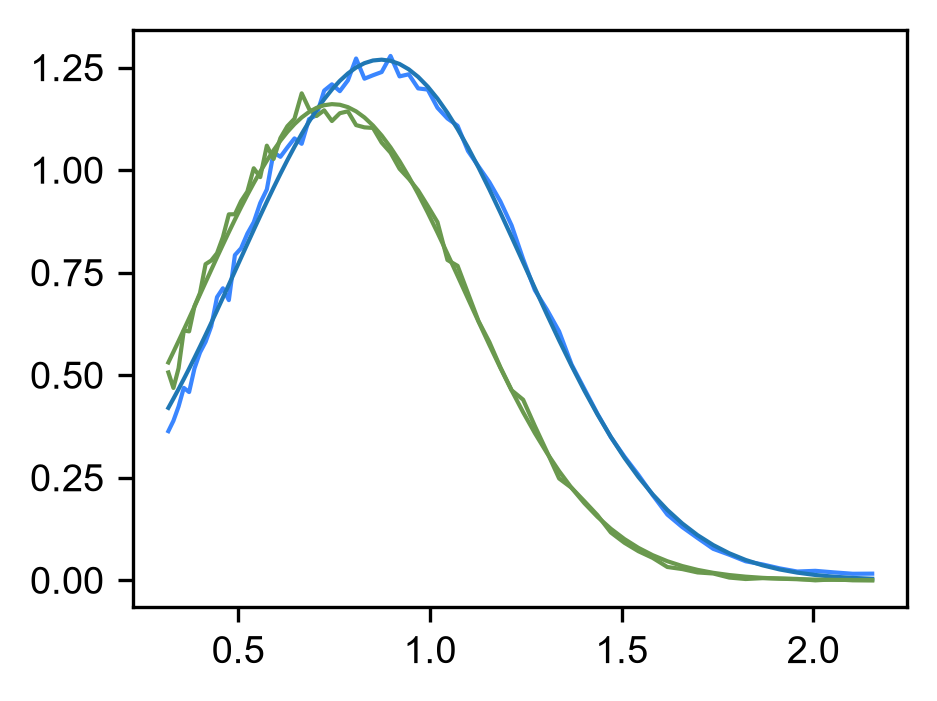

In [89]:
#Gaussian fits for approximate centres
plt.plot(energies,A1s,'-',c=blue,ms=1,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
plt.plot(energies,A2s,'-',c=green,ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

params,_ = curve_fit(multiple_gaussians,energies,A1s,p0=[1,1,1])
plt.plot(energies,multiple_gaussians(energies,*params))
print(params)
params,_ = curve_fit(multiple_gaussians,energies,A2s,p0=[1,1,1])
plt.plot(energies,multiple_gaussians(energies,*params),c=green)
print(params)

### Decay associated spectra

#### The model

In [90]:
def biexponential(x,A1,A2,tau1,tau2):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma)))) + A2/2 * np.exp((-1/tau2)*(x-0))*np.exp((sigma**2)/(2*(tau2**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau2))/(np.sqrt(2.0)*sigma))))

def global_fit(flat_delays, tau1, tau2, *amplitudes):
    traces_number = 70
    points_per_trace = 47

    delays = flat_delays.reshape(traces_number, points_per_trace)
    amps = np.array(amplitudes).reshape(traces_number, 2)  

    return biexponential(
        delays,
        amps[:, 0][:, None], 
        amps[:, 1][:, None],
        tau1, tau2,
    ).ravel()

#### Flatten delays + traces

In [91]:
#Mask traces
mask = scanSet.energies_rebinned<2.2
traces = np.copy(scanSet.subtracted_rebinned)[:,mask]


In [92]:
# Normalise traces
#Total counts
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
traces /= max(trace)

In [93]:
#Flatten delays
delays = scanSet.delays-scanSet.t0
# Tile delays
flat_delays = np.tile(delays,(traces.shape[1]))
#Flatten traces
flat_traces = traces.T.flatten() 
flat_traces.shape,flat_delays.shape

((3290,), (3290,))

#### Fit

In [94]:
p0 = [1,3.5]+[x for n in range(70) for x in (2*n, n)]

params,pcov = curve_fit(global_fit,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
perr = np.sqrt(np.diag(pcov))
params[:2],params[2:]

(array([0.54995534, 2.84328509]),
 array([ 1.66468969e-02, -7.28293668e-04,  1.59258603e-02, -2.97346526e-04,
         1.65436495e-02,  2.47792460e-03,  2.33117375e-02, -5.21662682e-04,
         1.72879519e-02,  3.78487017e-03,  2.36825772e-02,  5.11462432e-03,
         3.23654454e-02,  6.08915994e-03,  4.25181088e-02,  3.53834013e-03,
         5.42228084e-02,  7.88654993e-03,  5.62335776e-02,  2.01751720e-02,
         7.94324670e-02,  2.33879235e-02,  9.58466360e-02,  3.35453653e-02,
         1.20104536e-01,  3.98490805e-02,  1.40072799e-01,  6.72669931e-02,
         1.68996018e-01,  8.74551824e-02,  1.88207442e-01,  1.12875503e-01,
         2.04692843e-01,  1.44166886e-01,  2.09089359e-01,  1.96478942e-01,
         2.27569098e-01,  2.38625688e-01,  2.46662752e-01,  2.79005485e-01,
         2.99232181e-01,  3.07395853e-01,  2.71362884e-01,  3.88613046e-01,
         2.40983015e-01,  4.65994740e-01,  2.37366078e-01,  5.45594860e-01,
         2.90795570e-01,  5.74028026e-01,  2.80102967e

#### Plot results of fit and residuals for each trace

0.5499553422572641 2.8432850861738936


(-1.0, 5.0)

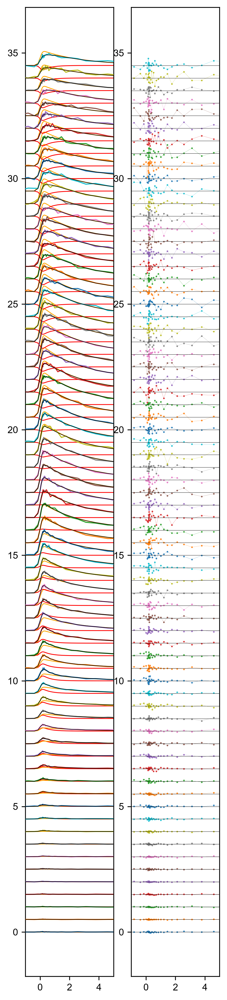

In [95]:
fig, (ax0,ax1) = plt.subplots(1,2)
# params=p0
tau1,tau2, amplitudes = params[0],params[1],params[2:]
tau1_err,tau2_err, amplitudes_err = perr[0],perr[1],perr[2:]
print(tau1,tau2)
sigma = 0.320 / 2.355 #cross-correlation with 250 & 267
t0 = 0

for n in range(70):
    
    ax0.plot(delays,traces[:,n]+.5*n,zorder=20)
    
    trace = biexponential(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax0.plot(delays,trace+.5*n,'k',zorder=30,lw=.5)
    
    
    trace =  A_model(delays,amplitudes[2*n],tau1,sigma)
    ax0.plot(delays,trace+.5*n,'r',lw=.75)
    
    trace =  A_model(delays,amplitudes[2*n+1],tau2,sigma)
    ax0.plot(delays,trace+.5*n,'orange',lw=.75)

    # Residuals
    trace = biexponential(delays,amplitudes[2*n],amplitudes[2*n+1],tau1,tau2)
    ax1.plot(delays,3*(traces[:,n]-trace)+.5*n,'o-',zorder=20,ms=.5,lw=.1)
    ax1.plot(delays,delays*0+.5*n,'k',zorder=30,lw=.25)
    
ax1.set_ylim(ax0.get_ylim())
plt.gcf().set_size_inches(ACSwid,ACSwid*5)

ax0.set_xlim(-1,5)
ax1.set_xlim(-1,5)

#### Plot DAS

Text(0, 0.5, 'Photoelectron signal / a.u.')

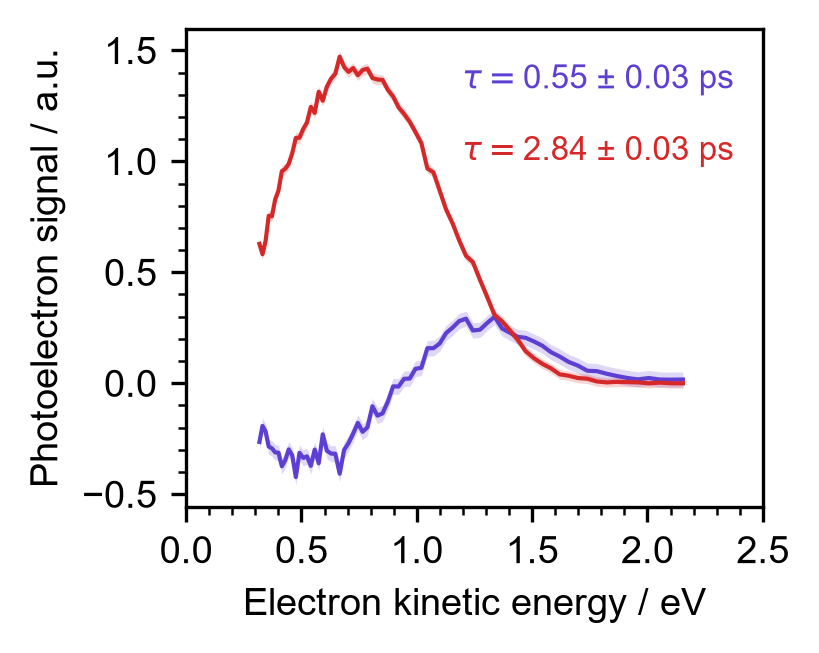

In [96]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)

A1s = amplitudes[0::2]
A2s = amplitudes[1::2]
A1s_err = amplitudes_err[0::2]
A2s_err = amplitudes_err[1::2]
energies = scanSet.energies_rebinned[mask]

ax.plot(energies,A1s,'-',c=violet,ms=1,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
ax.plot(energies,A2s,'-',c=red,ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")
# ax.plot(energies,A1s+A2s,'-',c='k',ms=1,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.2,color=violet,lw=0)
ax.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.2,color=red,lw=0)

ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=violet,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=red,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
# ax.set_ylim(0,1.2)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")


In [97]:
A1s_DAS = amplitudes[0::2]
A2s_DAS = amplitudes[1::2]
A1s_err_DAS = amplitudes_err[0::2]
A2s_err_DAS = amplitudes_err[1::2]
energies_DAS = scanSet.energies_rebinned[mask]
taus_DAS = tau1,tau2
tau_errs_DAS = tau1_err,tau2_err

params_DAS = params

In [98]:
### to allow for different shape of delays

def global_fit_DAS(flat_delays, tau1, tau2, *amplitudes,time_points=47):
    traces_number = 70
    points_per_trace = time_points

    delays = flat_delays.reshape(traces_number, points_per_trace)
    amps = np.array(amplitudes).reshape(traces_number, 2)  

    return biexponential(
        delays,
        amps[:, 0][:, None], 
        amps[:, 1][:, None],
        tau1, tau2,
    ).ravel()

#### Average lifetime from plot

3.1850000000027343


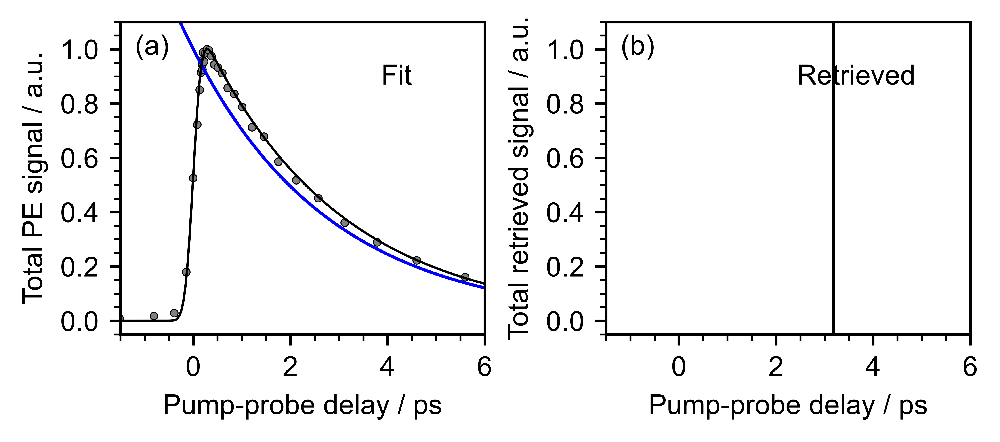

In [99]:

fig = plt.figure()
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2.25*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1.8,0.00,0.00,0.6,1.8],
                      height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
# ax1b = fig.add_subplot(gs[:, 2])
ax2 = fig.add_subplot(gs[:, 4])
# ax2b = fig.add_subplot(gs[1, 4])

axes = ax1,ax2

ts = np.arange(-5,100,.001)


#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)

#### Total counts and total scattered spectra
#DAS
delays = scanSet.delays-scanSet.t0
flat_ts = np.tile(ts,70)
#Integrated total fit
sum_DAS = global_fit_DAS(flat_ts,*params_DAS,time_points=len(ts)).reshape(70,len(ts))
sum_DAS = -np.trapezoid(sum_DAS,axis=0,x=scanSet.energies_rebinned[mask])
total_DAS = max(sum_DAS)
#Integrate monoexponentials
params_DAS1 = np.copy(params_DAS)
params_DAS1[3::2] = 0
sum_DAS1 = global_fit_DAS(flat_ts,*params_DAS1,time_points=len(ts)).reshape(70,len(ts))
sum_DAS1 = -np.trapezoid(sum_DAS1,axis=0,x=scanSet.energies_rebinned[mask])

#Integrate monoexponentials
params_DAS2 = np.copy(params_DAS)
params_DAS2[2::2] = 0
sum_DAS2 = global_fit_DAS(flat_ts,*params_DAS2,time_points=len(ts)).reshape(70,len(ts))
sum_DAS2 = -np.trapezoid(sum_DAS2,axis=0,x=scanSet.energies_rebinned[mask])

for ax in ax1,:
    ax.plot(delays,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)

    # ax.plot(ts,sum_DAS1/total_DAS,'--',c=blue)
    # ax.plot(ts,sum_DAS2/total_DAS,'--',c=green)
    ax.plot(ts,sum_DAS/total_DAS,'k',lw=.75,zorder=10)
    ax.plot(-10,-10,'k--',label="DAS")
    
    ax.plot(ts,np.exp(-ts/taus_DAS[1]),'b')

    #Find 1/e
    idx = (np.abs(sum_DAS/total_DAS - np.exp(-1))).argmin()
    ax2.vlines([ts[idx]],-1,50,'k','-')
    print(ts[idx])



#Formatting trace
for ax in axes:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.05,1.1)
    # ax.set_yscale('log')
    # ax.set_ylim(5e-2,1.5e0)
    ax.set_xlim(-1.5,6)
    ax.yaxis.set_major_locator(MultipleLocator(.2))
    ax.yaxis.set_minor_locator(MultipleLocator(.05))
    ax.set_xlabel("Pump-probe delay / ps",)

    # ax.hlines(np.exp(-1),-5,50,'k','--')
ax1.set_ylabel("Total PE signal / a.u.")
ax2.set_ylabel("Total retrieved signal / a.u.")

   




# ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1.text(.8,.8,f"Fit",ha='right',c='k',transform=ax1.transAxes)
ax2.text(.85,.8,f"Retrieved",ha='right',c='k',transform=ax2.transAxes)

for ax,indx in zip((ax1,ax2),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.04,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)



### Checking EAS <-> DAS is correct 

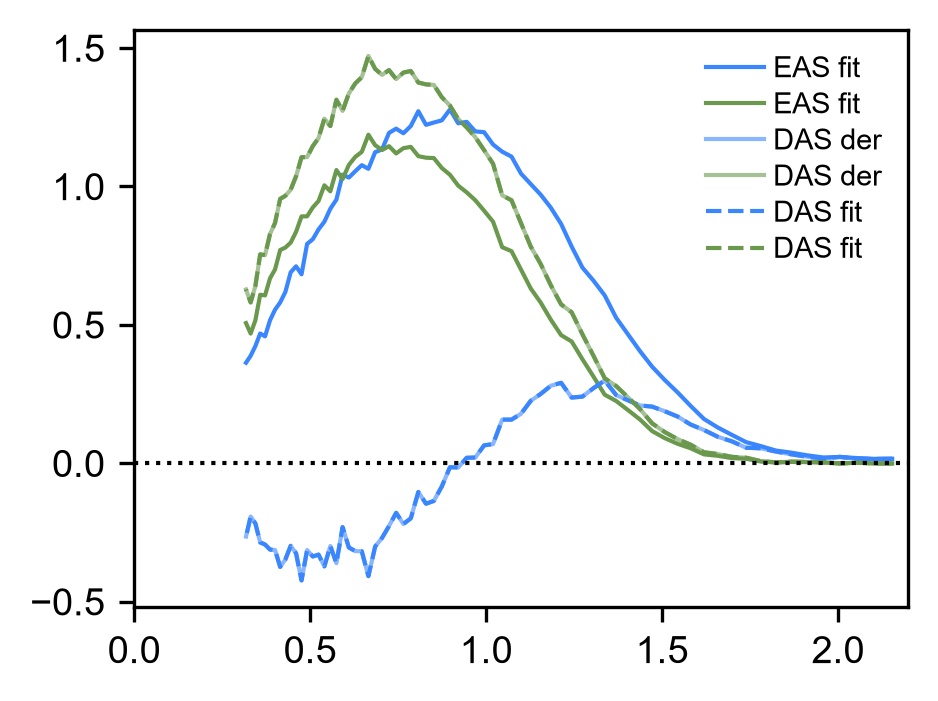

In [100]:
#Deriving DAS from EAS

A1 = A1s_EAS
A2 = A2s_EAS

plt.plot(energies_DAS,A1,blue,label='EAS fit')
plt.plot(energies_DAS,A2,green,label='EAS fit')

k_term = (1/tau1/(1/tau2-1/tau1))

D_A1= A1 + k_term * A2
D_A2 = -k_term * A2
plt.plot(energies_DAS,D_A1,blue,alpha=.6,label='DAS der')
plt.plot(energies_DAS,D_A2,green,alpha=.6,label='DAS der')

plt.plot(energies_DAS,A1s_DAS,'--',c=blue,alpha=1,label='DAS fit')
plt.plot(energies_DAS,A2s_DAS,'--',c=green,alpha=1,label='DAS fit')

plt.hlines(0,0,5,'k',':')
plt.xlim(0,2.2)
plt.legend()

### Decaying Gaussians

#### The model

In [111]:
# Get min_eKE of spectra
# It should be the same for all of them so extrcting it from the first here
fittableData = np.array((scanSet.energies,scanSet.subtracted[0]))
min_eKE = min(fittableData[0])

In [112]:
#Settings
crossSectionSetInd = 0
thresholdInd = 6
surfInd = 6
num_surface = 5
num_bulk = 5
print(f"Cross-section set: {crossSectionSets[crossSectionSetInd]}")
print(f"Escape threshold: {E0s[thresholdInd]} eV")
print(f"Concentration profile G amplitude: {concAmps[surfInd]}")
print(f"Surface gaussians: {num_surface}")
print('-'*8)
surf_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,surfInd]
bulk_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,0]
surf_bas /= np.amax(surf_bas)


Cross-section set: 1b
Escape threshold: 1.0 eV
Concentration profile G amplitude: 4.6
Surface gaussians: 5
--------


In [113]:
# Global fit
delays = scanSet.delays-scanSet.t0
basis = surf_bas


In [114]:
def monoexponential(x,A1,tau1):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))

def I(t,k,sigma):
    """Monoexponential helper function"""
    tau1=1/k
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))
    # return 1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2*(k1/(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    
def retrieval_function(x,a1,c1,f1,a2,c2,f2):
    # fwhm to wid
    w1,w2 = f1*0.60056,f2*.60056
    # print(a1.shape,x.shape)
    y1 =  a1 * np.exp( -((x - c1)/w1)**2)
    y2 =  a2 * np.exp( -((x - c2)/w2)**2)
    
    # y1 = np.sum(basis.T * y1, axis=1)
    y1 = (basis.T @ y1) # matrix multipication
    y2 = (basis.T @ y2) # matrix multipication
    return (y1+y2)[x>=min_eKE]

def global_fit(flat_energies,amp1,centre1,fwhm1,amp2,centre2,fwhm2, tau1, tau2):
    sig = 0.320 / 2.355  # cross-correlation with 250 & 267

    energy_len = 500
    points_per_trace = 47

    energies = flat_energies.reshape(points_per_trace,energy_len).T
    
    # a1 = monoexponential(delays,amp1,tau1)
    # a2 = monoexponential(delays,amp2,tau2)
    a1 = A_model(delays,amp1,tau1,sig)
    a2 = B_model(delays,amp2,tau1,tau2,sig)
    c1 = amp*0 + centre1
    c2 = amp*0 + centre2
    f1 = amp*0 + fwhm1
    f2 = amp*0 + fwhm2
    return retrieval_function(energies,a1,c1,f1,a2,c2,f2).ravel()

#### Flatten delays + spectra

In [407]:
#Flatten energies
energies = np.arange(0.01,5.01,0.01)
flat_energies = np.tile(energies,47)

#Define delays
delays = scanSet.delays-scanSet.t0



In [116]:
# Rebin and flatten spectra
flat_spectra = []
for spectrum in scanSet.subtracted:
    data = np.array((scanSet.energies,spectrum))
    flat_spectra.append(rebinData(data,min_eKE,nanWarningSuppress=True)[1])
flat_spectra  =np.array(flat_spectra).T.flatten()
flat_spectra.shape[0]/47

C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


469.0

In [117]:
flat_energies.shape

(23500,)

#### Fit

In [118]:
p0 = [1,1.,1,
      1,1.3,1,
     0.5,2.8]

params,pcov = curve_fit(global_fit,flat_energies,flat_spectra,
                        p0 = p0,bounds=(0,np.inf),)
perrs = np.sqrt(np.diag(pcov))
params,perrs

(array([0.65602105, 0.98988132, 0.78525911, 0.69150772, 0.84298425,
        0.70449488, 0.58855043, 2.80745203]),
 array([0.0016104 , 0.0016021 , 0.00225173, 0.00300126, 0.00163543,
        0.00315264, 0.01630593, 0.0144996 ]))

In [119]:
print(f"G1: eKE = {params[1]:.4f}, FWHM = {params[2]:.4f}, eBE = {1239.8/266.67- params[1]:.4f}, tau = {params[6]:.4f} ps")
print(f"G2: eKE = {params[4]:.4f}, FWHM = {params[5]:.4f}, eBE = {1239.8/266.67- params[4]:.4f}, tau = {params[7]:.4f} ps")


G1: eKE = 0.9899, FWHM = 0.7853, eBE = 3.6593, tau = 0.5886 ps
G2: eKE = 0.8430, FWHM = 0.7045, eBE = 3.8062, tau = 2.8075 ps


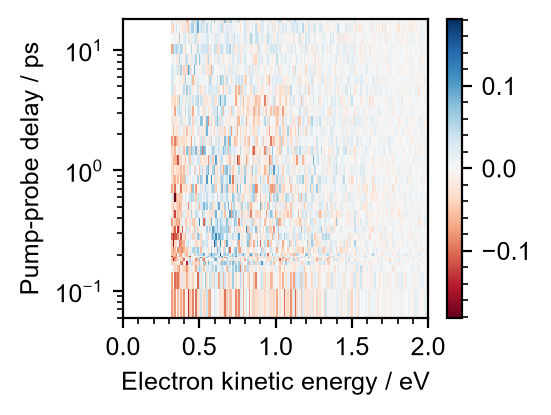

In [120]:
fig,ax = plt.subplots()
fig.set_dpi(200)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

energies_cutoff = energies[energies>=min_eKE]

im0 = ax.pcolormesh(energies_cutoff,
                    delays,
                    flat_spectra.reshape(len(energies_cutoff),47).T-
                    global_fit(flat_energies,*params).reshape(len(energies_cutoff),47).T,
                    cmap='RdBu',
                    # shading='gouraud',
                    norm = mcolors.CenteredNorm()
                   )
ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
ax.set_yscale('log')
ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
cbar = plt.colorbar(im0)
cbar.ax.yaxis.set_major_locator(MultipleLocator(.1))
cbar.ax.yaxis.set_minor_locator(MultipleLocator(.02))
plt.savefig('Residuals/Residuals_doubleG_H2O.png',dpi=fig.dpi,bbox_inches='tight')


IndexError: index 50 is out of bounds for axis 0 with size 47

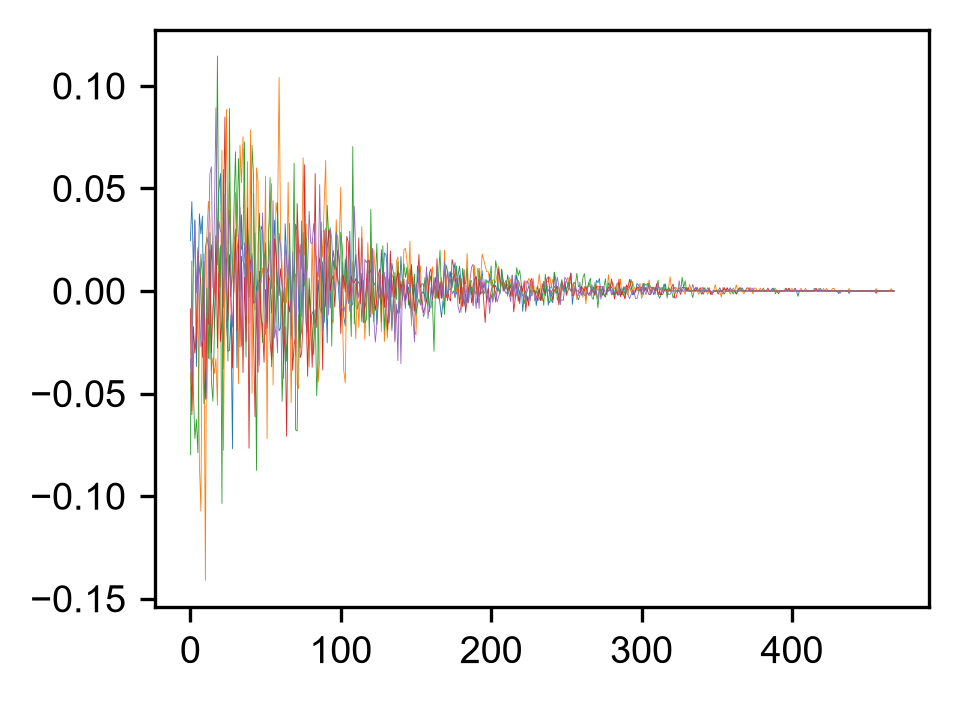

In [121]:
for i in range(0,len(energies_cutoff),10):
    plt.plot((flat_spectra.reshape(len(energies_cutoff),47).T-
            global_fit(flat_energies,*params).reshape(len(energies_cutoff),47).T)[i,:],
             lw=.2)

#### Plot retrieved

[0.656, 0.9899, 0.7853, 0.6915, 0.843, 0.7045, 0.5886, 2.8075]
[0.0016, 0.0016, 0.0023, 0.003, 0.0016, 0.0032, 0.0163, 0.0145]
[7.2, 7.35]
[3.6593, 3.8062]
0.9486821789365776


C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\2552154755.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


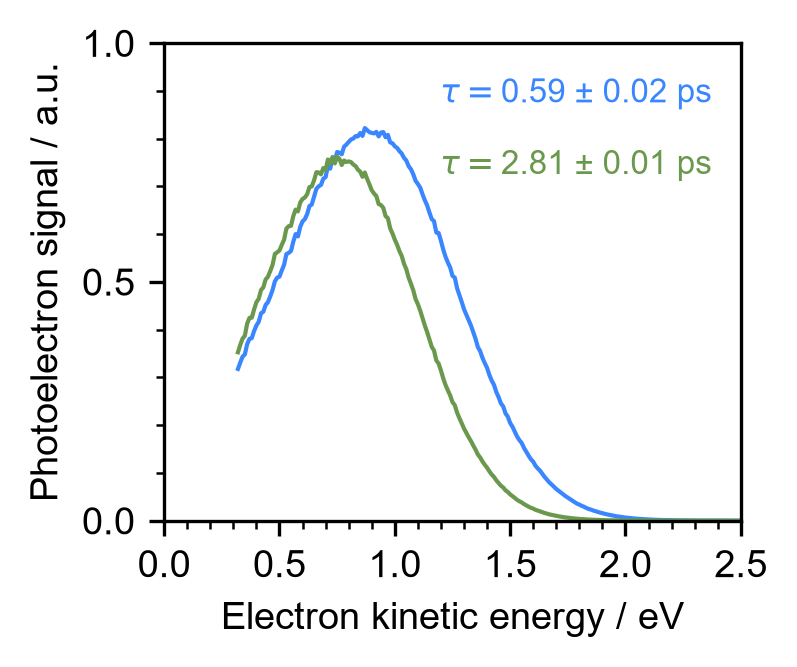

In [122]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)
tau1,tau2 = params[-2:]
tau1_err,tau2_err = perrs[-2:]

# ax.plot(energies,multiple_gaussians(energies,*params[:3]),c=blue,alpha=.5,label=f"$\\tau_1=${params[-2]:.2f}")
ax.plot(energies_cutoff,retrieval_function(energies,*params[:3],0,0,1),c=blue)

# ax.plot(energies,multiple_gaussians(energies,*params[3:6]),c=green,alpha=.5,label=f"$\\tau_2=${params[-1]:.2f}")
ax.plot(energies_cutoff,retrieval_function(energies,*params[3:6],0,0,1),c=green)

print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perrs])
print([float(f"{1239.8/350 + 1239.8/266.67 - p:.2f}") for p in params[1:6:3]])
print([float(f"{1239.8/266.67 - p:.4f}") for p in params[1:6:3]])


ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
ax.set_ylim(0,1.)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")
plt.legend()
print(params[0]/params[3])

In [129]:
print(f"Ratio of blue and green peak area: {((params[0]*params[2])/(params[3]*params[5])):.2f}")

Ratio of blue and green peak area: 1.06


In [128]:
# amp1,centre1,fwhm1,amp2,centre2,fwhm2, tau1, tau2
print(f"Ratio of blue and green peak area: {((params[0]*params[2])/(params[3]*params[5])):.2f}")
((params[0]*params[2])/(params[3]*params[5]+params[0]*params[2]),
(params[3]*params[5])/(params[3]*params[5]+params[0]*params[2]))

Ratio of blue and green peak area: 1.06


(np.float64(0.513959182434264),
 np.float64(0.5885504276605007),
 np.float64(0.48604081756573597))

In [ ]:
A1 = retrieval_function(energies,*params[:3],0,0,1)
plt.plot(energies_cutoff,A1/max(A1),c=blue,label='Retrieval')
A2 = retrieval_function(energies,*params[3:6],0,0,1)
plt.plot(energies_cutoff,A2/max(A2)+1,c=green,label='Retrieval')
plt.xlim(0,2.2)

plt.plot(energies_DAS,A1s_EAS/max(A1s_EAS),'--',c=blue,label=f"EAS")
plt.plot(energies_DAS,A2s_EAS/max(A2s_EAS)+1,'--',c=green,label=f"EAS")
plt.legend()

#### Plot delay fit

In [ ]:
total_sig = np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(delays,1,tau1,sigma) + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(delays,1,tau1,tau2,sigma) 
# total_sig = np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(delays,1,tau1,sigma) + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*A_model(delays,1,tau2,sigma) 

plt.plot(scanSet.delays-scanSet.t0,trace-total_sig/total_norm,'k-',ms=3,mew=.6,mec=(0,0,0,0.6),mfc=(1,1,1,0),zorder=100)

plt.gcf().set_size_inches(thesisWid/2*.9,thesisWid/5*0.75)

ax = plt.gca()
ax.hlines(0,-5,300,'k',':')
ax.set_ylim(-.1,.1)
ax.set_xlim(-5.1,20)

ax.yaxis.set_major_locator(MultipleLocator(.05))
ax.yaxis.set_minor_locator(MultipleLocator(.01))
# ax.xaxis.set_major_locator(MultipleLocator(2))
# ax.xaxis.set_minor_locator(MultipleLocator(.5))

In [ ]:
#Deriving DAS

A1 = retrieval_function(energies,*params[:3],0,0,1)
A2 = retrieval_function(energies,*params[3:6],0,0,1)

plt.plot(energies_cutoff,A1,blue,label='EAS')
plt.plot(energies_cutoff,A2,green,label='EAS')

k_term = (1/tau1/(1/tau2-1/tau1))

D_A1= A1 + k_term * A2
D_A2 = -k_term * A2
plt.plot(energies_cutoff,D_A1,blue,alpha=.6,label='DAS')
plt.plot(energies_cutoff,D_A2,green,alpha=.6,label='DAS')

plt.hlines(0,0,5,'k',':')
plt.xlim(0,2.2)
plt.legend()

-np.trapezoid(D_A1,axis=0,x=energies_cutoff)


#### Average lifetime from EAS

In [ ]:
def average_decay_EAS(B1,B2,tau1,tau2):
    """B_i is the EAS amplitude
    A_i is the DAS amplitude"""
    k1, k2 = 1/tau1, 1/tau2
    A1 = B1 + (k1/(k2-k1)) * B2
    A2 = -(k1/(k2-k1)) * B2
    print(A1,A2)
    # print(A1/(A1+A2),A2/(A1+A2))

    # Intensity Average Lifetime
    # numerator = A1*tau1**2+A2*tau2**2
    # denominator = A1*tau1+A2*tau2
    
    # # Amplitude Average Lifetime
    numerator = A1*tau1+A2*tau2
    denominator = A1+A2
    # print(A1,tau1,A2,tau2)
    
    return numerator/denominator
    

In [ ]:
B1 = params[0]*params[2]
B2 = params[3]*params[5]
print(B1/(B1+B2),B2/(B1+B2))

print(f"Average lifetime retr.: {average_decay_EAS(B1,B2,tau1,tau2):.3f} ps")

#Cutoff true gaussians
B1 = np.trapezoid(multiple_gaussians(energies,*params[:3]),energies)
B2 = np.trapezoid(multiple_gaussians(energies,*params[3:6]),energies)
# Distorted Gaussians
B1 = np.trapezoid(retrieval_function(energies,*params[:3],0,0,1),energies_cutoff)
B2 = np.trapezoid(retrieval_function(energies,*params[3:6],0,0,1),energies_cutoff)

print(f"Average lifetime fit: {average_decay_EAS(B1,B2,tau1,tau2):.3f} ps")

# (B1*tau1+B2*tau2)/(B1+B2)
B1*tau1,B2*tau2

In [ ]:
B1 = -np.trapezoid(A1s_EAS,scanSet.energies_rebinned[scanSet.energies_rebinned<2.2])
B2 = -np.trapezoid(A2s_EAS,scanSet.energies_rebinned[scanSet.energies_rebinned<2.2])

print(B1/(B1+B2),B2/(B1+B2))
print(f"Average lifetime: {average_decay_EAS(B1,B2,*taus_DAS):.3f} ps")

A1 = -np.trapezoid(A1s_DAS,scanSet.energies_rebinned[scanSet.energies_rebinned<2.2])
A2 = -np.trapezoid(A2s_DAS,scanSet.energies_rebinned[scanSet.energies_rebinned<2.2])

print(A1/(A1+A2),A2/(A1+A2))
print(f"Average lifetime: {(A1*taus_DAS[0]+A2*taus_DAS[1])/(A1+A2):.3f}ps")

In [ ]:
A_model_int = np.trapezoid(A_model(ts,1,tau1,sigma)/total_norm,ts) 
B_model_int = np.trapezoid(B_model(ts,1,tau1,tau2,sigma)/total_norm,ts)
A_model_int/B_model_int,tau1/tau2

In [ ]:
taus_DAS

In [345]:
#Error analysis

#B1
B1 = params[0]*params[2]
B1_err = np.sqrt((perrs[0]*params[2])**2+(perrs[2]*params[0])**2)
print(B1,B1_err)

# B2
B2 = params[3]*params[5]
B2_err = np.sqrt((perrs[3]*params[5])**2+(perrs[5]*params[3])**2)
print(B2,B2_err)

#A1
A1 = B1 + (1/tau1/(1/tau2-1/tau1)) * B2
A1_err = 0.872278e-3
print(A1,A1_err)

#A2
A2 = -(1/tau1/(1/tau2-1/tau1)) * B2
A2_err = 0.82962154e-3
print(A2,A2_err)

#<t>
tau_avg = (A1*tau1+A2*tau2)/(A1+A2)
tau_avg_err = 1.80451147e-2
print(tau_avg,tau_avg_err)

0.5151465071124951 0.0019445435758537466
0.4871636465316281 0.003036989077969427
-0.10123439361807585 0.000872278
0.616380900730571 0.00082962154
3.243501106636794 0.0180451147


#### Average lifetime from plot

3.477000000002832
3.151000000002721


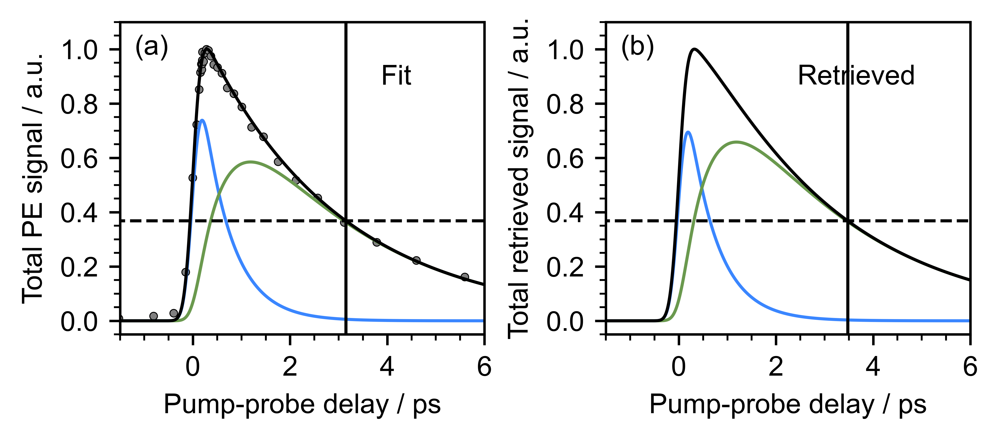

In [252]:

fig = plt.figure()
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2.25*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1.8,0.00,0.00,0.6,1.8],
                      height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
# ax1b = fig.add_subplot(gs[:, 2])
ax2 = fig.add_subplot(gs[:, 4])
# ax2b = fig.add_subplot(gs[1, 4])

axes = ax1,ax2

ts = np.arange(-5,100,.001)


#### Total total retrieved spectra
B1 = params[0]*params[2]
B2 = params[3]*params[5]
total_sig = B1*A_model(ts,1,tau1,sigma) + B2*B_model(ts,1,tau1,tau2,sigma)
total_norm = np.max(total_sig)
#Plot total and individual components
# for ax in ax1, ax1b:
ax2.plot(ts,
        B1*A_model(ts,1,tau1,sigma)/total_norm,
        '-',c=blue)
ax2.plot(ts,
        B2*B_model(ts,1,tau1,tau2,sigma)/total_norm,
        '-',c=green)
ax2.plot(ts,total_sig/total_norm,'k')
#Find 1/e
idx = (np.abs(total_sig/total_norm - np.exp(-1))).argmin()
ax2.vlines([ts[idx]],-1,50,'k','-')
print(ts[idx])
#Blue
# idx = (np.abs(A_model(ts,1,tau1,sigma) - np.exp(-1))).argmin()
# ax2.vlines(ts[idx],-1,50,blue,'-')
# print('blue',ts[idx])

    
#### Total counts and total scattered spectra
total_sig = np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma) + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,sigma) 
total_norm = np.max(total_sig)


#Plot total and individual components
for ax in ax1,:
    ax.plot(ts,
            np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma)/total_norm,
            c=blue)
    ax.plot(ts,
            np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,sigma)/total_norm,
            c=green)
    ax.plot(ts,total_sig/total_norm,'k')

    #Find closest value to 1/e
    idx = (np.abs(total_sig/total_norm - np.exp(-1))).argmin()
    ax.vlines([ts[idx]],-1,50,'k','-')
    print(ts[idx])


#This is equivalent to summing all the counts of the measured 
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)
for ax in ax1,ax1b:
    ax.plot(scanSet.delays-scanSet.t0,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)


#Formatting trace
for ax in axes:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.05,1.1)
    # ax.set_yscale('log')
    # ax.set_ylim(5e-2,1.5e0)
    ax.set_xlim(-1.5,6)
    ax.yaxis.set_major_locator(MultipleLocator(.2))
    ax.yaxis.set_minor_locator(MultipleLocator(.05))
    ax.set_xlabel("Pump-probe delay / ps",)

    ax.hlines(np.exp(-1),-5,50,'k','--')
ax1.set_ylabel("Total PE signal / a.u.")
ax2.set_ylabel("Total retrieved signal / a.u.")

   




# ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1.text(.8,.8,f"Fit",ha='right',c='k',transform=ax1.transAxes)
ax2.text(.85,.8,f"Retrieved",ha='right',c='k',transform=ax2.transAxes)

for ax,indx in zip((ax1,ax2),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.04,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)



#### Average lifetime from plot -- deconvoluted

In [253]:
def average_decay_EAS(B1,B2,tau1,tau2):
    """B_i is the EAS amplitude
    A_i is the DAS amplitude"""
    k1, k2 = 1/tau1, 1/tau2
    A1 = B1 + (k1/(k2-k1)) * B2
    A2 = -(k1/(k2-k1)) * B2
    print(A1,A2)
    # Intensity Average Lifetime
    # numerator = A1*tau1**2+A2*tau2**2
    # denominator = A1*tau1+A2*tau2
    
    # # Amplitude Average Lifetime
    numerator = A1*tau1+A2*tau2
    denominator = A1+A2
    # print(A1,tau1,A2,tau2)
    
    return numerator/denominator
    

In [254]:
B1 = params[0]*params[2]
B2 = params[3]*params[5]
print(f"Average lifetime retr.: {average_decay_EAS(B1,B2,tau1,tau2):.3f} ps")

#Cutoff true gaussians
# B1 = np.trapezoid(multiple_gaussians(energies_cutoff,*params[:3]),energies_cutoff)
# B2 = np.trapezoid(multiple_gaussians(energies_cutoff,*params[3:6]),energies_cutoff)
# Distorted Gaussians
B1 = np.trapezoid(retrieval_function(energies,*params[:3],0,0,1),energies_cutoff)
B2 = np.trapezoid(retrieval_function(energies,*params[3:6],0,0,1),energies_cutoff)

print(f"Average lifetime fit: {average_decay_EAS(B1,B2,tau1,tau2):.3f} ps")

B1,B2#*tau1,B2*tau2

-0.13959716319391147 0.847247980093206
Average lifetime retr.: 3.243 ps
-0.0001087448414021086 0.7275031809838348
Average lifetime fit: 2.807 ps


(np.float64(0.7273944361424327), np.float64(0.5741169027021347))

3.306
2.807
3.477000000002832


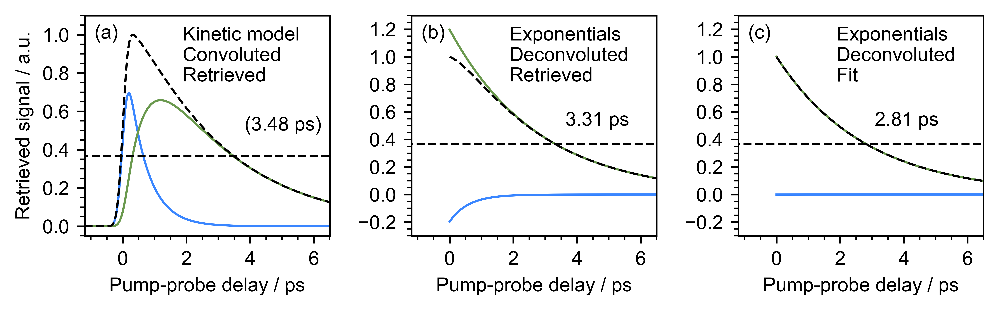

In [255]:

fig = plt.figure()
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9*1.5,thesisWid/2.25*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1.8,0.6,1.8,0.6,1.8],
                      height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
ax2 = fig.add_subplot(gs[:, 2])
ax3 = fig.add_subplot(gs[:, 4])

axes = ax1,ax2,ax3

ts = np.arange(-0,100,.001)


#### retrieved spectra
B1 = params[0]*params[2]
B2 = params[3]*params[5]

k1, k2 = 1/tau1, 1/tau2
A1 = B1 + (k1/(k2-k1)) * B2
A2 = -(k1/(k2-k1)) * B2

total_sig = A1*np.exp(-ts/tau1) + A2*np.exp(-ts/tau2)
total_norm = np.max(total_sig)
#Plot total and individual components
# for ax in ax1, ax1b:
ax2.plot(ts,
        A1*np.exp(-ts/tau1) /total_norm,
        '-',c=blue)
ax2.plot(ts,
        A2*np.exp(-ts/tau2)/total_norm,
        '-',c=green)
ax2.plot(ts,total_sig/total_norm,'k--')
#Find 1/e
idx = (np.abs(total_sig/total_norm - np.exp(-1))).argmin()
# ax2.vlines([ts[idx]],-1,.6,'k','-')
print(ts[idx])
ax2.text(ts[idx]*1.1,.5,f"{ts[idx]:.2f} ps")

    
    
# Distorted Gaussians
B1 = np.trapezoid(retrieval_function(energies,*params[:3],0,0,1),energies_cutoff)
B2 = np.trapezoid(retrieval_function(energies,*params[3:6],0,0,1),energies_cutoff)

k1, k2 = 1/tau1, 1/tau2
A1 = B1 + (k1/(k2-k1)) * B2
A2 = -(k1/(k2-k1)) * B2

total_sig = A1*np.exp(-ts/tau1) + A2*np.exp(-ts/tau2)
total_norm = np.max(total_sig)
#Plot total and individual components
# for ax in ax1, ax1b:
ax3.plot(ts,
        A1*np.exp(-ts/tau1) /total_norm,
        '-',c=blue)
ax3.plot(ts,
        A2*np.exp(-ts/tau2)/total_norm,
        '-',c=green)
ax3.plot(ts,total_sig/total_norm,'k--')
#Find 1/e
idx = (np.abs(total_sig/total_norm - np.exp(-1))).argmin()
# ax3.vlines([ts[idx]],-1,.6,'k','-')
print(ts[idx])
ax3.text(ts[idx]*1.1,.5,f"{ts[idx]:.2f} ps")
    
#### Total total retrieved spectra
ts = np.arange(-5,100,.001)

B1 = params[0]*params[2]
B2 = params[3]*params[5]
total_sig = B1*A_model(ts,1,tau1,sigma) + B2*B_model(ts,1,tau1,tau2,sigma)
total_norm = np.max(total_sig)
#Plot total and individual components

ax1.plot(ts,
        B1*A_model(ts,1,tau1,sigma)/total_norm,
        '-',c=blue)
ax1.plot(ts,
        B2*B_model(ts,1,tau1,tau2,sigma)/total_norm,
        '-',c=green)
ax1.plot(ts,total_sig/total_norm,'k--')
#Find 1/e
idx = (np.abs(total_sig/total_norm - np.exp(-1))).argmin()
# ax1.vlines([ts[idx]],-1,.6,'k','-')
print(ts[idx])
ax1.text(ts[idx]*1.1,.5,f"({ts[idx]:.2f} ps)")
#This is equivalent to summing all the counts of the measured 
# trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
# trace /= max(trace)
# for ax in ax1,:
#     ax.plot(scanSet.delays-scanSet.t0,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)


#Formatting trace
for ax in axes:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.3,1.3)
    # ax.set_yscale('log')
    # ax.set_ylim(5e-2,1.5e0)
    ax.set_xlim(-1.2,6.5)
    ax.yaxis.set_major_locator(MultipleLocator(.2))
    ax.yaxis.set_minor_locator(MultipleLocator(.05))
    ax.set_xlabel("Pump-probe delay / ps",)

    ax.hlines(np.exp(-1),-5,50,'k','--')
ax1.set_ylabel("Retrieved signal / a.u.")
# ax2.set_ylabel("Total retrieved signal / a.u.")
ax1.set_ylim(-.05,1.1)

   




# ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1.text(.4,.95,f"Kinetic model \nConvoluted\nRetrieved",ha='left',va='top',c='k',transform=ax1.transAxes)
ax2.text(.4,.95,f"Exponentials \nDeconvoluted\nRetrieved",ha='left',va='top',c='k',transform=ax2.transAxes)
ax3.text(.4,.95,f"Exponentials \nDeconvoluted\nFit",ha='left',va='top',c='k',transform=ax3.transAxes)

for ax,indx in zip((ax1,ax2,ax3),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.04,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)



#### Plot combined fit trace+EAS plot

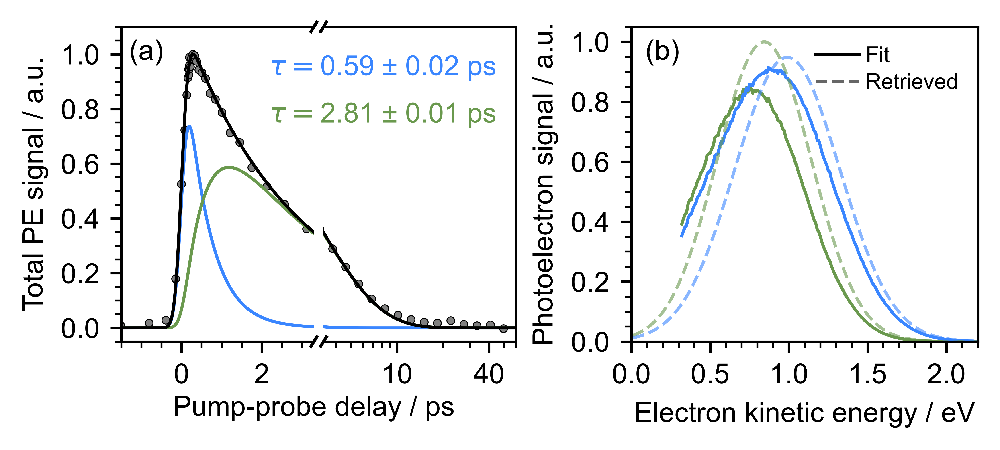

In [341]:
fig = plt.figure()
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2.25*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1,0.05,1,0.6,1.8],
                      height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
ax1b = fig.add_subplot(gs[:, 2])
ax2 = fig.add_subplot(gs[:, 4])
# ax2b = fig.add_subplot(gs[1, 4])

axes = ax1,ax1b,ax2,#ax2b

ts = np.arange(-5,100,.01)


#### Total total retrieved spectra
B1 = params[0]*params[2]
B2 = params[3]*params[5]
total_sig = B1*A_model(ts,1,tau1,sigma) + B2*B_model(ts,1,tau1,tau2,sigma)
total_norm = np.max(total_sig)
#Plot total and individual components
# for ax in ax1, ax1b:
#     ax.plot(ts,
#             B1*A_model(ts,1,tau1,sigma)/total_norm,
#             '--',c=blue)
#     ax.plot(ts,
#             B2*B_model(ts,1,tau1,tau2,sigma)/total_norm,
#             '--',c=green)
#     ax.plot(ts,total_sig/total_norm,'r--')
    
    
    
#### Total counts and total scattered spectra
total_sig = np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma) + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,sigma) 
total_norm = np.max(total_sig)


#Plot total and individual components
for ax in ax1, ax1b:
    ax.plot(ts,
            np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma)/total_norm,
            c=blue)
    ax.plot(ts,
            np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,sigma)/total_norm,
            c=green)
    ax.plot(ts,total_sig/total_norm,'k')


#This is equivalent to summing all the counts of the measured 
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)
for ax in ax1,ax1b:
    ax.plot(scanSet.delays-scanSet.t0,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)


#Formatting trace
for ax in axes[:2]:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.05,1.1)
    
ax1.set_xlim(-1.5,3.299)

ax1b.set_xscale('log')
ax1b.set_xlim(ax1.get_xlim()[1],60)
ax1b.set_xticks((10,40))
ax1b.set_xticklabels([f"{t}" for t in (10,40)])

ax1b.set_yticklabels([])
ax1b.set_yticks([])

ax1.set_ylabel("Total PE signal / a.u.")
ax1.set_xlabel("Pump-probe delay / ps",x=1,labelpad=2)


ax1.spines['right'].set_visible(False)
ax1b.spines['left'].set_visible(False)
    
ax1.yaxis.set_major_locator(MultipleLocator(.2))
ax1.yaxis.set_minor_locator(MultipleLocator(.05))
ax1b.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
for ax,axb in zip((ax1,),(ax1b,)):
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
    ax.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

    kwargs.update(transform=axb.transAxes)  # switch to bottom axes
    axb.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
    axb.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal
    


#Fit and retrieved EAS
#Normalisation to 1
norm = params[3] *1.3 # green gaussian max
# Fit EAS
ax2.plot(energies_cutoff,retrieval_function(energies,*params[3:6],0,0,1)/norm,c=green)
ax2.plot(energies_cutoff,retrieval_function(energies,*params[:3],0,0,1)/norm,c=blue)
# Retrieved EAS
#change norm for better clarity (absolute height is meaningless!)
norm = params[3] *1 # green gaussian max

# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[3:6])/norm,c=green,alpha=.6)
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[:3])/norm,c=blue,alpha=.6)
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[3:6])/norm,'--',c=green,alpha=.6)
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[:3])/norm,'--',c=blue,alpha=.6)
ax2.plot(energies,multiple_gaussians(energies,*params[3:6])/norm,'--',c=green,alpha=.6)
ax2.plot(energies,multiple_gaussians(energies,*params[:3])/norm,'--',c=blue,alpha=.6)
#Legend
ax2.plot(-1,-1,c='k', label="Fit")
ax2.plot(-1,-1,'--',c='k', alpha=.6,label="Retrieved")

#True EAS
# ax2.plot(energies_DAS,A1s_EAS/1.5,'-',c='k',alpha=.5,)
# ax2.plot(energies_DAS,A2s_EAS/1.5,'-',c='k',alpha=.5,)

#Axes formatting
ax2.set_xlim(0,2.2)
# ax2.set_yticklabels([])
ax2.yaxis.set_major_locator(MultipleLocator(.2))
ax2.yaxis.set_minor_locator(MultipleLocator(0.05))

ax2.xaxis.set_major_locator(MultipleLocator(.5))
ax2.xaxis.set_minor_locator(MultipleLocator(0.1))
    

ax2.set_ylabel("Photoelectron signal / a.u.",)#labelpad=2)
ax2.set_xlabel("Electron kinetic energy / eV",)

ax2.set_ylim(0,1.05)

ax2.legend()

# ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1b.text(.9,.75,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,transform=ax1b.transAxes)
ax1b.text(.9,.6,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,transform=ax1b.transAxes)

for ax,indx in zip((ax1,ax2),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.04,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)

fig.align_xlabels([ax1,ax1b,ax2])
plt.savefig('EAS_retrieved.png',dpi=fig.dpi,bbox_inches='tight')

##### Save Data

In [198]:
# save DAS and EAS
if False:
    
    savePath = cpath+r"/[CHANGE]\PhD\Thesis\Data\Chapter 5\Figure 5.9/"


    #'EAS' fits
    saveData = np.asarray((energies_cutoff,
                          retrieval_function(energies,*params[:3],0,0,1)/norm,
                          retrieval_function(energies,*params[3:6],0,0,1)/norm))
    header = 'eKE / eV, Fit (blue), Fit (green)'
    np.savetxt(savePath+"FitSpectra.csv",saveData.T,
               header=header,
               delimiter=','
              )
    #'EAS' retrieved
    saveData = np.asarray((energies,
                          multiple_gaussians(energies,*params[:3])/norm,
                          multiple_gaussians(energies,*params[3:6])/norm))
    header = 'eKE / eV, Retrieved (blue), Retrieved (green)'
    np.savetxt(savePath+"RetrievedSpectra.csv",saveData.T,
               header=header,
               delimiter=','
              )

    #Traces
    #EAS

    saveData = np.asarray((ts,
                           np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma)/total_norm,
                           np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,sigma)/total_norm
                          ))
    np.savetxt(savePath+"traces.csv",saveData.T,
           header='Delay / ps, trace (blue), trace (green)',
           delimiter=','
          )


### Decaying Gaussians -- constrained areas

#### The model

In [199]:
# Get min_eKE of spectra
# It should be the same for all of them so extrcting it from the first here
fittableData = np.array((scanSet.energies,scanSet.subtracted[0]))
min_eKE = min(fittableData[0])

In [200]:
#Settings
crossSectionSetInd = 0
thresholdInd = 6
surfInd = 6
num_surface = 5
num_bulk = 5
print(f"Cross-section set: {crossSectionSets[crossSectionSetInd]}")
print(f"Escape threshold: {E0s[thresholdInd]} eV")
print(f"Concentration profile G amplitude: {concAmps[surfInd]}")
print(f"Surface gaussians: {num_surface}")
print('-'*8)
surf_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,surfInd]
bulk_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,0]
surf_bas /= np.amax(surf_bas)


Cross-section set: 1b
Escape threshold: 1.0 eV
Concentration profile G amplitude: 4.6
Surface gaussians: 5
--------


In [201]:
# Global fit
delays = scanSet.delays-scanSet.t0
basis = surf_bas


In [202]:
def monoexponential(x,A1,tau1):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))

def I(t,k,sigma):
    """Monoexponential helper function"""
    tau1=1/k
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))
    # return 1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2*(k1/(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    
def retrieval_function(x,a1,c1,f1,a2,c2,f2):
    # fwhm to wid
    w1,w2 = f1*0.60056,f2*.60056
    # print(a1.shape,x.shape)
    y1 =  a1 * np.exp( -((x - c1)/w1)**2)
    y2 =  a2 * np.exp( -((x - c2)/w2)**2)
    
    # y1 = np.sum(basis.T * y1, axis=1)
    y1 = (basis.T @ y1) # matrix multipication
    y2 = (basis.T @ y2) # matrix multipication
    return (y1+y2)[x>=min_eKE]

def global_fit(flat_energies,A_tot,centre1,fwhm1,centre2,fwhm2, tau1, tau2):
    sig = 0.320 / 2.355  # cross-correlation with 250 & 267

    energy_len = 500
    points_per_trace = 47

    energies = flat_energies.reshape(points_per_trace,energy_len).T
    
    amp1 = A_tot/fwhm1
    amp2 = A_tot/fwhm2
    a1 = A_model(delays,amp1,tau1,sig)
    a2 = B_model(delays,amp2,tau1,tau2,sig)
    c1 = amp*0 + centre1
    c2 = amp*0 + centre2
    f1 = amp*0 + fwhm1
    f2 = amp*0 + fwhm2
    return retrieval_function(energies,a1,c1,f1,a2,c2,f2).ravel()

#### Flatten delays + spectra

In [203]:
#Flatten energies
energies = np.arange(0.01,5.01,0.01)
flat_energies = np.tile(energies,47)

#Define delays
delays = scanSet.delays-scanSet.t0



In [204]:
# Rebin and flatten spectra
flat_spectra = []
for spectrum in scanSet.subtracted:
    data = np.array((scanSet.energies,spectrum))
    flat_spectra.append(rebinData(data,min_eKE,nanWarningSuppress=True)[1])
flat_spectra  =np.array(flat_spectra).T.flatten()
flat_spectra.shape[0]/47

C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


469.0

In [205]:
flat_energies.shape

(23500,)

#### Fit

In [206]:
p0 = [1,.9,1,
      1.2,1,
     1,3]

params,pcov = curve_fit(global_fit,flat_energies,flat_spectra,
                        p0 = p0,bounds=(0,np.inf),)
perrs = np.sqrt(np.diag(pcov))
params,perrs

(array([0.50725725, 0.99970284, 0.78171069, 0.8480317 , 0.71692268,
        0.49541884, 2.79470183]),
 array([0.00060637, 0.00113313, 0.00221225, 0.00146639, 0.0022214 ,
        0.00956681, 0.01332478]))

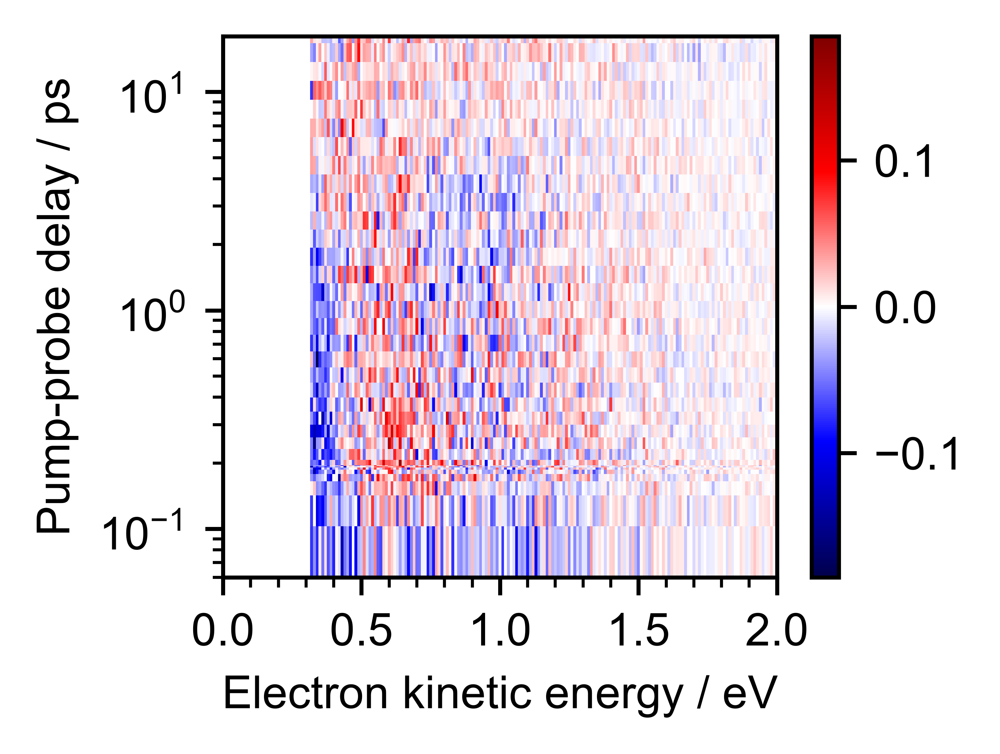

In [207]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

energies_cutoff = energies[energies>=min_eKE]

im0 = ax.pcolormesh(energies_cutoff,
                    delays,
                    flat_spectra.reshape(len(energies_cutoff),47).T-
                    global_fit(flat_energies,*params).reshape(len(energies_cutoff),47).T,
                    cmap='seismic',
                    # shading='gouraud',
                    norm = mcolors.CenteredNorm()
                   )
ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
ax.set_yscale('log')
ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
# ax.yaxis.set_major_locator(MultipleLocator(1))
# ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

#### Plot retrieved

[0.5073, 0.9997, 0.7817, 0.848, 0.7169, 0.4954, 2.7947]
[0.0006, 0.0011, 0.0022, 0.0015, 0.0022, 0.0096, 0.0133]
[7.19, 7.47]
[3.6495, 3.9323]
0.5981583548122295


C:\Users\edoar\AppData\Local\Temp\ipykernel_24212\209308978.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


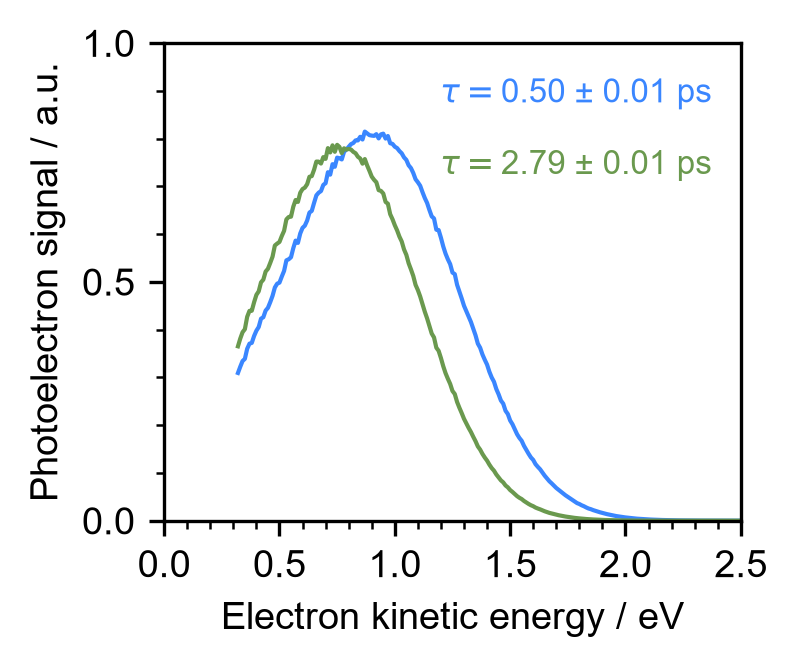

In [208]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)
tau1,tau2 = params[-2:]
tau1_err,tau2_err = perrs[-2:]

# ax.plot(energies,multiple_gaussians(energies,*params[:3]),c=blue,alpha=.5,label=f"$\\tau_1=${params[-2]:.2f}")
ax.plot(energies_cutoff,retrieval_function(energies,params[0]/params[2],params[1],params[2],0,0,1),c=blue)

# ax.plot(energies,multiple_gaussians(energies,*params[3:6]),c=green,alpha=.5,label=f"$\\tau_2=${params[-1]:.2f}")
ax.plot(energies_cutoff,retrieval_function(energies,params[0]/params[4],params[3],params[4],0,0,1),c=green)

print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perrs])
print([float(f"{1239.8/350 + 1239.8/266.67 - p:.2f}") for p in params[1:6:3]])
print([float(f"{1239.8/266.67 - p:.4f}") for p in params[1:6:3]])


ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
ax.set_ylim(0,1.)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")
plt.legend()
print(params[0]/params[3])

In [209]:
# print(f"Ratio of blue and green peak area: {((params[0]*params[2])/(params[3]*params[5])):.2f}")

In [210]:
1240/350+2*1240/267

12.831246655965757

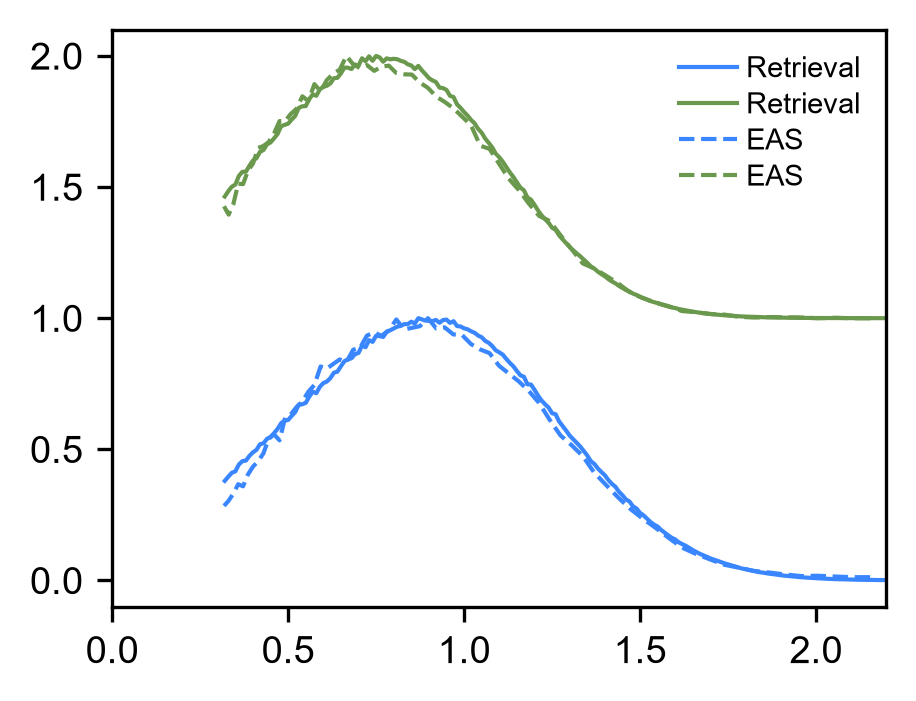

In [211]:
A1 = retrieval_function(energies,params[0]/params[2],params[1],params[2],0,0,1)
plt.plot(energies_cutoff,A1/max(A1),c=blue,label='Retrieval')
A2 = retrieval_function(energies,params[0]/params[4],params[3],params[4],0,0,1)
plt.plot(energies_cutoff,A2/max(A2)+1,c=green,label='Retrieval')
plt.xlim(0,2.2)

plt.plot(energies_DAS,A1s_EAS/max(A1s_EAS),'--',c=blue,label=f"EAS")
plt.plot(energies_DAS,A2s_EAS/max(A2s_EAS)+1,'--',c=green,label=f"EAS")
plt.legend()

#### Plot delay fit

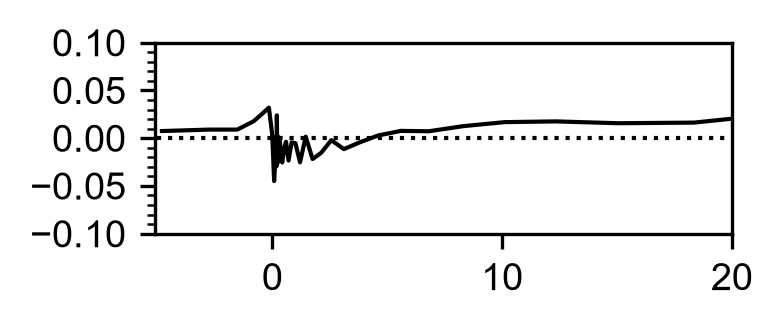

In [212]:
total_sig = np.sum(retrieval_function(energies,params[0]/params[2],params[1],params[2],0,0,1))*A_model(scanSet.delays-scanSet.t0,1,tau1,sigma) + np.sum(retrieval_function(energies,params[0]/params[4],params[3],params[4],0,0,1))*B_model(scanSet.delays-scanSet.t0,1,tau1,tau2,sigma) 

plt.plot(scanSet.delays-scanSet.t0,trace-total_sig/total_norm,'k-',ms=3,mew=.6,mec=(0,0,0,0.6),mfc=(1,1,1,0),zorder=100)

plt.gcf().set_size_inches(thesisWid/2*.9,thesisWid/5*0.75)

ax = plt.gca()
ax.hlines(0,-5,300,'k',':')
ax.set_ylim(-.1,.1)
ax.set_xlim(-5.1,20)

ax.yaxis.set_major_locator(MultipleLocator(.05))
ax.yaxis.set_minor_locator(MultipleLocator(.01))
# ax.xaxis.set_major_locator(MultipleLocator(2))
# ax.xaxis.set_minor_locator(MultipleLocator(.5))

#### Average lifetime from EAS

In [213]:
def average_decay_EAS(B1,B2,tau1,tau2):
    """B_i is the EAS amplitude
    A_i is the DAS amplitude"""
    k1, k2 = 1/tau1, 1/tau2
    A1 = B1 + (k1/(k2-k1)) * B2
    A2 = -(k1/(k2-k1)) * B2
    print(A1,A2)
    print(A1/(-A1+A2),A2/(-A1+A2))

    # Intensity Average Lifetime
    # numerator = A1*tau1**2+A2*tau2**2
    # denominator = A1*tau1+A2*tau2
    
    # # Amplitude Average Lifetime
    numerator = A1*tau1+A2*tau2
    denominator = A1+A2
    # print(A1,tau1,A2,tau2)
    
    return numerator/denominator
    

In [2204]:
B1 = params[0]
B2 = params[0]
print(B1/(B1+B2),B2/(B1+B2))

print(f"Average lifetime retr.: {average_decay_EAS(B1,B2,tau1,tau2):.3f} ps")

# #Cutoff true gaussians
# B1 = np.trapezoid(multiple_gaussians(energies,*params[:3]),energies)
# B2 = np.trapezoid(multiple_gaussians(energies,*params[3:6]),energies)
# # Distorted Gaussians
# B1 = np.trapezoid(retrieval_function(energies,*params[:3],0,0,1),energies_cutoff)
# B2 = np.trapezoid(retrieval_function(energies,*params[3:6],0,0,1),energies_cutoff)

# print(f"Average lifetime fit: {average_decay_EAS(B1,B2,tau1,tau2):.3f} ps")

# # (B1*tau1+B2*tau2)/(B1+B2)
# B1*tau1,B2*tau2

0.5 0.5
-0.1504870886261298 0.8471825346766879
-0.15083859938316796 0.8491614006168321
Average lifetime retr.: 3.290 ps


#### Plot combined fit trace+EAS plot

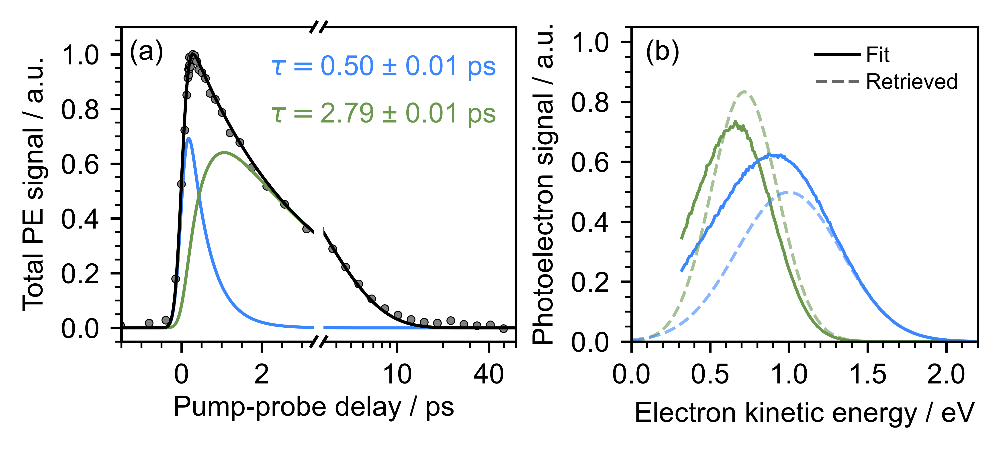

In [216]:
fig = plt.figure()
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2.25*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1,0.05,1,0.6,1.8],
                      height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
ax1b = fig.add_subplot(gs[:, 2])
ax2 = fig.add_subplot(gs[:, 4])
# ax2b = fig.add_subplot(gs[1, 4])

axes = ax1,ax1b,ax2,#ax2b

ts = np.arange(-5,100,.01)


#### Total total retrieved spectra
B1 = params[0]
B2 = params[0]
total_sig = B1*A_model(ts,1,tau1,sigma) + B2*B_model(ts,1,tau1,tau2,sigma)
total_norm = np.max(total_sig)
#Plot total and individual components
for ax in ax1, ax1b:
    break
    ax.plot(ts,
            B1*A_model(ts,1,tau1,sigma)/total_norm,
            '--',c=blue)
    ax.plot(ts,
            B2*B_model(ts,1,tau1,tau2,sigma)/total_norm,
            '--',c=green)
    ax.plot(ts,total_sig/total_norm,'k--')
    
    
    
#### Total counts and total scattered spectra
total_sig = np.sum(retrieval_function(energies,params[0]/params[2],params[1],params[2],0,0,1))*A_model(ts,1,tau1,sigma) + np.sum(retrieval_function(energies,params[0]/params[4],params[3],params[4],0,0,1))*B_model(ts,1,tau1,tau2,sigma) 
total_norm = np.max(total_sig)


#Plot total and individual components
for ax in ax1, ax1b:
    ax.plot(ts,
            np.sum(retrieval_function(energies,params[0]/params[2],params[1],params[2],0,0,1))*A_model(ts,1,tau1,sigma)/total_norm,
            c=blue)
    ax.plot(ts,
            np.sum(retrieval_function(energies,params[0]/params[4],params[3],params[4],0,0,1))*B_model(ts,1,tau1,tau2,sigma)/total_norm,
            c=green)
    ax.plot(ts,total_sig/total_norm,'k')


#This is equivalent to summing all the counts of the measured 
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)
for ax in ax1,ax1b:
    ax.plot(scanSet.delays-scanSet.t0,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)


#Formatting trace
for ax in axes[:2]:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.05,1.1)
    
ax1.set_xlim(-1.5,3.299)

ax1b.set_xscale('log')
ax1b.set_xlim(ax1.get_xlim()[1],60)
ax1b.set_xticks((10,40))
ax1b.set_xticklabels([f"{t}" for t in (10,40)])

ax1b.set_yticklabels([])
ax1b.set_yticks([])

ax1.set_ylabel("Total PE signal / a.u.")
ax1.set_xlabel("Pump-probe delay / ps",x=1,labelpad=2)


ax1.spines['right'].set_visible(False)
ax1b.spines['left'].set_visible(False)
    
ax1.yaxis.set_major_locator(MultipleLocator(.2))
ax1.yaxis.set_minor_locator(MultipleLocator(.05))
ax1b.xaxis.set_minor_formatter(NullFormatter())

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
for ax,axb in zip((ax1,),(ax1b,)):
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
    ax.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

    kwargs.update(transform=axb.transAxes)  # switch to bottom axes
    axb.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
    axb.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal
    


#Fit and retrieved EAS
#Normalisation to 1
norm = params[3]*1.2 # green gaussian max
# Fit EAS
ax2.plot(energies_cutoff,retrieval_function(energies,*params[3:6],0,0,1)/norm,c=green)
ax2.plot(energies_cutoff,retrieval_function(energies,*params[:3],0,0,1)/norm,c=blue)
# Retrieved EAS
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[3:6])/norm,c=green,alpha=.6)
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[:3])/norm,c=blue,alpha=.6)
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[3:6])/norm,'--',c=green,alpha=.6)
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[:3])/norm,'--',c=blue,alpha=.6)
ax2.plot(energies,multiple_gaussians(energies,*params[3:6])/norm,'--',c=green,alpha=.6)
ax2.plot(energies,multiple_gaussians(energies,*params[:3])/norm,'--',c=blue,alpha=.6)
#Legend
ax2.plot(-1,-1,c='k', label="Fit")
ax2.plot(-1,-1,'--',c='k', alpha=.6,label="Retrieved")

#True EAS
# ax2.plot(energies_DAS,A1s_EAS/1.5,'-',c='k',alpha=.5,)
# ax2.plot(energies_DAS,A2s_EAS/1.5,'-',c='k',alpha=.5,)

#Axes formatting
ax2.set_xlim(0,2.2)
# ax2.set_yticklabels([])
ax2.yaxis.set_major_locator(MultipleLocator(.2))
ax2.yaxis.set_minor_locator(MultipleLocator(0.05))

ax2.xaxis.set_major_locator(MultipleLocator(.5))
ax2.xaxis.set_minor_locator(MultipleLocator(0.1))
    

ax2.set_ylabel("Photoelectron signal / a.u.",)#labelpad=2)
ax2.set_xlabel("Electron kinetic energy / eV",)

ax2.set_ylim(0,1.05)

ax2.legend()

# ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1b.text(.9,.75,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,transform=ax1b.transAxes)
ax1b.text(.9,.6,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,transform=ax1b.transAxes)

for ax,indx in zip((ax1,ax2),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.04,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)

fig.align_xlabels([ax1,ax1b,ax2])
# plt.savefig('EAS_retrieved.png',dpi=fig.dpi,bbox_inches='tight')

(np.float64(-0.115176639860803), np.float64(0.6543588875129366))

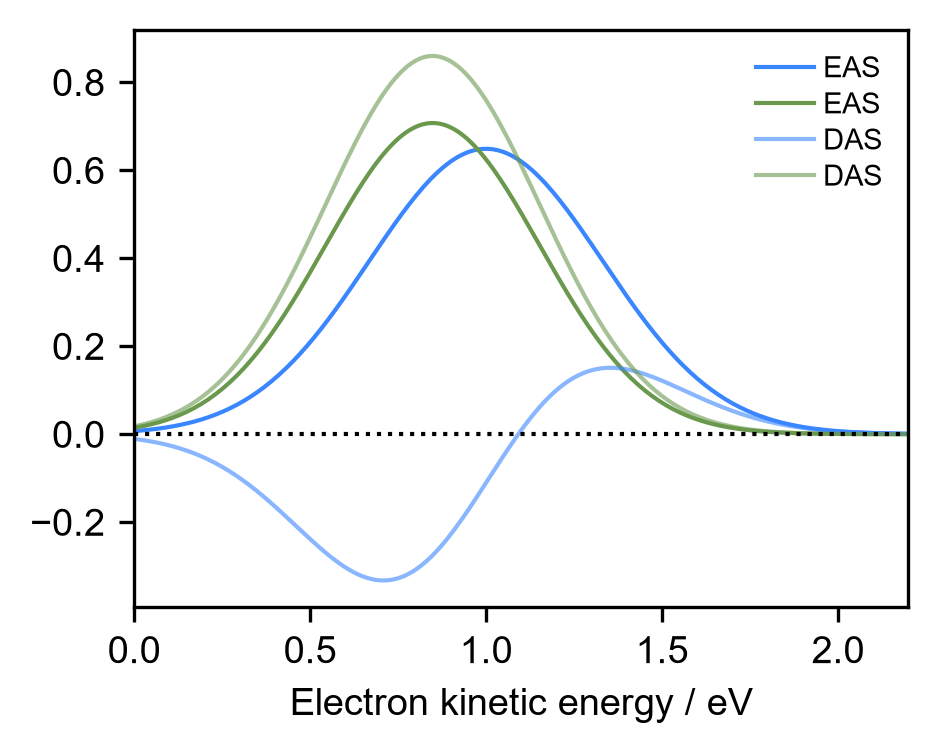

In [217]:
#Deriving DAS

# A1 = retrieval_function(energies,params[0]/params[2],params[1],params[2],0,0,1)
# A2 = retrieval_function(energies,params[0]/params[4],params[3],params[4],0,0,1)
A1 = multiple_gaussians(energies,params[0]/params[2],params[1],params[2],0,0,1)
A2 = multiple_gaussians(energies,params[0]/params[4],params[3],params[4],0,0,1)

plt.plot(energies,A1,blue,label='EAS')
plt.plot(energies,A2,green,label='EAS')

k_term = (1/tau1/(1/tau2-1/tau1))

D_A1= A1 + k_term * A2
D_A2 = -k_term * A2
plt.plot(energies,D_A1,blue,alpha=.6,label='DAS')
plt.plot(energies,D_A2,green,alpha=.6,label='DAS')

plt.hlines(0,0,5,'k',':')
plt.xlim(0,2.2)
plt.legend()
plt.xlabel("Electron kinetic energy / eV")
np.trapezoid(A1,x=energies),np.trapezoid(A2,x=energies)
np.trapezoid(D_A1,x=energies),np.trapezoid(D_A2,x=energies)


### Decaying Gaussians -- DAS like

#### The model

In [218]:
# Get min_eKE of spectra
# It should be the same for all of them so extrcting it from the first here
fittableData = np.array((scanSet.energies,scanSet.subtracted[0]))
min_eKE = min(fittableData[0])

In [219]:
#Settings
crossSectionSetInd = 0
thresholdInd = 6
surfInd = 6
num_surface = 5
num_bulk = 5
print(f"Cross-section set: {crossSectionSets[crossSectionSetInd]}")
print(f"Escape threshold: {E0s[thresholdInd]} eV")
print(f"Concentration profile G amplitude: {concAmps[surfInd]}")
print(f"Surface gaussians: {num_surface}")
print('-'*8)
surf_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,surfInd]
bulk_bas = allBasisSetsUnnorm[crossSectionSetInd,thresholdInd,0]
surf_bas /= np.amax(surf_bas)


Cross-section set: 1b
Escape threshold: 1.0 eV
Concentration profile G amplitude: 4.6
Surface gaussians: 5
--------


In [220]:
# Global fit
delays = scanSet.delays-scanSet.t0
basis = surf_bas


In [221]:
def monoexponential(x,A1,tau1):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))

def I(t,k,sigma):
    """Monoexponential helper function"""
    tau1=1/k
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))
    # return 1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2*(k1/(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    
def retrieval_function(x,a1,c1,f1,a2,c2,f2):
    # fwhm to wid
    w1,w2 = f1*0.60056,f2*.60056
    # print(a1.shape,x.shape)
    y1 =  a1 * np.exp( -((x - c1)/w1)**2)
    y2 =  a2 * np.exp( -((x - c2)/w2)**2)
    
    # y1 = np.sum(basis.T * y1, axis=1)
    y1 = (basis.T @ y1) # matrix multipication
    y2 = (basis.T @ y2) # matrix multipication
    return (y1+y2)[x>=min_eKE]

def global_fit(flat_energies,amp1,centre1,fwhm1,amp2,centre2,fwhm2, tau1, tau2):
    sig = 0.320 / 2.355  # cross-correlation with 250 & 267

    energy_len = 500
    points_per_trace = 47

    energies = flat_energies.reshape(points_per_trace,energy_len).T
    
    a1 = monoexponential(delays,amp1,tau1)
    a2 = monoexponential(delays,amp2,tau2)
    # a1 = A_model(delays,amp1,tau1,sig)
    # a2 = B_model(delays,amp2,tau1,tau2,sig)
    c1 = amp*0 + centre1
    c2 = amp*0 + centre2
    f1 = amp*0 + fwhm1
    f2 = amp*0 + fwhm2
    return retrieval_function(energies,a1,c1,f1,a2,c2,f2).ravel()

#### Flatten delays + spectra

In [222]:
#Flatten energies
energies = np.arange(0.01,5.01,0.01)
flat_energies = np.tile(energies,47)

#Define delays
delays = scanSet.delays-scanSet.t0



In [223]:
# Rebin and flatten spectra
flat_spectra = []
for spectrum in scanSet.subtracted:
    data = np.array((scanSet.energies,spectrum))
    flat_spectra.append(rebinData(data,min_eKE,nanWarningSuppress=True)[1])
flat_spectra  =np.array(flat_spectra).T.flatten()
flat_spectra.shape[0]/47

C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\edoar\AppData\Local\anaconda3\envs\TRPES\Lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


469.0

In [224]:
flat_energies.shape

(23500,)

#### Fit

In [225]:
p0 = [1,.9,1,
      1,1.2,1,
     1,3]

params,pcov = curve_fit(global_fit,flat_energies,flat_spectra,
                        p0 = p0,bounds=(0,np.inf),)
perrs = np.sqrt(np.diag(pcov))
params,perrs

(array([0.58813227, 0.80206521, 0.55636363, 0.36679283, 1.20337678,
        0.57070204, 4.25150797, 1.81235087]),
 array([0.00845342, 0.00340337, 0.00425703, 0.00803579, 0.00660053,
        0.00587769, 0.05130009, 0.02754502]))

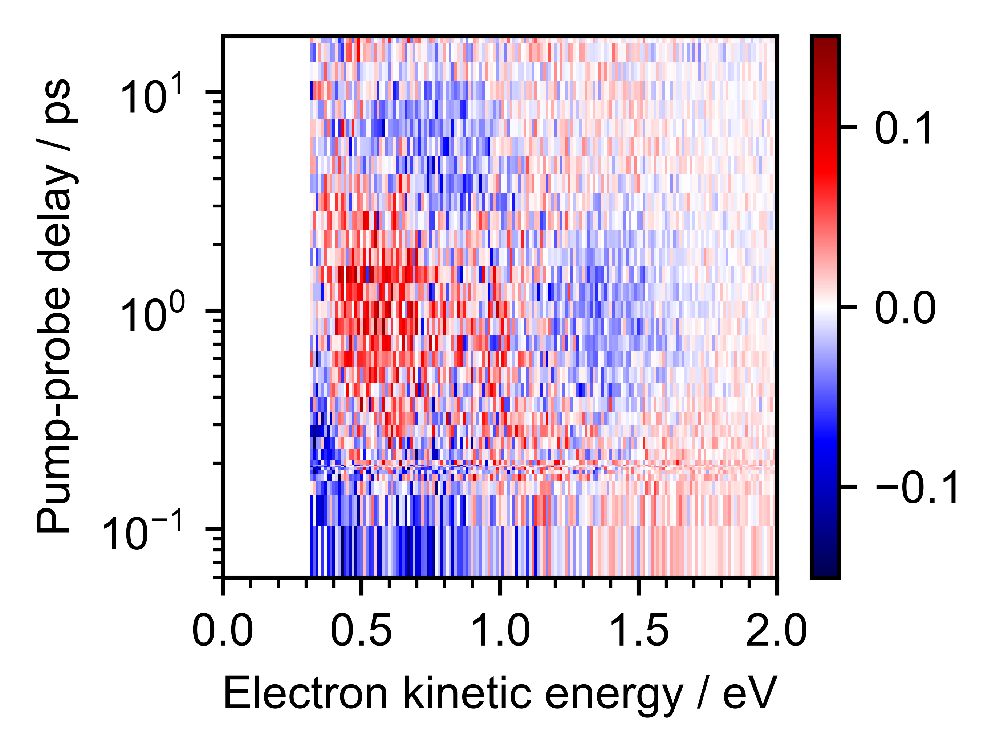

In [226]:
fig,ax = plt.subplots()
fig.set_dpi(1000)
fig.set_size_inches(20/3.2/2.54,15.5/3.2/2.5)

energies_cutoff = energies[energies>=min_eKE]

im0 = ax.pcolormesh(energies_cutoff,
                    delays,
                    flat_spectra.reshape(len(energies_cutoff),47).T-
                    global_fit(flat_energies,*params).reshape(len(energies_cutoff),47).T,
                    cmap='seismic',
                    # shading='gouraud',
                    norm = mcolors.CenteredNorm()
                   )
ax.set_xlim(0,2)
ax.set_ylim(-0.16,8.3)
ax.set_yscale('log')
ax.set_ylim(0.06,18)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")

ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(.1))
# ax.yaxis.set_major_locator(MultipleLocator(1))
# ax.yaxis.set_minor_locator(MultipleLocator(.2))
plt.colorbar(im0)

#### Plot retrieved

[0.5881, 0.8021, 0.5564, 0.3668, 1.2034, 0.5707, 4.2515, 1.8124]
[0.0085, 0.0034, 0.0043, 0.008, 0.0066, 0.0059, 0.0513, 0.0275]
[7.39, 6.99]
[3.8471, 3.4458]
1.603445368915089


C:\Users\edoar\AppData\Local\Temp\ipykernel_24212\2552154755.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


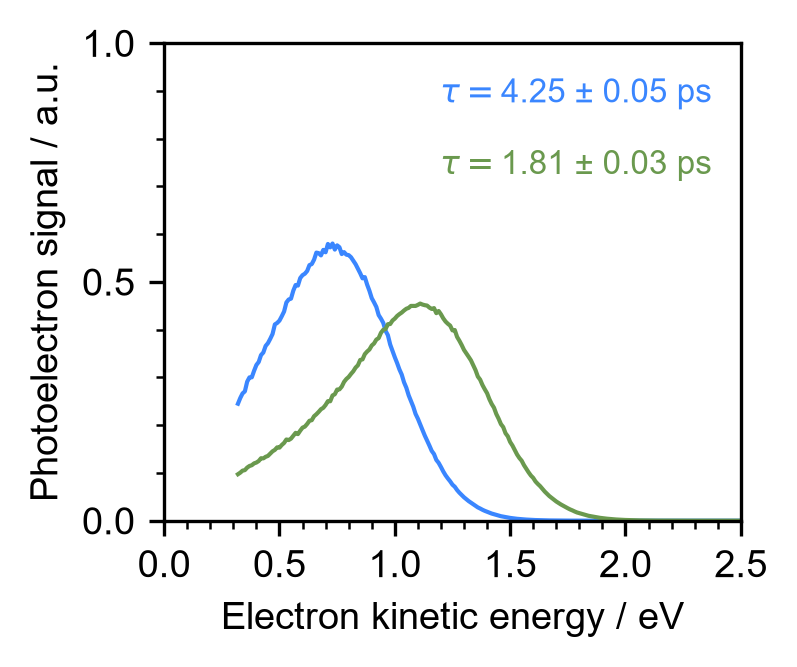

In [227]:
fig,ax = plt.subplots(1)
plt.subplots_adjust(wspace=0.05)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid/2*0.75)
tau1,tau2 = params[-2:]
tau1_err,tau2_err = perrs[-2:]

# ax.plot(energies,multiple_gaussians(energies,*params[:3]),c=blue,alpha=.5,label=f"$\\tau_1=${params[-2]:.2f}")
ax.plot(energies_cutoff,retrieval_function(energies,*params[:3],0,0,1),c=blue)

# ax.plot(energies,multiple_gaussians(energies,*params[3:6]),c=green,alpha=.5,label=f"$\\tau_2=${params[-1]:.2f}")
ax.plot(energies_cutoff,retrieval_function(energies,*params[3:6],0,0,1),c=green)

print([float(f"{p:.4f}") for p in params])
print([float(f"{p:.4f}") for p in perrs])
print([float(f"{1239.8/350 + 1239.8/266.67 - p:.2f}") for p in params[1:6:3]])
print([float(f"{1239.8/266.67 - p:.4f}") for p in params[1:6:3]])


ax.text(.95,.8,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,fontsize=8,transform=ax.transAxes)
ax.text(.95,.65,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax.transAxes)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax = plt.gca()
ax.set_xlim(0,2.5)
ax.set_ylim(0,1.)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax.set_xlabel("Electron kinetic energy / eV",)
ax.set_ylabel("Photoelectron signal / a.u.")
plt.legend()
print(params[0]/params[3])

In [228]:
print(f"Ratio of blue and green peak area: {((params[0]*params[2])/(params[3]*params[5])):.2f}")

Ratio of blue and green peak area: 1.56


In [229]:
1240/350+2*1240/267

12.831246655965757

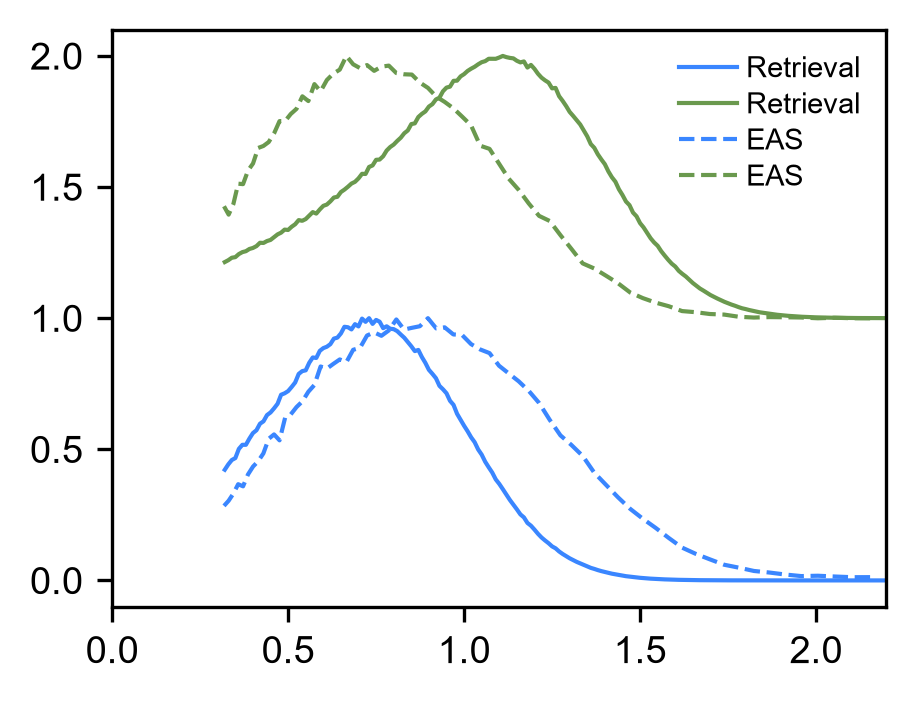

In [230]:
A1 = retrieval_function(energies,*params[:3],0,0,1)
plt.plot(energies_cutoff,A1/max(A1),c=blue,label='Retrieval')
A2 = retrieval_function(energies,*params[3:6],0,0,1)
plt.plot(energies_cutoff,A2/max(A2)+1,c=green,label='Retrieval')
plt.xlim(0,2.2)

plt.plot(energies_DAS,A1s_EAS/max(A1s_EAS),'--',c=blue,label=f"EAS")
plt.plot(energies_DAS,A2s_EAS/max(A2s_EAS)+1,'--',c=green,label=f"EAS")
plt.legend()

#### Plot delay fit

ValueError: operands could not be broadcast together with shapes (500,) (10500,) 

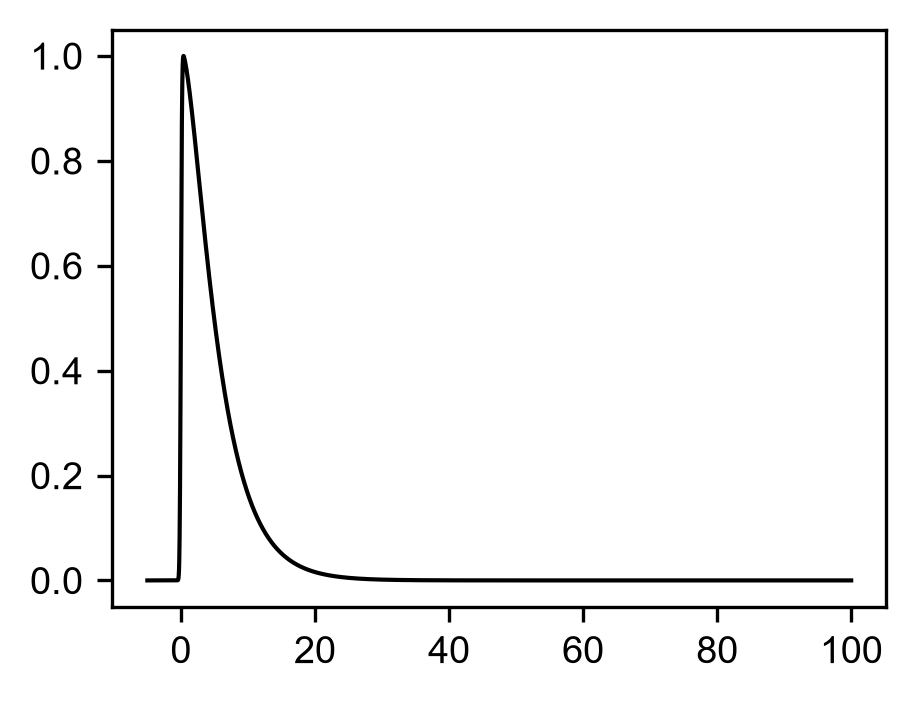

In [231]:
total_sig = np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma) + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,sigma) 
total_norm = np.max(total_sig)
plt.plot(ts,total_sig/total_norm,'k')

total_sig_retr = np.sum((multiple_gaussians(energies,*params[:3],0,0,1))*
                        A_model(ts,1,tau1,sigma) +
                        np.sum(multiple_gaussians(energies,*params[3:6],0,0,1))*
                        A_model(ts,1,tau2,sigma))
plt.plot(ts,total_sig_retr/max(total_sig_retr),'r')


plt.plot(ts,
        np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma)/total_norm,
        c=blue)
plt.plot(ts,
        np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,sigma)/total_norm,
        c=green)
# plt.plot(ts,
#         np.sum(retrieval_function(energies,*params[3:6],0,0,1))*A_model(ts,1,tau2,sigma)/total_norm,
#         c=red)
        


trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)
plt.plot(scanSet.delays-scanSet.t0,trace,'ko',ms=3,mew=.6,mec=(0,0,0,0.6),mfc=(1,1,1,0),zorder=100)
plt.xlim(-6,20)

plt.gcf().set_size_inches(thesisWid/2*.9,thesisWid/2*0.75)

ax=plt.gca()
ax.set_ylim(-.1,1.1)
ax.set_xlim(-5.1,10)

ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(.1))
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.set_ylabel("Retrieved PE signal / a.u.")
ax.set_xlabel("Pump-probe delay / ps")

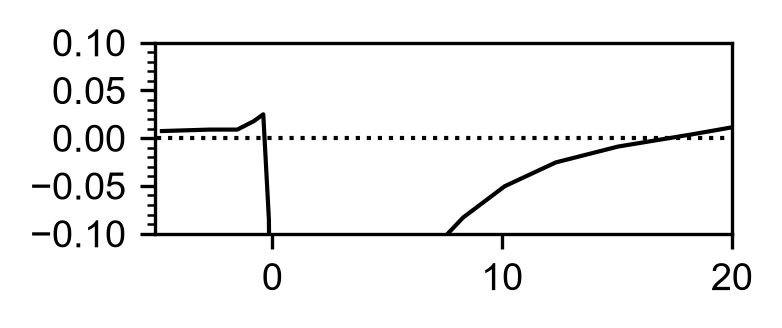

In [232]:
total_sig = np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(scanSet.delays-scanSet.t0,1,tau1,sigma) + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*A_model(scanSet.delays-scanSet.t0,1,tau2,sigma) 

plt.plot(scanSet.delays-scanSet.t0,trace-total_sig/total_norm,'k-',ms=3,mew=.6,mec=(0,0,0,0.6),mfc=(1,1,1,0),zorder=100)

plt.gcf().set_size_inches(thesisWid/2*.9,thesisWid/5*0.75)

ax = plt.gca()
ax.hlines(0,-5,300,'k',':')
ax.set_ylim(-.1,.1)
ax.set_xlim(-5.1,20)

ax.yaxis.set_major_locator(MultipleLocator(.05))
ax.yaxis.set_minor_locator(MultipleLocator(.01))
# ax.xaxis.set_major_locator(MultipleLocator(2))
# ax.xaxis.set_minor_locator(MultipleLocator(.5))

#### Plot combined fit trace+EAS plot

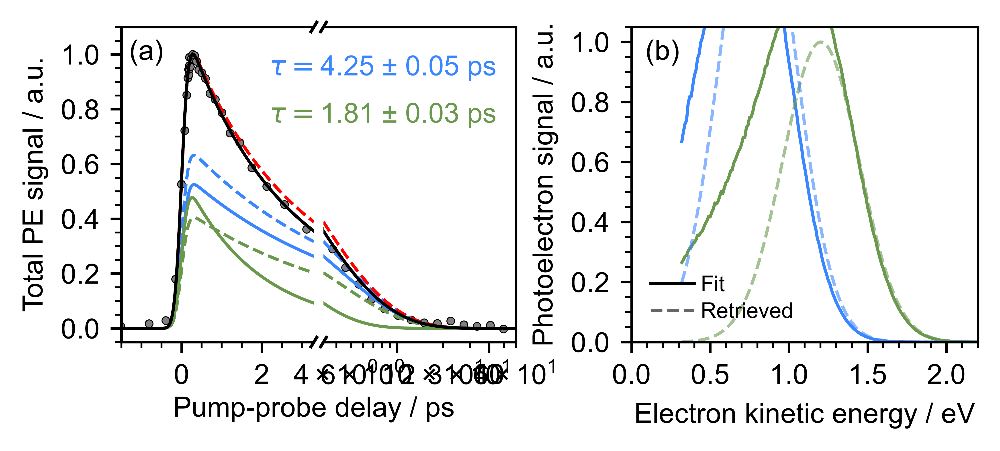

In [234]:
fig = plt.figure()
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2.25*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1,0.05,1,0.6,1.8],
                      height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
ax1b = fig.add_subplot(gs[:, 2])
ax2 = fig.add_subplot(gs[:, 4])
# ax2b = fig.add_subplot(gs[1, 4])

axes = ax1,ax1b,ax2,#ax2b

ts = np.arange(-5,100,.01)


#### Total total retrieved spectra
B1 = params[0]*params[2]
B2 = params[3]*params[5]
total_sig = B1*A_model(ts,1,tau1,sigma) + B2*A_model(ts,1,tau2,sigma)
total_norm = np.max(total_sig)
#Plot total and individual components
for ax in ax1, ax1b:
    ax.plot(ts,
            B1*A_model(ts,1,tau1,sigma)/total_norm,
            '--',c=blue)
    ax.plot(ts,
            B2*A_model(ts,1,tau1,sigma)/total_norm,
            '--',c=green)
    ax.plot(ts,total_sig/total_norm,'r--')
    
    
    
#### Total counts and total scattered spectra
total_sig = np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma) + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*A_model(ts,1,tau2,sigma) 
total_norm = np.max(total_sig)


#Plot total and individual components
for ax in ax1, ax1b:
    ax.plot(ts,
            np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma)/total_norm,
            c=blue)
    ax.plot(ts,
            np.sum(retrieval_function(energies,*params[3:6],0,0,1))*A_model(ts,1,tau2,sigma)/total_norm,
            c=green)
    ax.plot(ts,total_sig/total_norm,'k')


#This is equivalent to summing all the counts of the measured 
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)
for ax in ax1,ax1b:
    ax.plot(scanSet.delays-scanSet.t0,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)


#Formatting trace
for ax in axes[:2]:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.05,1.1)
    
ax1.set_xlim(-1.5,3.299)

ax1b.set_xscale('log')
ax1b.set_xlim(ax1.get_xlim()[1],60)
ax1b.set_xticks((10,40))
ax1b.set_xticklabels([f"{t}" for t in (10,40)])

ax1b.set_yticklabels([])
ax1b.set_yticks([])

ax1.set_ylabel("Total PE signal / a.u.")
ax1.set_xlabel("Pump-probe delay / ps",x=1,labelpad=2)


ax1.spines['right'].set_visible(False)
ax1b.spines['left'].set_visible(False)
    
ax1.yaxis.set_major_locator(MultipleLocator(.2))
ax1.yaxis.set_minor_locator(MultipleLocator(.05))

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
for ax,axb in zip((ax1,),(ax1b,)):
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
    ax.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

    kwargs.update(transform=axb.transAxes)  # switch to bottom axes
    axb.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
    axb.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal
    


#Fit and retrieved EAS
#Normalisation to 1
norm = params[3] # green gaussian max
# Fit EAS
ax2.plot(energies_cutoff,retrieval_function(energies,*params[3:6],0,0,1)/norm,c=green)
ax2.plot(energies_cutoff,retrieval_function(energies,*params[:3],0,0,1)/norm,c=blue)
# Retrieved EAS
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[3:6])/norm,c=green,alpha=.6)
# ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[:3])/norm,c=blue,alpha=.6)
ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[3:6])/norm,'--',c=green,alpha=.6)
ax2.plot(energies_cutoff,multiple_gaussians(energies_cutoff,*params[:3])/norm,'--',c=blue,alpha=.6)
#Legend
ax2.plot(-1,-1,c='k', label="Fit")
ax2.plot(-1,-1,'--',c='k', alpha=.6,label="Retrieved")


#Axes formatting
ax2.set_xlim(0,2.2)
# ax2.set_yticklabels([])
ax2.yaxis.set_major_locator(MultipleLocator(.2))
ax2.yaxis.set_minor_locator(MultipleLocator(0.05))

ax2.xaxis.set_major_locator(MultipleLocator(.5))
ax2.xaxis.set_minor_locator(MultipleLocator(0.1))
    

ax2.set_ylabel("Photoelectron signal / a.u.",)#labelpad=2)
ax2.set_xlabel("Electron kinetic energy / eV",)

ax2.set_ylim(0,1.05)

ax2.legend()

# ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1b.text(.9,.75,f"$\\tau =${tau1:.2f} ± {tau1_err:.2f} ps\n",ha='right',c=blue,transform=ax1b.transAxes)
ax1b.text(.9,.6,f"$\\tau =${tau2:.2f} ± {tau2_err:.2f} ps\n",ha='right',c=green,transform=ax1b.transAxes)

for ax,indx in zip((ax1,ax2),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.04,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)

fig.align_xlabels([ax1,ax1b,ax2])
# plt.savefig('EAS_retrieved.png',dpi=fig.dpi,bbox_inches='tight')

### Combine plots for thesis

#### EAS + DAS

In [292]:
Es = energies_DAS,energies_EAS
amps1 = A1s_DAS,A1s_EAS
amps2 = A2s_DAS,A2s_EAS
A1s_errors = A1s_err_DAS,A1s_err_EAS
A2s_errors = A2s_err_DAS,A2s_err_EAS


wrong integration


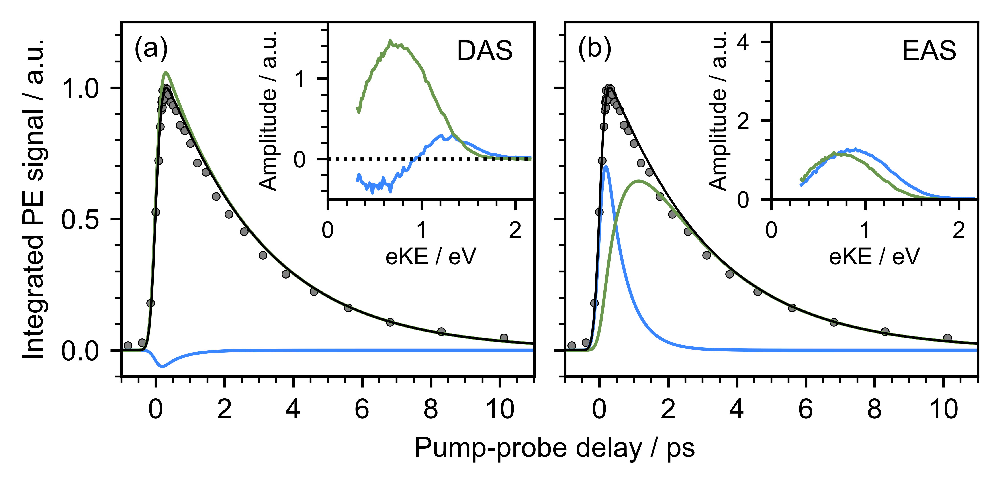

In [293]:
fig,(ax0,ax1) = plt.subplots(1,2)
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2*0.75)
plt.subplots_adjust(wspace=0.075)
ax0_ins = ax0.inset_axes((.5,.5,1-0.5,1-0.5))
ax1_ins = ax1.inset_axes((.5,.5,1-0.5,1-0.5))

ts = np.arange(-5,50,0.01)
#Total counts
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)



for ax in ax0,ax1:
    # ax.plot(scanSet.delays-scanSet.t0,trace,'ko',ms=3,mew=.6,mec=(0,0,0,1),mfc=(1,1,1,0),zorder=100)
    ax.plot(scanSet.delays-scanSet.t0,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)

#DAS
sum_DAS = np.sum(A1s_DAS)*A_model(ts,1,tau1,sigma)+np.sum(A2s_DAS)*A_model(ts,1,tau2,sigma)
total_DAS = max(sum_DAS)
ax0.plot(ts,np.sum(A1s_DAS)*A_model(ts,1,tau1,sigma)/total_DAS,c=blue)
ax0.plot(ts,np.sum(A2s_DAS)*A_model(ts,1,tau2,sigma)/total_DAS,c=green)
ax0.plot(ts,sum_DAS/total_DAS,'k',lw=0.75)

#EAS
sum_EAS = np.sum(A1s_EAS)*A_model(ts,1,tau1,sigma)+np.sum(A2s_EAS)*B_model(ts,1,tau1,tau2,sigma)
total_EAS = max(sum_EAS)

ax1.plot(ts,np.sum(A1s_EAS)*A_model(ts,1,tau1,sigma)/total_EAS,c=blue)
ax1.plot(ts,np.sum(A2s_EAS)*B_model(ts,1,tau1,tau2,sigma)/total_EAS,c=green)
ax1.plot(ts,sum_EAS/total_EAS,'k',lw=0.75)

axes_ins = ax0_ins,ax1_ins
for ax,energies, A1s, A2s,A1s_err,A2s_err in zip(axes_ins,Es,amps1,amps2,A1s_errors,A2s_errors):
    ax.plot(energies,A1s,'-',c=blue,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
    ax.plot(energies,A2s,'-',c=green,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax0_ins.hlines(0,0,3,'k',linestyles=':')
    
ax0_ins.set_ylim(-.5,1.7)
ax1_ins.set_ylim(0,4.5)
ax0_ins.yaxis.set_major_locator(MultipleLocator(1))
ax0_ins.yaxis.set_minor_locator(MultipleLocator(0.2))
ax1_ins.yaxis.set_major_locator(MultipleLocator(2))
ax1_ins.yaxis.set_minor_locator(MultipleLocator(0.5))
ax0_ins.text(.9,.9,"DAS",ha='right',va='top',transform = ax0_ins.transAxes)
ax1_ins.text(.9,.9,"EAS",ha='right',va='top',transform = ax1_ins.transAxes)

for ax in ax0_ins,ax1_ins:
    ax.set_xlim(0,2.2)
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_minor_locator(MultipleLocator(0.2))
    ax.set_ylabel("Amplitude / a.u.",fontsize=7.5)
    ax.set_xlabel("eKE / eV",fontsize=7.5,labelpad=1.5)
    ax.tick_params(axis='both', which='major', labelsize=7.5)
ax1_ins.set_ylabel("Amplitude / a.u.",fontsize=7.5,labelpad=2)
ax1_ins.set_xlabel("eKE / eV",fontsize=7.5,labelpad=1.5)

for ax in (ax0,ax1):
    ax.set_ylim(-.1,1.25)
    ax.set_xlim(-1,11)


    ax.yaxis.set_major_locator(MultipleLocator(.5))
    ax.yaxis.set_minor_locator(MultipleLocator(.1))
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
ax0.set_ylabel("Integrated PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1.05)
ax1.tick_params(axis='y', which='major', labelleft=False)

for ax,indx in zip((ax0,ax1),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.03,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)
print('wrong integration')

#### EAS + DAS spectra only

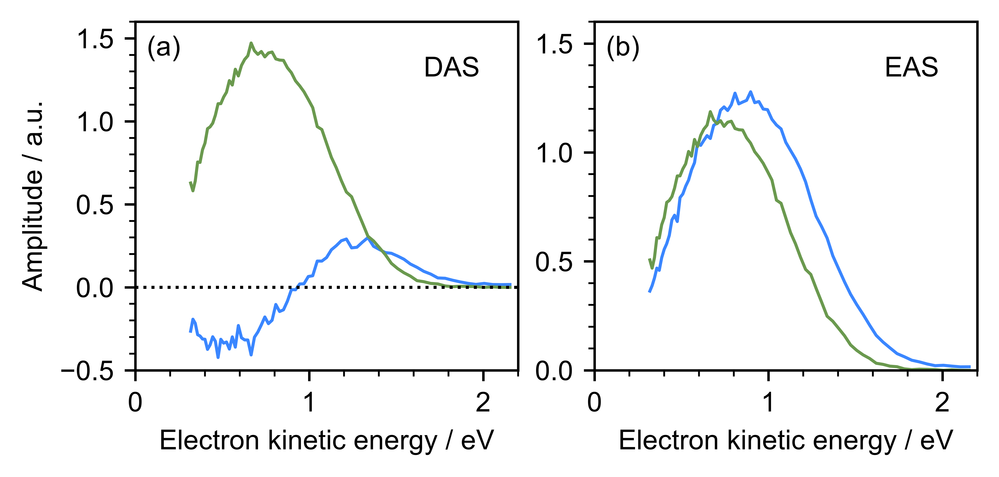

In [253]:
fig,(ax0,ax1) = plt.subplots(1,2)
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2*0.75)
plt.subplots_adjust(wspace=0.2)
axes=ax0,ax1


for ax,energies, A1s, A2s,A1s_err,A2s_err in zip(axes,Es,amps1,amps2,A1s_errors,A2s_errors):
    ax.plot(energies,A1s,'-',c=blue,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
    ax.plot(energies,A2s,'-',c=green,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax0.hlines(0,0,3,'k',linestyles=':')
    
ax0.set_ylim(-.5,1.6)
ax1.set_ylim(0,1.6)
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(0.1))
ax1.yaxis.set_major_locator(MultipleLocator(.5))
ax1.yaxis.set_minor_locator(MultipleLocator(0.1))
ax0.text(.9,.9,"DAS",ha='right',va='top',transform = ax0.transAxes)
ax1.text(.9,.9,"EAS",ha='right',va='top',transform = ax1.transAxes)

for ax in ax0,ax1:
    ax.set_xlim(0,2.2)
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_minor_locator(MultipleLocator(0.2))
    ax.set_xlabel("Electron kinetic energy / eV",)
ax0.set_ylabel("Amplitude / a.u.",)


for ax,indx in zip((ax0,ax1),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.03,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)


#### EAS + DAS + total counts w/ residuals

t0, A1, tau1
[-0.196, 0.557, 2.831]
[0.003, 0.003, 0.046]
!!!!!wrong integration!!!!!


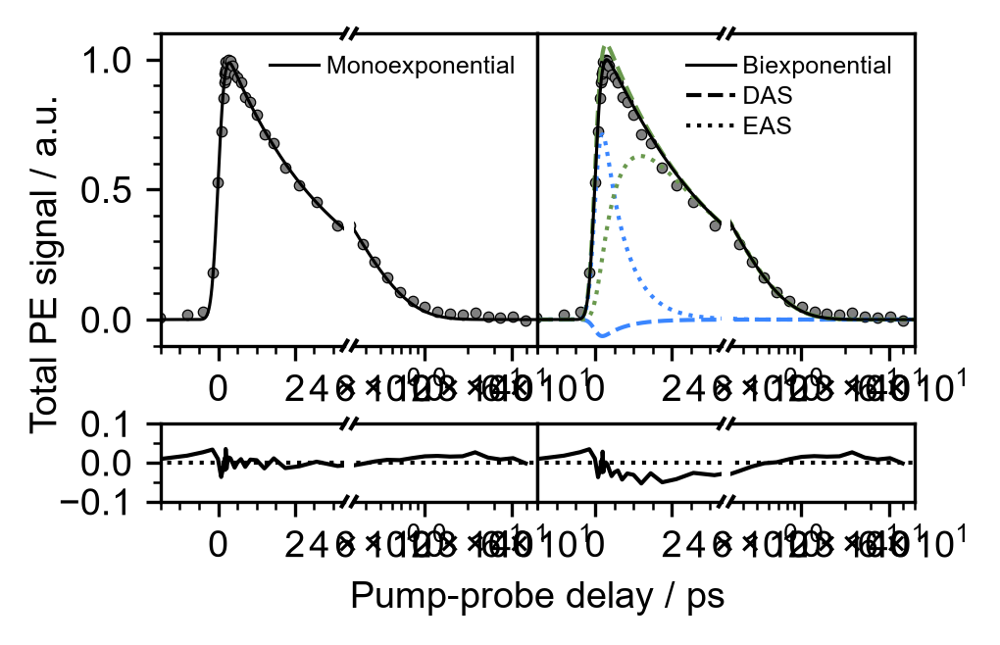

In [254]:

fig = plt.figure()
fig.set_size_inches(thesisWid/3*2*.9,thesisWid/2*0.75)

gs = gridspec.GridSpec(2,6, figure=fig,
                       width_ratios=[1,0.05,1]*2,
                      height_ratios = (1,.25))
plt.subplots_adjust(wspace=0.0,hspace=.4)

ax0 = fig.add_subplot(gs[0, 0])
ax0b = fig.add_subplot(gs[0, 2])
ax1 = fig.add_subplot(gs[0, 3])
ax1b = fig.add_subplot(gs[0, 5])
# ax2 = fig.add_subplot(gs[0, 6])
# ax2b = fig.add_subplot(gs[0, 8])

ax0r = fig.add_subplot(gs[1, 0])
ax0rb = fig.add_subplot(gs[1, 2])
ax1r = fig.add_subplot(gs[1, 3])
ax1rb = fig.add_subplot(gs[1, 5])
# ax2r = fig.add_subplot(gs[1, 6])
# ax2rb = fig.add_subplot(gs[1, 8])

axes = np.array(((ax0,ax0b,ax1,ax1b),(ax0r,ax0rb,ax1r,ax1rb)))

ts = np.arange(-5,100,.01)
#### Total counts
delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)


params,pcov=curve_fit(monoexponential_witht0,delays,trace,
                  p0=[.5,300,3])
perr = np.sqrt(np.diag(pcov))

t0 = params[0]
# Save t0 to scanSet
for ax in ax0,ax0b:
    ax.plot(delays-t0,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)
    ax.plot(ts-t0,monoexponential_witht0(ts,*params),c='k',lw=.75,zorder=0,label='Monoexponential')
for ax in ax0r,ax0rb:
    ax.plot(delays-t0,trace-monoexponential_witht0(delays,*params),c='k',zorder=0)
       
print("t0, A1, tau1")
print([float(f"{p:.3f}") for p in params])
print([float(f"{p:.3f}") for p in perr])
# ax1.text(.9,.45,f"$\\tau =${params[2]:.1f} ± {0.1} ps\n",c=blue,ha='right',transform=ax.transAxes)
##


#Formatting
for ax in axes.flatten():
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
for ax in axes[0,:].flatten():
    ax.set_ylim(-.1,1.1)
for ax in axes[1,:].flatten():
    ax.hlines(0,-5,100,'k',':')
    ax.set_ylim(-0.1,0.1)
    
for ax in axes[:,0::2].flatten():
    ax.set_xlim(-1.5,3.299)

for ax in axes[:,1::2].flatten():
    ax.set_xscale('log')
    ax.set_xlim(ax0.get_xlim()[1],60)
    ax.set_xticks((10,40))
    ax.set_xticklabels([f"{t}" for t in (10,40)])

for ax in axes[:,1:].flatten():
    ax.set_yticklabels([])
    ax.set_yticks([])
# ax0.set_ylabel("Total PE signal / a.u.")
fig.supylabel("Total PE signal / a.u.",x=-.01)
ax1r.set_xlabel("Pump-probe delay / ps",x=0)

   
for ax,axb in zip((axes[:,0::2].flatten()),(axes[:,1::2].flatten())):

    ax.spines['right'].set_visible(False)
    axb.spines['left'].set_visible(False)
    
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(.1))
ax0r.yaxis.set_major_locator(MultipleLocator(.1))
ax0r.yaxis.set_minor_locator(MultipleLocator(.05))

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
for ax,axb in zip((axes[0,0::2].flatten()),(axes[0,1::2].flatten())):
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
    ax.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

    kwargs.update(transform=axb.transAxes)  # switch to bottom axes
    axb.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
    axb.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal

m=m/.25

for ax,axb in zip((axes[1,0::2].flatten()),(axes[1,1::2].flatten())):
    
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
    ax.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

    kwargs.update(transform=axb.transAxes)  # switch to bottom axes
    axb.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
    axb.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal




#DAS
delays = scanSet.delays-scanSet.t0
sum_DAS = np.sum(A1s_DAS)*A_model(ts,1,tau1,sigma)+np.sum(A2s_DAS)*A_model(ts,1,tau2,sigma)
total_DAS = max(sum_DAS)
for ax in ax1,ax1b:
    ax.plot(delays,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)

    ax.plot(ts,np.sum(A1s_DAS)*A_model(ts,1,tau1,sigma)/total_DAS,'--',c=blue)
    ax.plot(ts,np.sum(A2s_DAS)*A_model(ts,1,tau2,sigma)/total_DAS,'--',c=green)
    ax.plot(ts,sum_DAS/total_DAS,'k',lw=.75,zorder=10,label='Biexponential')
    ax.plot(-10,-10,'k--',label="DAS")
#residuals
sum_DAS = np.sum(A1s_DAS)*A_model(delays,1,tau1,sigma)+np.sum(A2s_DAS)*A_model(delays,1,tau2,sigma)
total_DAS = max(sum_DAS)
for ax in ax1r,ax1rb:
    ax.plot(delays,trace-sum_DAS/total_DAS,'k')

#EAS
delays = scanSet.delays-scanSet.t0
sum_EAS = np.sum(A1s_EAS)*A_model(ts,1,tau1,sigma)+np.sum(A2s_EAS)*B_model(ts,1,tau1,tau2,sigma)
total_EAS = max(sum_EAS)
for ax in ax1,ax1b:
    ax.plot(ts,np.sum(A1s_EAS)*A_model(ts,1,tau1,sigma)/total_EAS,':',c=blue)
    ax.plot(ts,np.sum(A2s_EAS)*B_model(ts,1,tau1,tau2,sigma)/total_EAS,':',c=green)
    ax.plot(-10,-10,'k:',label="EAS")

ax0b.legend(bbox_to_anchor=(1, 1),loc='upper right',fontsize=6)
ax1b.legend(bbox_to_anchor=(1, 1),loc='upper right',fontsize=6)

print('!!!!!wrong integration!!!!!')

!!!!!wrong integration!!!!!


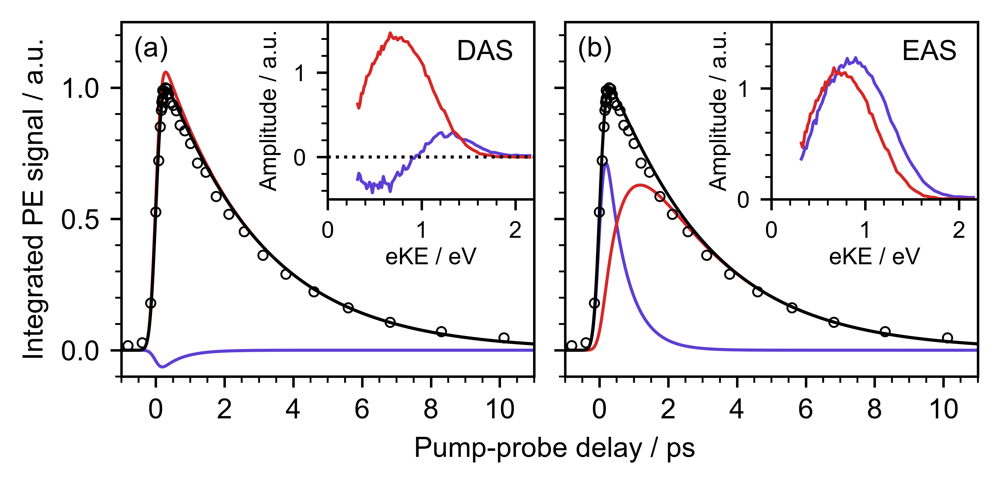

In [255]:
fig,(ax0,ax1) = plt.subplots(1,2)
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2*0.75)
plt.subplots_adjust(wspace=0.075)
ax0_ins = ax0.inset_axes((.5,.5,1-0.5,1-0.5))
ax1_ins = ax1.inset_axes((.5,.5,1-0.5,1-0.5))

ts = np.arange(-5,50,0.01)
#Total counts
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)



for ax in ax0,ax1:
    ax.plot(scanSet.delays-scanSet.t0,trace,'ko',ms=3,mew=.6,mec=(0,0,0,1),mfc=(1,1,1,0),zorder=100)

#DAS
sum_DAS = np.sum(A1s_DAS)*A_model(ts,1,tau1,sigma)+np.sum(A2s_DAS)*A_model(ts,1,tau2,sigma)
total_DAS = max(sum_DAS)
ax0.plot(ts,np.sum(A1s_DAS)*A_model(ts,1,tau1,sigma)/total_DAS,c=violet)
ax0.plot(ts,np.sum(A2s_DAS)*A_model(ts,1,tau2,sigma)/total_DAS,c=red)
ax0.plot(ts,sum_DAS/total_DAS,'k')

#EAS
sum_EAS = np.sum(A1s_EAS)*A_model(ts,1,tau1,sigma)+np.sum(A2s_EAS)*B_model(ts,1,tau1,tau2,sigma)
total_EAS = max(sum_EAS)

ax1.plot(ts,np.sum(A1s_EAS)*A_model(ts,1,tau1,sigma)/total_EAS,c=violet)
ax1.plot(ts,np.sum(A2s_EAS)*B_model(ts,1,tau1,tau2,sigma)/total_EAS,c=red)
ax1.plot(ts,sum_EAS/total_EAS,'k')

axes_ins = ax0_ins,ax1_ins
for ax,energies, A1s, A2s,A1s_err,A2s_err in zip(axes_ins,Es,amps1,amps2,A1s_errors,A2s_errors):
    ax.plot(energies,A1s,'-',c=violet,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
    ax.plot(energies,A2s,'-',c=red,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

ax0_ins.hlines(0,0,3,'k',linestyles=':')
    
ax0_ins.set_ylim(-.5,1.6)
ax1_ins.set_ylim(0,1.6)
ax0_ins.yaxis.set_major_locator(MultipleLocator(1))
ax0_ins.yaxis.set_minor_locator(MultipleLocator(0.2))
ax1_ins.yaxis.set_major_locator(MultipleLocator(1))
ax1_ins.yaxis.set_minor_locator(MultipleLocator(0.2))
ax0_ins.text(.9,.9,"DAS",ha='right',va='top',transform = ax0_ins.transAxes)
ax1_ins.text(.9,.9,"EAS",ha='right',va='top',transform = ax1_ins.transAxes)

for ax in ax0_ins,ax1_ins:
    ax.set_xlim(0,2.2)
    ax.xaxis.set_major_locator(MultipleLocator(1))
    ax.xaxis.set_minor_locator(MultipleLocator(0.2))
    ax.set_ylabel("Amplitude / a.u.",fontsize=7.5)
    ax.set_xlabel("eKE / eV",fontsize=7.5,labelpad=1.5)
    ax.tick_params(axis='both', which='major', labelsize=7.5)
ax1_ins.set_ylabel("Amplitude / a.u.",fontsize=7.5,labelpad=2)
ax1_ins.set_xlabel("eKE / eV",fontsize=7.5,labelpad=1.5)

for ax in (ax0,ax1):
    ax.set_ylim(-.1,1.25)
    ax.set_xlim(-1,11)


    ax.yaxis.set_major_locator(MultipleLocator(.5))
    ax.yaxis.set_minor_locator(MultipleLocator(.1))
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
ax0.set_ylabel("Integrated PE signal / a.u.")
ax0.set_xlabel("Pump-probe delay / ps",x=1.05)
ax1.tick_params(axis='y', which='major', labelleft=False)

for ax,indx in zip((ax0,ax1),('abcdefghijklmnopqrstuvwxyz')):
    ax.text(.03,.96,f"({indx})", va = "top",ha = "left",transform = ax.transAxes)
print('!!!!!wrong integration!!!!!')

#### EAS+DAS trace and spectra separate

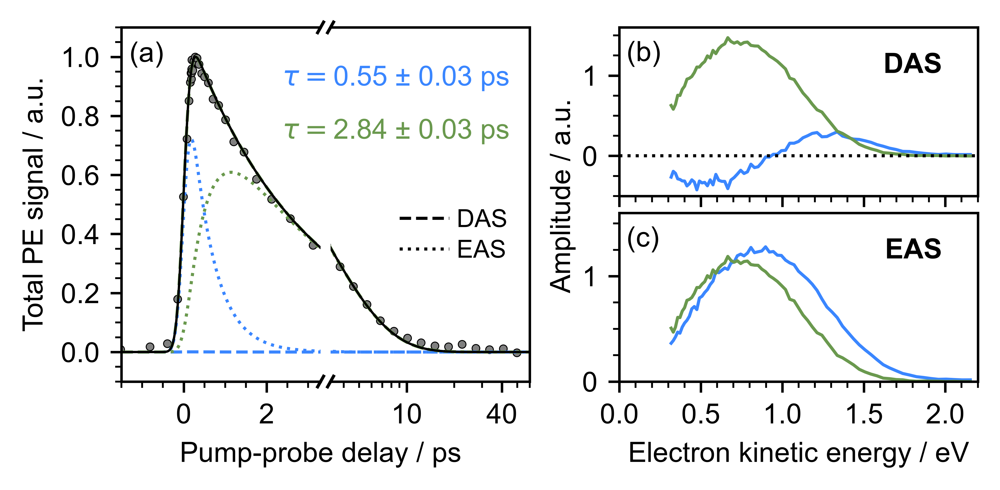

In [294]:
fig = plt.figure()
fig.set_dpi(1000)
fig.set_size_inches(thesisWid*.9,thesisWid/2*0.75)

gs = gridspec.GridSpec(2,5, figure=fig,
                       width_ratios=[1,0.05,1,0.45,1.8],
                      height_ratios = (1,1))
plt.subplots_adjust(wspace=0.0,hspace=.1)


ax1 = fig.add_subplot(gs[:, 0])
ax1b = fig.add_subplot(gs[:, 2])
ax2a = fig.add_subplot(gs[0, 4])
ax2b = fig.add_subplot(gs[1, 4])

axes = ax1,ax1b,ax2a,ax2b

ts = np.arange(-5,100,.01)
#### Total counts
delays = scanSet.delays
#Must integrate
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
trace /= max(trace)





#Formatting trace
for ax in axes[:2]:
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.xaxis.set_minor_locator(MultipleLocator(.5))
    ax.set_ylim(-.1,1.1)
    
ax1.set_xlim(-1.5,3.299)

ax1b.set_xscale('log')
ax1b.set_xlim(ax1.get_xlim()[1],60)
ax1b.set_xticks((10,40))
ax1b.set_xticklabels([f"{t}" for t in (10,40)])
ax1b.xaxis.set_minor_formatter(NullFormatter())

ax1b.set_yticklabels([])
ax1b.set_yticks([])

ax1.set_ylabel("Total PE signal / a.u.")
ax1.set_xlabel("Pump-probe delay / ps",x=1)


ax1.spines['right'].set_visible(False)
ax1b.spines['left'].set_visible(False)
    
ax1.yaxis.set_major_locator(MultipleLocator(.2))
ax1.yaxis.set_minor_locator(MultipleLocator(.05))

# Add break markers
d = .015  # Size of diagonal lines
m=1 # Slope of diagonal lines
for ax,axb in zip((ax1,),(ax1b,)):
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((1-d, 1+d), (-m*d, +m*d), **kwargs)        # top-left diagonal
    ax.plot((1- d, 1+ d), (1-m*d, 1+m*d), **kwargs)  # top-right diagonal

    kwargs.update(transform=axb.transAxes)  # switch to bottom axes
    axb.plot((-d, +d), (1 - m*d, 1 + m*d), **kwargs)  # bottom-left diagonal
    axb.plot((- d, + d), ( - m*d,  + m*d), **kwargs)  # bottom-right diagonal



#DAS
delays = scanSet.delays-scanSet.t0
flat_ts = np.tile(ts,70)
#Integrated total fit
sum_DAS = global_fit_DAS(flat_ts,*params_DAS,time_points=len(ts)).reshape(70,len(ts))
sum_DAS = -np.trapezoid(sum_DAS,axis=0,x=scanSet.energies_rebinned[mask])
total_DAS = max(sum_DAS)
#Integrate monoexponentials
params_DAS1 = np.copy(params_DAS)
params_DAS1[3::2] = 0
sum_DAS1 = global_fit_DAS(flat_ts,*params_DAS1,time_points=len(ts)).reshape(70,len(ts))
sum_DAS1 = -np.trapezoid(sum_DAS1,axis=0,x=scanSet.energies_rebinned[mask])

#Integrate monoexponentials
params_DAS2 = np.copy(params_DAS)
params_DAS2[2::2] = 0
sum_DAS2 = global_fit_DAS(flat_ts,*params_DAS2,time_points=len(ts)).reshape(70,len(ts))
sum_DAS2 = -np.trapezoid(sum_DAS2,axis=0,x=scanSet.energies_rebinned[mask])

for ax in ax1,ax1b:
    ax.plot(delays,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)

    ax.plot(ts,sum_DAS1/total_DAS,'--',c=blue)
    ax.plot(ts,sum_DAS2/total_DAS,'--',c=green)
    ax.plot(ts,sum_DAS/total_DAS,'k',lw=.75,zorder=10)
    ax.plot(-10,-10,'k--',label="DAS")

#EAS
delays = scanSet.delays-scanSet.t0
flat_ts = np.tile(ts,70)
#Integrated total fit
sum_EAS = global_fit_EAS(flat_ts,*params_EAS,time_points=len(ts)).reshape(70,len(ts))
sum_EAS = -np.trapezoid(sum_EAS,axis=0,x=scanSet.energies_rebinned[mask])
total_EAS = max(sum_DAS)

#Integrate monoexponentials
params_EAS1 = np.copy(params_EAS)
params_EAS1[3::2] = 0
sum_EAS1 = global_fit_EAS(flat_ts,*params_EAS1,time_points=len(ts)).reshape(70,len(ts))
sum_EAS1 = -np.trapezoid(sum_EAS1,axis=0,x=scanSet.energies_rebinned[mask])
#Integrate monoexponentials
params_EAS2 = np.copy(params_EAS)
params_EAS2[2::2] = 0
sum_EAS2 = global_fit_EAS(flat_ts,*params_EAS2,time_points=len(ts)).reshape(70,len(ts))
sum_EAS2 = -np.trapezoid(sum_EAS2,axis=0,x=scanSet.energies_rebinned[mask])


for ax in ax1,ax1b:
    # ax.plot(ts,sum_EAS/total_EAS,'b',lw=.75,zorder=10)

    ax.plot(ts,sum_EAS1/total_EAS,':',c=blue)
    ax.plot(ts,sum_EAS2/total_EAS,':',c=green)
    ax.plot(-10,-10,'k:',label="EAS")
    
    
    
for ax,energies, A1s, A2s,A1s_err,A2s_err,fmt in zip((ax2a,ax2b),Es,amps1,amps2,A1s_errors,A2s_errors,('--',':')):
    ax.plot(energies,A1s,'-',c=blue,label=f"$\\tau = ${tau1:.2f}$\\pm${tau1_err:.2f} ps")
    ax.plot(energies,A2s,'-',c=green,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

for ax2 in ax2a,ax2b:
    ax2.set_xlim(0,2.2)
    # ax2.set_yticklabels([])
    ax2.yaxis.set_major_locator(MultipleLocator(1))
    ax2.yaxis.set_minor_locator(MultipleLocator(0.25))

    ax2.xaxis.set_major_locator(MultipleLocator(.5))
    ax2.xaxis.set_minor_locator(MultipleLocator(0.1))
ax2a.hlines(0,0,5,'k',':')
    
ax2a.set_ylabel("Amplitude / a.u.",y=0,labelpad=2)
ax2a.set_xticklabels([])
ax2b.set_xlabel("Electron kinetic energy / eV",)

ax2a.set_ylim(-.5,1.6)
ax2b.set_ylim(0,1.6)


ax2a.text(.9,.85,"DAS",ha='right',weight='bold',va='top',transform = ax2a.transAxes)
ax2b.text(.9,.85,"EAS",ha='right',weight='bold',va='top',transform = ax2b.transAxes)

ax1b.legend(bbox_to_anchor=(0.5, 0., 0.5, 0.55),loc='upper right',fontsize=8)
ax1b.text(.9,.75,f"$\\tau =${taus_DAS[0]:.2f} ± {tau_errs_DAS[0]:.2f} ps\n",ha='right',c=blue,transform=ax1b.transAxes)
ax1b.text(.9,.6,f"$\\tau =${taus_DAS[1]:.2f} ± {tau_errs_DAS[1]:.2f} ps\n",ha='right',c=green,transform=ax1b.transAxes)

# for ax,indx in zip((ax1,ax2a),('abcdefghijklmnopqrstuvwxyz')):
ax1.text(.04,.96,f"({'a'})", va = "top",ha = "left",transform = ax1.transAxes)
ax2a.text(.02,.92,f"({'b'})", va = "top",ha = "left",transform = ax2a.transAxes)
ax2b.text(.02,.92,f"({'c'})", va = "top",ha = "left",transform = ax2b.transAxes)

fig.align_xlabels([ax1,ax1b,ax2b])

# plt.savefig('DAS_EAS.png',dpi=fig.dpi,bbox_inches='tight')

In [229]:
# save DAS and EAS
if False:
    
    savePath = cpath+r"/[CHANGE]\PhD\Thesis\Data\Chapter 5\Figure 5.8/"

    #DAS
    saveDAS = np.asarray((energies_DAS,A1s_DAS,A1s_err_DAS,A2s_DAS,A2s_err_DAS))
    header = 'eKE / eV, DAS (blue),yerr, DAS (green),yerr'
    np.savetxt(savePath+"DAS.csv",saveDAS.T,
               header=header,
               delimiter=','
              )
    #EAS
    saveEAS = np.asarray((energies_EAS,A1s_EAS,A1s_err_EAS,A2s_EAS,A2s_err_EAS))
    header = 'eKE / eV, EAS (blue),yerr, EAS (green),yerr'
    np.savetxt(savePath+"EAS.csv",saveEAS.T,
               header=header,
               delimiter=','
              )
    
    #Traces
    #EAS
    saveData = np.asarray((ts,sum_EAS1/total_EAS,sum_EAS2/total_EAS))
    np.savetxt(savePath+"EAS_traces.csv",saveData.T,
           header='Delay / ps, trace (0.55 ps), trace (2.84 ps)',
           delimiter=','
          )
    #DAS
    saveData = np.asarray((ts,sum_DAS1/total_DAS,sum_DAS2/total_DAS))
    np.savetxt(savePath+"DAS_traces.csv",saveData.T,
           header='Delay / ps, trace (0.55 ps), trace (2.84 ps)',
           delimiter=','
          )


[[-7.28294336e-04 -2.97346391e-04  2.47792463e-03 -5.21663400e-04
   3.78486959e-03  5.11462342e-03  6.08915956e-03  3.53833917e-03
   7.88654919e-03  2.01751717e-02  2.33879222e-02  3.35453639e-02
   3.98490789e-02  6.72669917e-02  8.74551801e-02  1.12875500e-01
   1.44166884e-01  1.96478940e-01  2.38625687e-01  2.79005485e-01
   3.07395850e-01  3.88613045e-01  4.65994742e-01  5.45594861e-01
   5.74028029e-01  6.43571122e-01  7.20105686e-01  7.82934794e-01
   8.67384464e-01  9.50238167e-01  9.67902699e-01  1.08226000e+00
   1.13146856e+00  1.17817775e+00  1.21361977e+00  1.24348986e+00
   1.29235546e+00  1.32259875e+00  1.36703833e+00  1.36879754e+00
   1.37560092e+00  1.41729686e+00  1.41154171e+00  1.38797381e+00
   1.42040616e+00  1.40326468e+00  1.42482819e+00  1.47165795e+00
   1.39487811e+00  1.37235266e+00  1.33649679e+00  1.27319143e+00
   1.31349251e+00  1.21841131e+00  1.24511506e+00  1.17479226e+00
   1.14589772e+00  1.10616085e+00  1.10588988e+00  1.03670135e+00
   9.88347

(-0.1, 1.1)

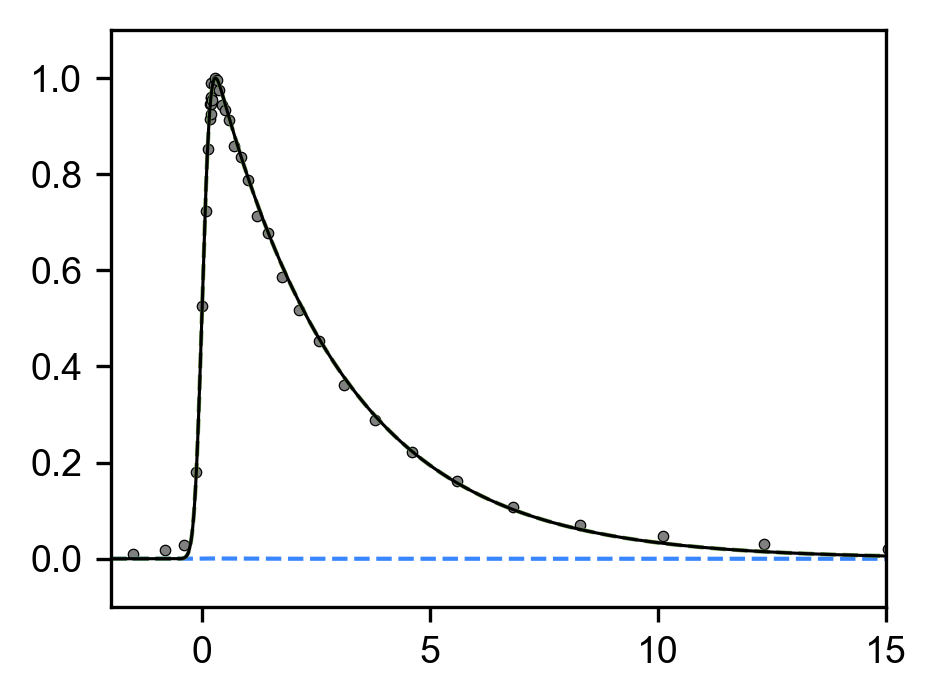

In [933]:
ax1 = plt.gca()
#DAS
delays = scanSet.delays-scanSet.t0
flat_ts = np.tile(ts,70)
#Integrated total fit
sum_DAS = global_fit_DAS(flat_ts,*params_DAS,time_points=len(ts)).reshape(70,len(ts))
sum_DAS = -np.trapezoid(sum_DAS,axis=0,x=scanSet.energies_rebinned[mask])
total_DAS = max(sum_DAS)
#Integrate monoexponentials
params_DAS1 = np.copy(params_DAS)
params_DAS1[3::2] = 0

sum_DAS1 = global_fit_DAS(flat_ts,*params_DAS1,time_points=len(ts)).reshape(70,len(ts))
sum_DAS1 = -np.trapezoid(sum_DAS1,axis=0,x=scanSet.energies_rebinned[mask])

#Integrate monoexponentials
params_DAS2 = np.copy(params_DAS)
params_DAS2[2::2] = 0

sum_DAS2 = global_fit_DAS(flat_ts,*params_DAS2,time_points=len(ts)).reshape(70,len(ts))
sum_DAS2 = -np.trapezoid(sum_DAS2,axis=0,x=scanSet.energies_rebinned[mask])

for ax in ax1,:
    ax.plot(delays,trace,'o',c='k',mfc='gray',mew=.3,ms=2.5,zorder=0)

    ax.plot(ts,sum_DAS1/total_DAS,'--',c=blue)
    ax.plot(ts,sum_DAS2/total_DAS,'--',c=green)
    # raise ValueError
    # ax.plot(ts,np.sum(A2s_DAS)*A_model(ts,1,tau2,sigma)/total_DAS,'--',c=green)
    ax.plot(ts,sum_DAS/total_DAS,'k',lw=.75,zorder=10)
    ax.plot(-10,-10,'k--',label="DAS")

#EAS
delays = scanSet.delays-scanSet.t0
sum_EAS = np.sum(A1s_EAS)*A_model(ts,1,tau1,sigma)+np.sum(A2s_EAS)*B_model(ts,1,tau1,tau2,sigma)
total_EAS = max(sum_EAS)
for ax in ax1,:
    # ax.plot(ts,np.sum(A1s_EAS)*A_model(ts,1,tau1,sigma)/total_EAS,':',c=blue)
    # ax.plot(ts,np.sum(A2s_EAS)*B_model(ts,1,tau1,tau2,sigma)/total_EAS,':',c=green)
    ax.plot(-10,-10,'k:',label="EAS")
ax1.set_xlim(-2,15)
ax.set_ylim(-.1,1.1)

np.float64(4.5984279814410645)

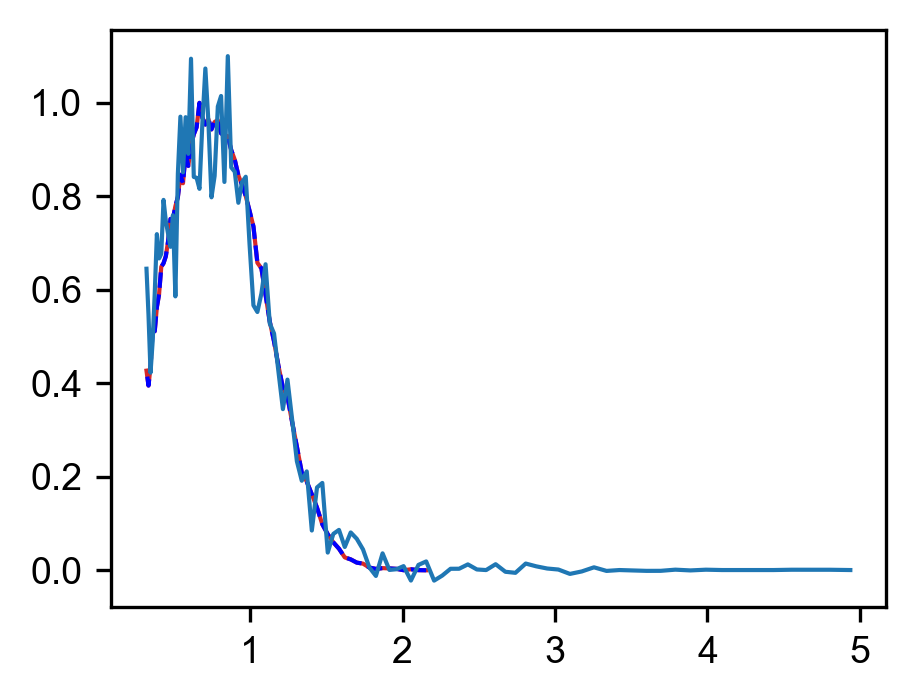

In [2541]:
plt.plot(energies_DAS,A2s_EAS/max(A2s_EAS),'-',c=red,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")
plt.plot(energies_DAS,A2s_DAS/max(A2s_DAS),'--',c='b',label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

n = 34
plt.plot(scanSet.energies_rebinned,1.1*scanSet.subtracted_rebinned[n]/max(scanSet.subtracted_rebinned[n]))
scanSet.delays[n]-scanSet.t0

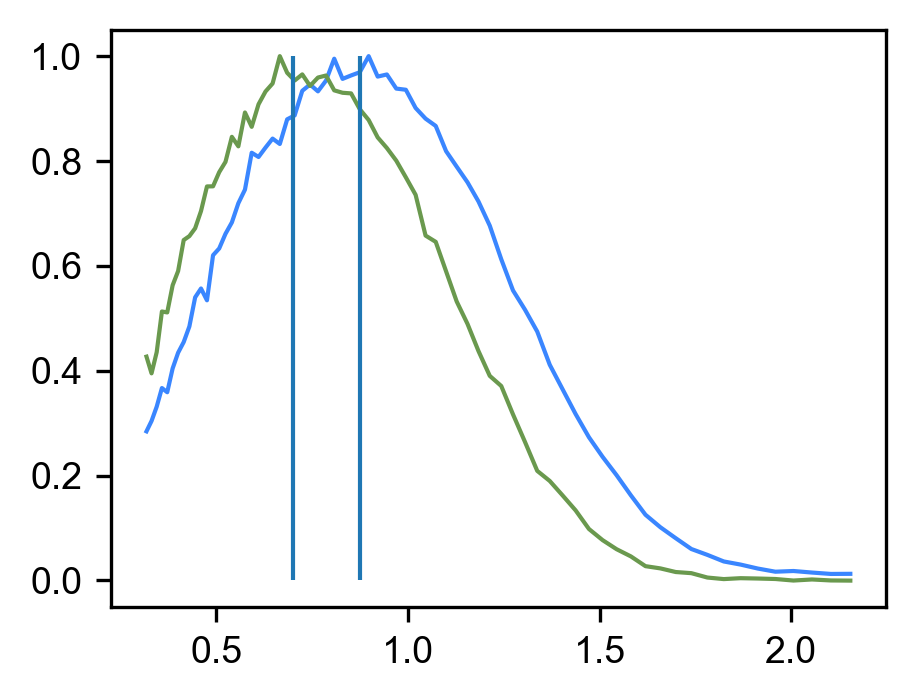

In [698]:
plt.plot(energies_DAS,A1s_EAS/max(A1s_EAS),'-',c=blue,label=f"$\\tau = ${tau1:.2f}$\\pm${tau2_err:.2f} ps")
plt.plot(energies_DAS,A2s_EAS/max(A2s_EAS),'-',c=green,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")
n = 5
# plt.plot(scanSet.energies_rebinned,1.1*scanSet.subtracted_rebinned[n]/max(scanSet.subtracted_rebinned[n]))
# scanSet.delays[n]-scanSet.t0
plt.vlines([.7,.875],0,1)


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 70 is different from 500)

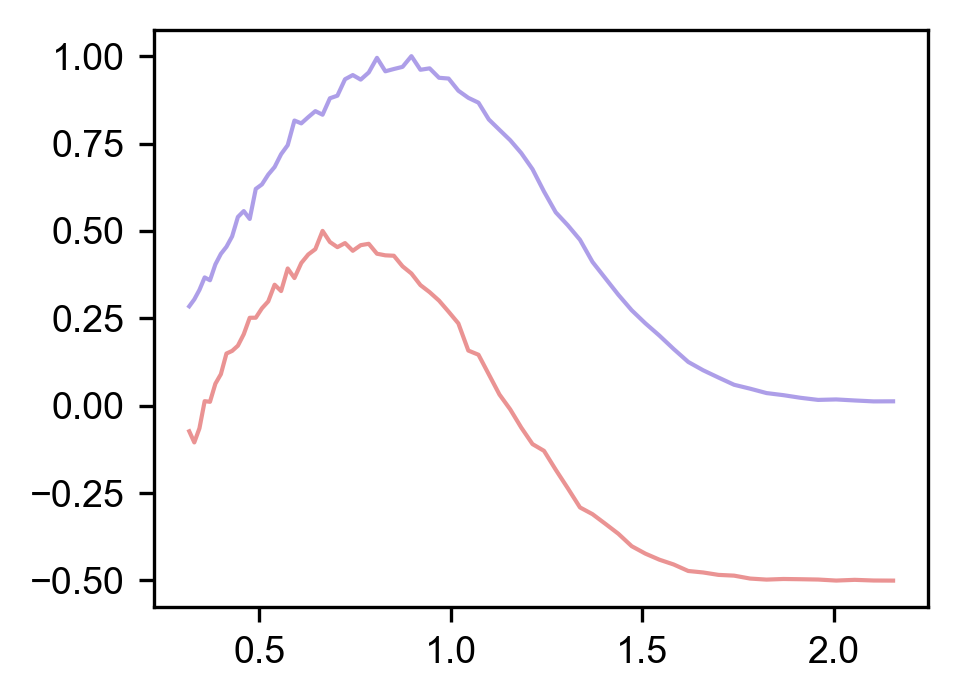

In [699]:
plt.plot(energies_DAS,A1s_EAS/max(A1s_EAS),'-',alpha=.5,c=violet,label=f"$\\tau = ${tau1:.2f}$\\pm${tau2_err:.2f} ps")
plt.plot(energies_DAS,A2s_EAS/max(A2s_EAS)-.5,'-',alpha=.5,c=red,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")

# plt.plot(energies_DAS,A1s_DAS/max(A1s_DAS),'--',c=red,label=f"$\\tau = ${tau1:.2f}$\\pm${tau2_err:.2f} ps")
# plt.plot(energies_DAS,A2s_DAS/max(A2s_DAS),'--',c=violet,label=f"$\\tau = ${tau2:.2f}$\\pm${tau2_err:.2f} ps")



A1 = retrieval_function(energies,*params[:3],0,0,1)
plt.plot(energies_cutoff,A1/max(A1),'-',c=violet)
A2 = retrieval_function(energies,*params[3:6],0,0,1)
plt.plot(energies_cutoff,A2/max(A2)-.5,'-',c=red)
plt.xlim(0,2.2)

### Animation

In [216]:
from IPython.display import HTML


In [217]:
    # fittableData = np.array((scanSet.energies,
    #                          scanSet.subtracted[ind]))
scanSet.subtracted_retrieved.shape

(36, 469)

In [218]:
(scanSet.delays)[5:-6]-scanSet.delays_retrieved

array([-0.19604905, -0.19604905, -0.19604905, -0.19604905, -0.19604905,
       -0.19604905, -0.19604905, -0.19604905, -0.19604905, -0.19604905,
       -0.19604905, -0.19604905, -0.19604905, -0.19604905, -0.19604905,
       -0.19604905, -0.19604905, -0.19604905, -0.19604905, -0.19604905,
       -0.19604905, -0.19604905, -0.19604905, -0.19604905, -0.19604905,
       -0.19604905, -0.19604905, -0.19604905, -0.19604905, -0.19604905,
       -0.19604905, -0.19604905, -0.19604905, -0.19604905, -0.19604905,
       -0.19604905])

In [219]:
scanSet.t0

np.float64(-0.19604905301589834)

In [220]:
for frame in range(47):
    print(scanSet.delays[frame]-scanSet.t0 in scanSet.delays_retrieved)

False
False
False
False
False
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
True
False
False
False
False
False
False


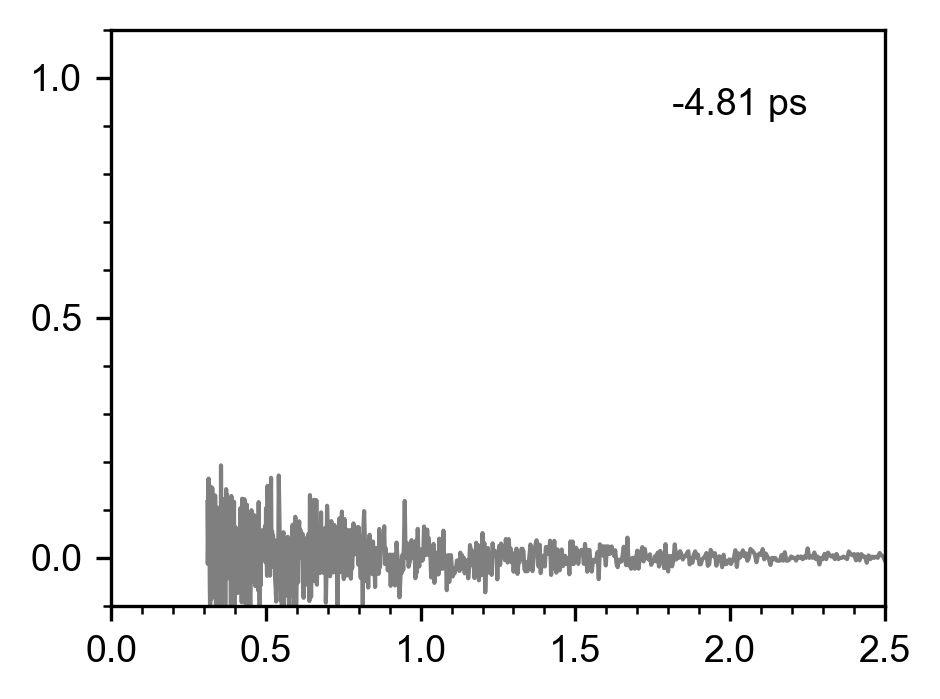

In [221]:
fig, ax = plt.subplots()

line, = ax.plot(scanSet.energies, scanSet.subtracted[0],'k',alpha=.5)
line_retr, = ax.plot(scanSet.energies_retrieved, scanSet.subtracted_retrieved[0]*0-10,'tab:red',zorder=10)
line_fit, = ax.plot(scanSet.energies_retrieved, scanSet.subtracted_fit[0]*0-10,'tab:blue',zorder=10)
text = ax.text(.9,.9,f"{scanSet.delays[0]-scanSet.t0:.2f} ps",ha='right',va='top',transform=ax.transAxes)
ax.set_xlim(0,2.5)
ax.set_ylim(-.1,1.1)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))


def update(frame):
    line.set_ydata(scanSet.subtracted[frame])
    scanSet.delays[frame]
    if scanSet.delays[frame]-scanSet.t0 in scanSet.delays_retrieved:
        retrieved_ind = np.where(scanSet.delays_retrieved == scanSet.delays[frame]-scanSet.t0)
        line_retr.set_ydata(scanSet.subtracted_retrieved[retrieved_ind])
        line_fit.set_ydata(scanSet.subtracted_fit[retrieved_ind])

    else:
        line_retr.set_ydata(scanSet.subtracted_retrieved[0]*0-10)
        line_fit.set_ydata(scanSet.subtracted_fit[0]*0-10)
        
    text.set_text(f"{scanSet.delays[frame]-scanSet.t0:.2f} ps")
    return line


ani = animation.FuncAnimation(fig=fig, func=update, frames=47, interval=100)
display(HTML(ani.to_jshtml()))

#### Proportional frames

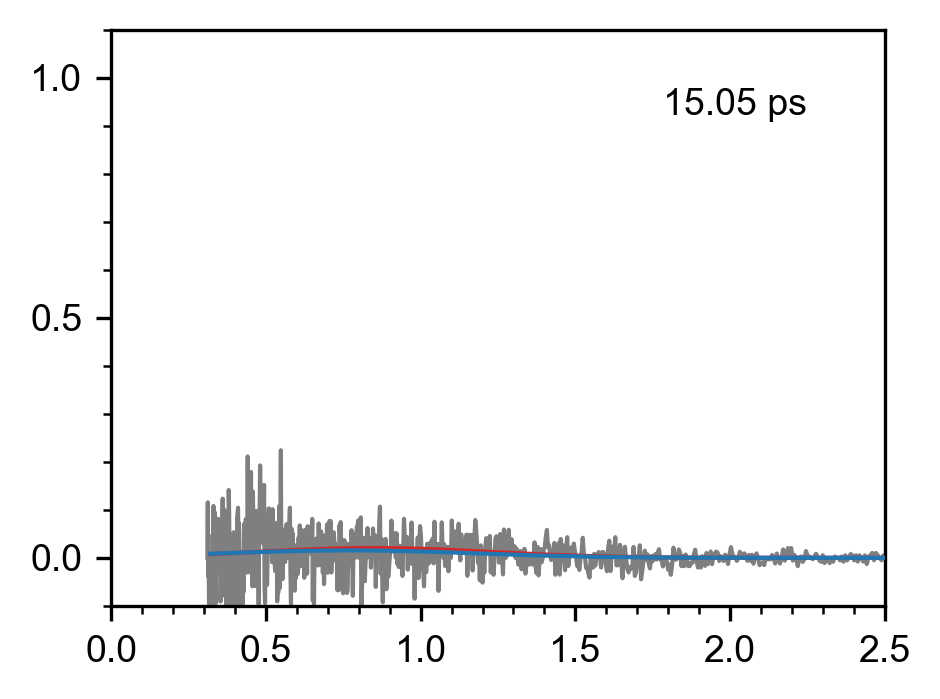

In [222]:
fig, ax = plt.subplots()

line, = ax.plot(scanSet.energies, scanSet.subtracted[0],'k',alpha=.5)
line_retr, = ax.plot(scanSet.energies_retrieved, scanSet.subtracted_retrieved[0]*0-10,'tab:red',zorder=10)
line_fit, = ax.plot(scanSet.energies_retrieved, scanSet.subtracted_fit[0]*0-10,'tab:blue',zorder=10)
text = ax.text(.9,.9,f"{scanSet.delays[0]-scanSet.t0:.2f} ps",ha='right',va='top',transform=ax.transAxes)
ax.set_xlim(0,2.5)
ax.set_ylim(-.1,1.1)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))

frame_durations = np.zeros_like(scanSet.delays)
frame_durations[:-1] = scanSet.delays[1:]-scanSet.delays[:-1]
frame_durations[-1] = frame_durations[-2]
frame_durations *=200
base_interval = 50  # smallest unit (ms) for video export

# Expand frames by repeating them according to delay
expanded_frames = []
for i, d in enumerate(frame_durations[:-6]):
    repeats = max(1, int(round(d / base_interval)))
    expanded_frames.extend([i] * repeats)


def update(frame):
    line.set_ydata(scanSet.subtracted[frame])
    # scanSet.delays[frame]
    if scanSet.delays[frame]-scanSet.t0 in scanSet.delays_retrieved:
        retrieved_ind = np.where(scanSet.delays_retrieved == scanSet.delays[frame]-scanSet.t0)
        line_retr.set_ydata(scanSet.subtracted_retrieved[retrieved_ind])
        line_fit.set_ydata(scanSet.subtracted_fit[retrieved_ind])

    else:
        line_retr.set_ydata(scanSet.subtracted_retrieved[0]*0-10)
        line_fit.set_ydata(scanSet.subtracted_fit[0]*0-10)
        
    text.set_text(f"{scanSet.delays[frame]-scanSet.t0:.2f} ps")
    return line, line_retr, line_fit, text


ani = animation.FuncAnimation(
    fig, update, frames=expanded_frames,
    blit=True, repeat=False, interval=base_interval
)
# ani.save("H2O_animation.gif", writer="pillow", fps=1000/base_interval)

display(HTML(ani.to_jshtml()))

In [1107]:
flat_spectra.shape[0]/47

469.0

Animation size has reached 20985717 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


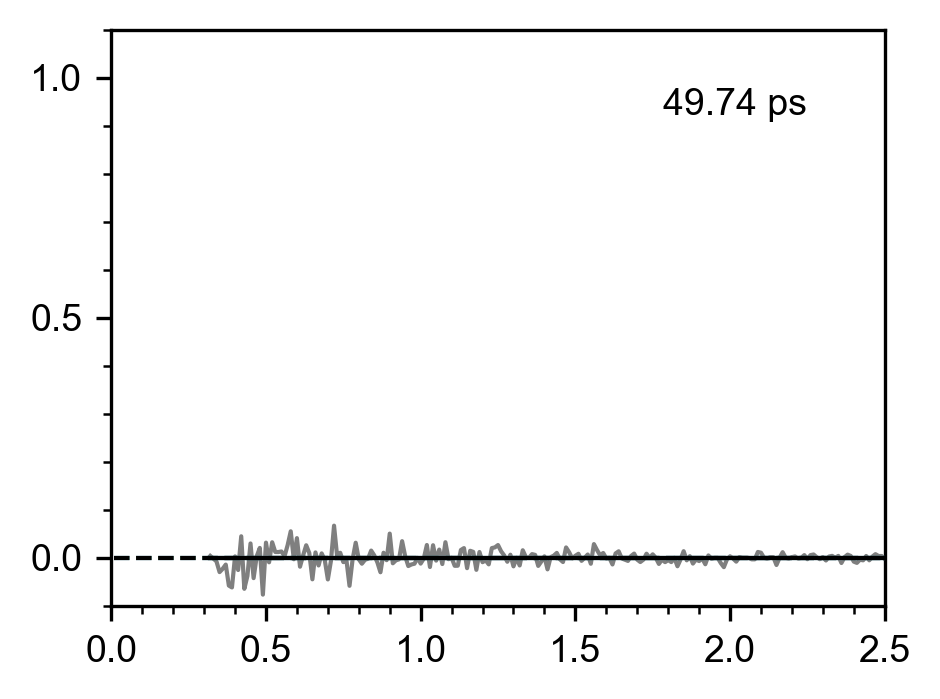

In [1121]:
fig, ax = plt.subplots()

unflat_spectra = flat_spectra.reshape((469,47)).T

line, = ax.plot(energies[energies>min_eKE], unflat_spectra[0],'k',alpha=.5)
line_retr, = ax.plot(energies,multiple_gaussians(energies,*params[:3])*0-10,'--',c=blue,zorder=10)
line_fit, = ax.plot(energies_cutoff,retrieval_function(energies,*params[:3],0,0,1)*0-10,c=blue,zorder=10)
line_retr2, = ax.plot(energies,multiple_gaussians(energies,*params[3:6])*0-10,'--',c=green,zorder=10)
line_fit2, = ax.plot(energies_cutoff,retrieval_function(energies,*params[3:6],0,0,1)*0-10,c=green,zorder=10)

line_retr_tot, = ax.plot(energies,multiple_gaussians(energies,*params[:6])*0-10,'--',c='k',zorder=10)
line_fit_tot, = ax.plot(energies_cutoff,retrieval_function(energies,*params[:6])*0-10,c='k',zorder=10)


text = ax.text(.9,.9,f"{scanSet.delays[0]-scanSet.t0:.2f} ps",ha='right',va='top',transform=ax.transAxes)
ax.set_xlim(0,2.5)
ax.set_ylim(-.1,1.1)
ax.xaxis.set_major_locator(MultipleLocator(.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.yaxis.set_major_locator(MultipleLocator(.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))

frame_durations = np.zeros_like(scanSet.delays)
frame_durations[:-1] = scanSet.delays[1:]-scanSet.delays[:-1]
frame_durations[-1] = frame_durations[-2]
frame_durations *=100
base_interval = 30  # smallest unit (ms) for video export

# Expand frames by repeating them according to delay
expanded_frames = []
for i, d in enumerate(frame_durations):
    repeats = max(1, int(round(d / base_interval)))
    expanded_frames.extend([i] * repeats)

#### Total counts and total scattered spectra
total_sig = np.sum(retrieval_function(energies,*params[:3],0,0,1))*A_model(ts,1,tau1,sigma) + np.sum(retrieval_function(energies,*params[3:6],0,0,1))*B_model(ts,1,tau1,tau2,sigma) 
total_norm = 1#np.max(total_sig)

norm = 1#params[0]/.8 # blue gaussian max

def update(frame):
    line.set_ydata(unflat_spectra[frame])
    # scanSet.delays[frame]
    # if scanSet.delays[frame]-scanSet.t0 in scanSet.delays_retrieved:
    if True:
        t = scanSet.delays[frame]-scanSet.t0
        A = A_model(t,1,tau1,sigma)
        line_retr.set_ydata(multiple_gaussians(energies,*params[:3])*A)
        line_fit.set_ydata(retrieval_function(energies,*params[:3],0,0,1)*A)
        
        B = B_model(t,1,tau1,tau2,sigma)
        line_retr2.set_ydata(multiple_gaussians(energies,*params[3:6])*B)
        line_fit2.set_ydata(retrieval_function(energies,*params[3:6],0,0,1)*B)

        line_retr_tot.set_ydata(multiple_gaussians(energies,params[0]*A,*params[1:3],params[3]*B,*params[4:6]))
        line_fit_tot.set_ydata(global_fit(flat_energies,*params).reshape(len(energies_cutoff),47).T[frame])

    else:
        line_retr.set_ydata(multiple_gaussians(energies,*params[:3])*0-10)
        line_fit.set_ydata(retrieval_function(energies,*params[:3],0,0,1)*0-10)
        line_retr2.set_ydata(multiple_gaussians(energies,*params[3:6])*0-10)
        line_fit2.set_ydata(retrieval_function(energies,*params[3:6],0,0,1)*0-10)
        
    text.set_text(f"{scanSet.delays[frame]-scanSet.t0:.2f} ps")
    return line, line_retr, line_fit, text


ani = animation.FuncAnimation(
    fig, update, frames=expanded_frames,
    blit=True, repeat=False, interval=base_interval
)
# ani.save("H2O_animation_EAS.gif", writer="pillow", fps=500/base_interval)


display(HTML(ani.to_jshtml()))

### Save scanSet.subtracted for Koala

In [ ]:
scanSet.subtracted

In [ ]:
saveData = np.copy(scanSet.subtracted)

saveData = np.hstack((scanSet.delays.reshape(47,1)-scanSet.t0,saveData))

energies_0 = np.concatenate(([0,],scanSet.energies))
saveData=np.vstack((energies_0.reshape(1032,1).T,saveData))

In [ ]:
np.savetxt('pCE_TRPES.csv',saveData.T,delimiter=',')

### Save scanSet.subtracted_rebinned for Koala

In [2437]:
scanSet.subtracted_rebinned

array([[ 0.        ,  0.        , -0.00030133, ...,  0.02444295,
         0.04021969,  0.02532377],
       [ 0.        ,  0.        ,  0.        , ..., -0.00142753,
         0.02496261, -0.02718284],
       [ 0.        ,  0.        ,  0.        , ..., -0.03163557,
         0.0480492 ,  0.04548503],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.00254212,
         0.05568167,  0.01882719],
       [ 0.        , -0.00014414,  0.        , ...,  0.03320829,
         0.06819129,  0.02379973],
       [ 0.        , -0.00014316,  0.        , ..., -0.03574005,
        -0.02248328,  0.01488088]], shape=(47, 103))

In [2440]:
saveData = np.copy(scanSet.subtracted_rebinned)

saveData = np.hstack((scanSet.delays.reshape(47,1)-scanSet.t0,saveData))

energies_0 = np.concatenate(([0,],scanSet.energies_rebinned))
saveData=np.vstack((energies_0.reshape(104,1).T,saveData))

In [2441]:
np.savetxt('pCE_TRPES_rebinned.csv',saveData.T,delimiter=',')

### Save t=0 for comparison with 350 nm spectrum

np.float64(-0.006090788674161046)

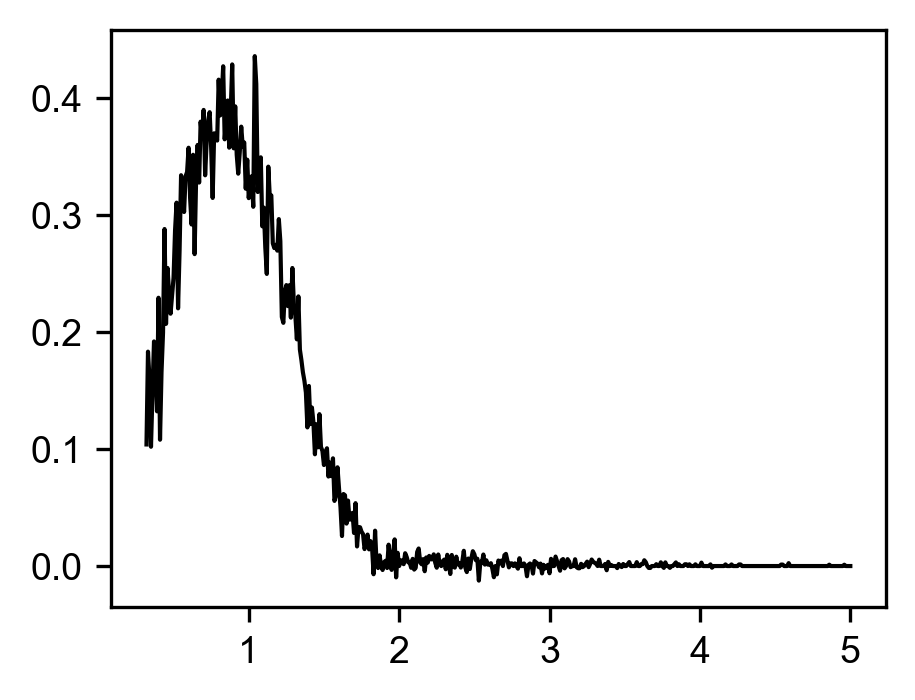

In [2425]:
# scanSet.energies_retrieved,
t0_ind = np.argmin(abs(scanSet.delays_retrieved))
t0_spectrum = scanSet.subtracted_grid[t0_ind]
plt.plot(scanSet.energies_retrieved,t0_spectrum,'k')
saveSpectrum = np.array((scanSet.energies_retrieved,t0_spectrum))
# saveSpectrum.T
# np.savetxt('pCE_TR_t0spectrum.csv',saveSpectrum.T,delimiter=',')


### Colour test

In [266]:
# green = '#2A9D8F'
# blue = '#1f77b4'

green = '#90BE6D'

# orange= '#FFBE0B'
# blue = '#4CC9F0'

blue ='#3A86FF'
green='#6A994E'

In [267]:
cs = [red,violet,blue,green]

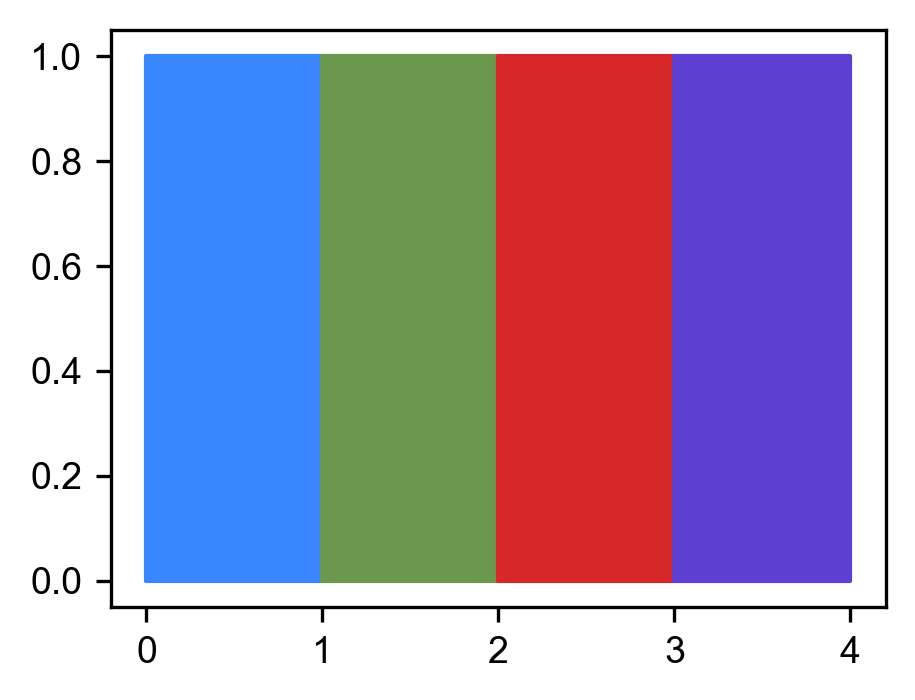

In [268]:
np.random.shuffle(cs)
for i in range(4):
    plt.fill_between([0+i,1+i],[0,0],[1,1],color=cs[i])
    # plt.plot([0,1],[0+i,1+i],color=cs[i])


In [2206]:
maximum = 1
for amp in [0,0.1,0.2,.5,1,2,2.75,3,4,5,10,20,50,100]:
    maximum *= 1+amp
    print(amp,'\t',maximum-1)


0 	 0
0.1 	 0.10000000000000009
0.2 	 0.32000000000000006
0.5 	 0.98
1 	 2.96
2 	 10.879999999999999
2.75 	 43.55
3 	 177.2
4 	 890.0
5 	 5345.0
10 	 58805.0
20 	 1234925.0
50 	 62981225.0
100 	 6361103825.0


### Free first tau and constrained second tau

#### The model



In [983]:
def I(t,k,sigma):
    """Monoexponential helper function"""
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2*(k1/(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    

def kinetic_model_gau(x,A1,A2,tau1):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    tau2 = 2.84328509 # constrained to EAS/DAS
    return A_model(x-t0,A1,tau1,sigma) + B_model(x-t0,A2,tau1,tau2,sigma)


#### Flatten delays + traces

In [984]:
#Mask traces
mask = scanSet.energies_rebinned<2.2
traces = scanSet.subtracted_rebinned[:,mask]
traces.shape

(47, 70)

In [985]:
# Normalise traces
#Total counts
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
traces /= max(trace)
traces.shape

(47, 70)

In [986]:
energies = scanSet.energies_rebinned[mask]
max(-energies[1:]+energies[:-1])

np.float64(0.050695580386485695)

In [989]:
energies = scanSet.energies_rebinned[mask]

#Set limits for time ranges
energyStep = 0.1
energyLimit = 0.3 # eV

traces_binned = []

    
while energyLimit<2.2:
    #Binned data
    #Mask data outside of time range
    mask_bins = (np.logical_and(energies>energyLimit,
                                energies<=energyLimit+energyStep))
    # print(energyLimit,energyLimit+energyStep)
    masked_data = traces.T[mask_bins]
    # print((energies[mask_bins]))#,f"{energies[mask_bins][-1]:.3f}, {energies[mask_bins][0]:.3f}")
    if len(energies[mask_bins])>1:
        mean_data = np.trapezoid(masked_data,axis=0,x=energies[mask_bins])/(energies[mask_bins][-1]-energies[mask_bins][0])
    elif len(energies[mask_bins])==1:
        mean_data = masked_data[0]
        
    
    # mean_data = np.mean(masked_data,axis=0)
    traces_binned.append(mean_data)
    # print(mean_data.shape)
    energyLimit += energyStep
    energyLimit = round(energyLimit,2)
traces_binned = np.array(traces_binned).T
traces_binned.shape

(47, 19)

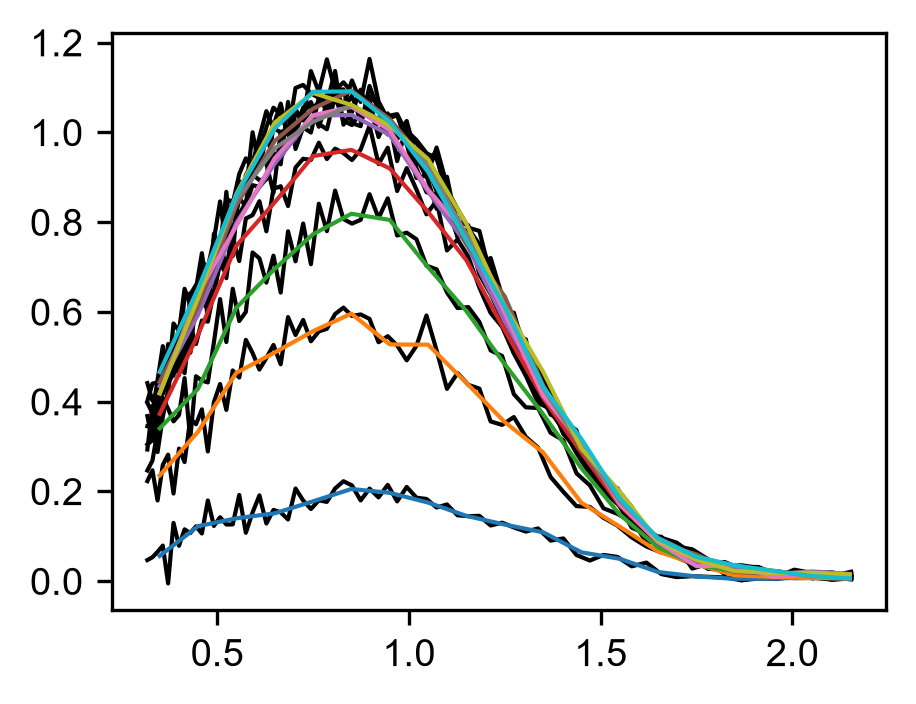

In [990]:
energies = np.arange(0.3,2.2,energyStep)+energyStep/2
plt.plot(energies,traces_binned[5:15].T)
# plt.vlines(energies,0,1)
energies = scanSet.energies_rebinned[mask]
plt.plot(energies,traces[5:15].T,'k',zorder=0)
# plt.xlim(1.3,1.5)

In [991]:
delays = scanSet.delays-scanSet.t0
delays.shape

(47,)

In [992]:
# traces_binned = traces

#### Fit

In [993]:
p0 = [1,1,0.5]
all_params = []
all_perrs = []
for trace in traces_binned.T:
    params, pcov = curve_fit(kinetic_model_gau,delays,trace,
                        p0 = p0,bounds=(0,np.inf),)
    perr = np.sqrt(np.diag(pcov))

    all_params.append(params)
    all_perrs.append(perr)
all_params = np.array(all_params)
all_perrs = np.array(all_perrs)
all_params.shape

C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\2302555522.py:4: RuntimeWarning: overflow encountered in exp
  return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))
C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\2302555522.py:4: RuntimeWarning: invalid value encountered in multiply
  return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))


(19, 3)

#### Plot results of fit and residuals for each trace

(-1.0, 5.0)

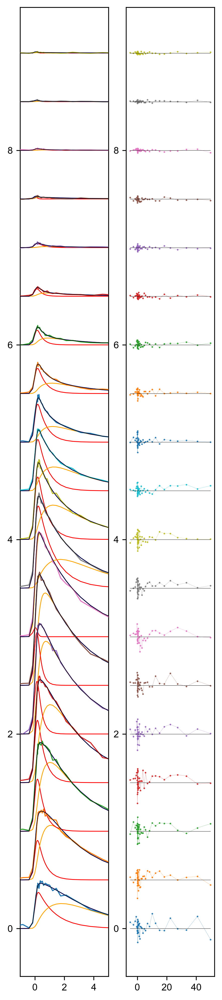

In [994]:
fig, (ax0,ax1) = plt.subplots(1,2)
# params=p0
A1s = all_params[:,0]
A2s = all_params[:,1]
tau1 = all_params[:,2]

A1s_err = all_perrs[:,0]
A2s_err = all_perrs[:,1]
tau1_err = all_perrs[:,2]

sigma = 0.320 / 2.355 #cross-correlation with 250 & 267
t0 = 0
tau2 = 2.84328509 

for n in range(len(tau1)):
    
    ax0.plot(delays,traces_binned[:,n]+.5*n,zorder=20)
    
    trace = kinetic_model_gau(delays,A1s[n],A2s[n],tau1[n])
    ax0.plot(delays,trace+.5*n,'k',zorder=30,lw=.5)
    
    
    trace =  A_model(delays,A1s[n],tau1[n],sigma)
    ax0.plot(delays,trace+.5*n,'r',lw=.75)
    
    trace =  B_model(delays,A2s[n],tau1[n],tau2,sigma)
    ax0.plot(delays,trace+.5*n,'orange',lw=.75)
    ax0.plot(delays,A_model(delays,A1s[n],tau1[n],sigma)+trace+.5*n,'b',lw=.75)

    # Residuals
    trace = kinetic_model_gau(delays,A1s[n],A2s[n],tau1[n])
    ax1.plot(delays,3*(traces_binned[:,n]-trace)+.5*n,'o-',zorder=20,ms=.5,lw=.1)
    ax1.plot(delays,delays*0+.5*n,'k',zorder=30,lw=.25)
    
ax1.set_ylim(ax0.get_ylim())
plt.gcf().set_size_inches(ACSwid,ACSwid*5)

ax0.set_xlim(-1,5)

#### Plot EAS

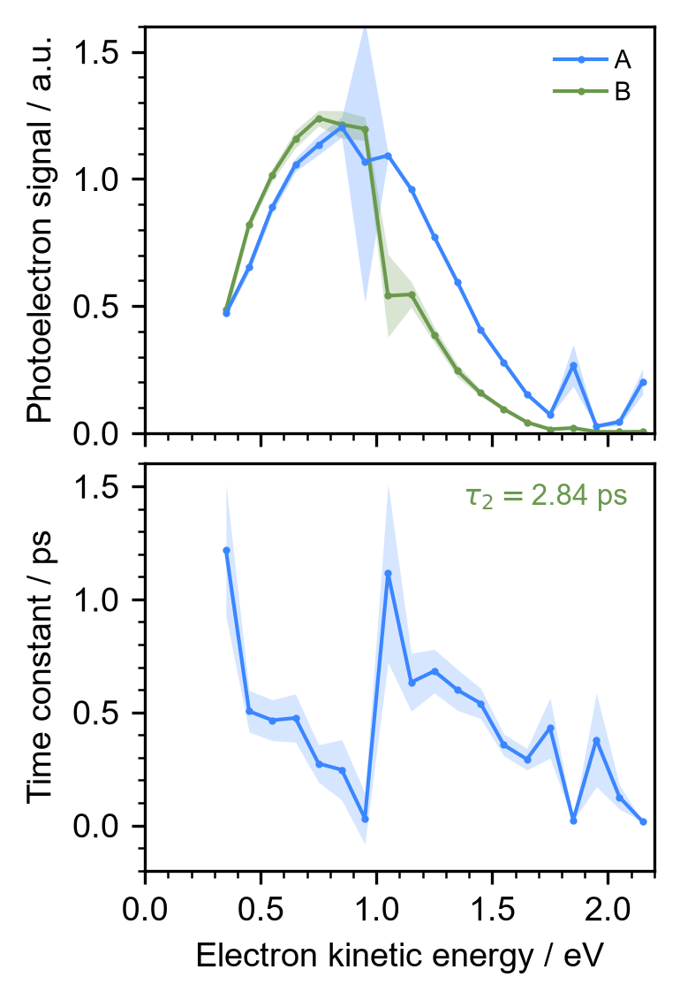

In [1001]:
fig,(ax0,ax1) = plt.subplots(2)
plt.subplots_adjust(hspace=0.075)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid*0.75)


energies = scanSet.energies_rebinned[mask]
energies = np.arange(0.3,2.2,energyStep)+energyStep/2

ax0.plot(energies,A1s,'o-',c=blue,ms=1,zorder=100,label='A')
ax0.plot(energies,A2s,'o-',c=green,ms=1,label='B')
ax0.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.25,color=blue,lw=0)
ax0.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.25,color=green,lw=0)

# ax2 = ax.twinx() 
ax1.plot(energies,tau1,'o-',c=blue,ms=1)
ax1.fill_between(energies,tau1-tau1_err,tau1+tau1_err,alpha=.2,color=blue,lw=0)

# ax2.errorbar(energies,tau1,tau1_err,capsize=2,fmt='o',ms=2)


ax1.text(.95,.82,f"$\\tau_2 =${tau2:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax1.transAxes,alpha=1)

# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax0.set_xlim(0,2.2)
ax1.set_xlim(0,2.2)
ax0.set_ylim(0,1.6)
ax1.set_ylim(-.2,1.6)

for ax in (ax0,ax1):
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(0.1))
ax1.yaxis.set_major_locator(MultipleLocator(.5))
ax1.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax1.set_xlabel("Electron kinetic energy / eV",)
ax0.set_ylabel("Photoelectron signal / a.u.")
ax1.set_ylabel("Time constant / ps")


ax0.set_xticklabels([])
ax0.legend()

# ax2.yaxis.label.set_color(green)

# ax2.spines["right"].set_edgecolor(blue)
# ax2.tick_params(axis='y', which='both',colors=blue)

In [996]:
energies

array([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2, 1.3, 1.4, 1.5, 1.6,
       1.7, 1.8, 1.9, 2. , 2.1, 2.2])

### Free first tau and free second tau

#### The model



In [543]:
def I(t,k,sigma):
    """Monoexponential helper function"""
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2*(k1/(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    

def kinetic_model_gau(x,A1,A2,tau1,tau2):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A_model(x-t0,A1,tau1,sigma) + B_model(x-t0,A2,tau1,tau2,sigma)


#### Flatten delays + traces

In [544]:
#Mask traces
mask = scanSet.energies_rebinned<2.2
traces = scanSet.subtracted_rebinned[:,mask]
traces.shape

(47, 70)

In [545]:
# Normalise traces
#Total counts
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
traces /= max(trace)
traces.shape

(47, 70)

In [546]:
energies = scanSet.energies_rebinned[mask]
max(-energies[1:]+energies[:-1])

np.float64(0.050695580386485695)

In [547]:
energies = scanSet.energies_rebinned[mask]

#Set limits for time ranges
energyStep = 0.09
energyLimit = 0.3 # eV

traces_binned = []

    
while energyLimit<2.2:
    #Binned data
    #Mask data outside of time range
    mask_bins = (np.logical_and(energies>energyLimit,
                                energies<=energyLimit+energyStep))
    # print(energyLimit,energyLimit+energyStep)
    masked_data = traces.T[mask_bins]
    # print((energies[mask_bins]))#,f"{energies[mask_bins][-1]:.3f}, {energies[mask_bins][0]:.3f}")
    if len(energies[mask_bins])>1:
        mean_data = np.trapezoid(masked_data,axis=0,x=energies[mask_bins])/(energies[mask_bins][-1]-energies[mask_bins][0])
    elif len(energies[mask_bins])==1:
        mean_data = masked_data[0]
        
    
    # mean_data = np.mean(masked_data,axis=0)
    traces_binned.append(mean_data)
    # print(mean_data.shape)
    energyLimit += energyStep
    energyLimit = round(energyLimit,2)
traces_binned = np.array(traces_binned).T
traces_binned.shape

(47, 22)

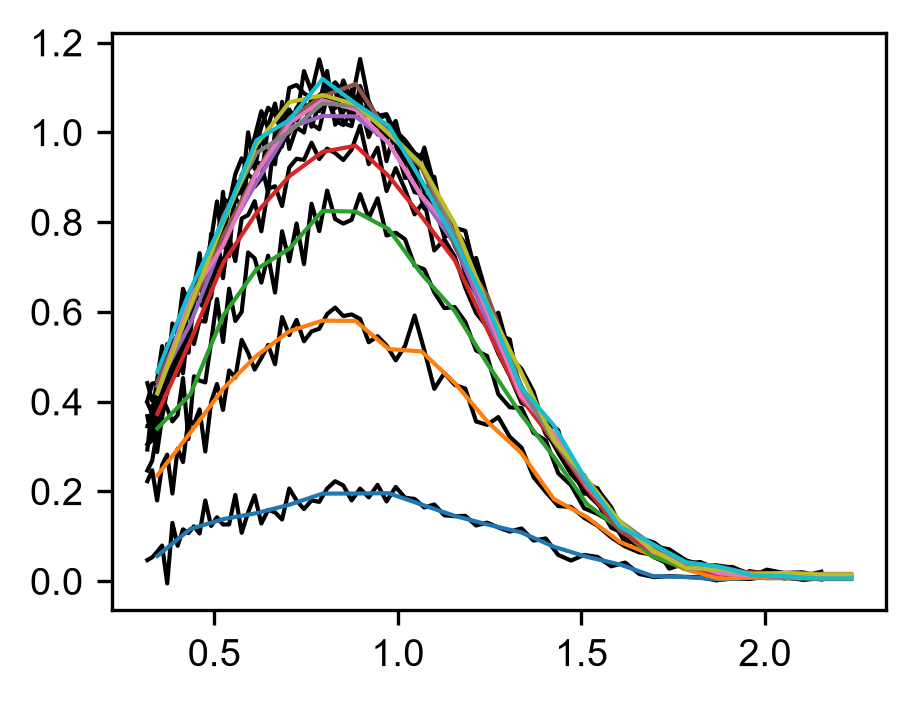

In [548]:
energies = np.arange(0.3,2.2,energyStep)+energyStep/2
plt.plot(energies,traces_binned[5:15].T)
# plt.vlines(energies,0,1)
energies = scanSet.energies_rebinned[mask]
plt.plot(energies,traces[5:15].T,'k',zorder=0)
# plt.xlim(1.3,1.5)

In [540]:
delays = scanSet.delays-scanSet.t0
delays.shape

(47,)

In [512]:
traces_binned = traces

#### Fit

In [549]:
p0 = [1,1,0.6,2.8]
all_params = []
all_perrs = []
for trace in traces_binned.T:
    params, pcov = curve_fit(kinetic_model_gau,delays,trace,
                        p0 = p0,bounds=(0,5),)
    perr = np.sqrt(np.diag(pcov))

    all_params.append(params)
    all_perrs.append(perr)
all_params = np.array(all_params)
all_perrs = np.array(all_perrs)
all_params.shape

C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\2907288945.py:4: RuntimeWarning: overflow encountered in exp
  return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))
C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\2907288945.py:4: RuntimeWarning: invalid value encountered in multiply
  return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))


(22, 4)

#### Plot results of fit and residuals for each trace

(-1.0, 5.0)

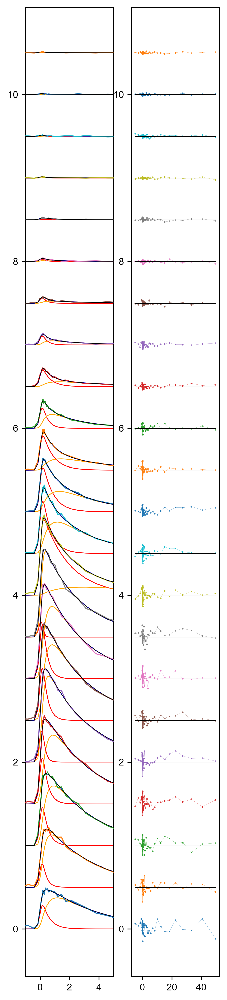

In [550]:
fig, (ax0,ax1) = plt.subplots(1,2)
# params=p0
A1s = all_params[:,0]
A2s = all_params[:,1]
tau1 = all_params[:,2]
tau2 = all_params[:,3]

A1s_err = all_perrs[:,0]
A2s_err = all_perrs[:,1]
tau1_err = all_perrs[:,2]
tau2_err = all_perrs[:,3]

sigma = 0.320 / 2.355 #cross-correlation with 250 & 267
t0 = 0

for n in range(len(tau1)):
    
    ax0.plot(delays,traces_binned[:,n]+.5*n,zorder=20)
    
    trace = kinetic_model_gau(delays,A1s[n],A2s[n],tau1[n],tau2[n])
    ax0.plot(delays,trace+.5*n,'k',zorder=30,lw=.5)
    
    
    trace =  A_model(delays,A1s[n],tau1[n],sigma)
    ax0.plot(delays,trace+.5*n,'r',lw=.75)
    
    trace =  B_model(delays,A2s[n],tau1[n],tau2[n],sigma)
    ax0.plot(delays,trace+.5*n,'orange',lw=.75)
    ax0.plot(delays,A_model(delays,A1s[n],tau1[n],sigma)+trace+.5*n,'b',lw=.75)

    # Residuals
    trace = kinetic_model_gau(delays,A1s[n],A2s[n],tau1[n],tau2[n])
    ax1.plot(delays,3*(traces_binned[:,n]-trace)+.5*n,'o-',zorder=20,ms=.5,lw=.1)
    ax1.plot(delays,delays*0+.5*n,'k',zorder=30,lw=.25)
    
ax1.set_ylim(ax0.get_ylim())
plt.gcf().set_size_inches(ACSwid,ACSwid*5)

ax0.set_xlim(-1,5)

#### Plot EAS

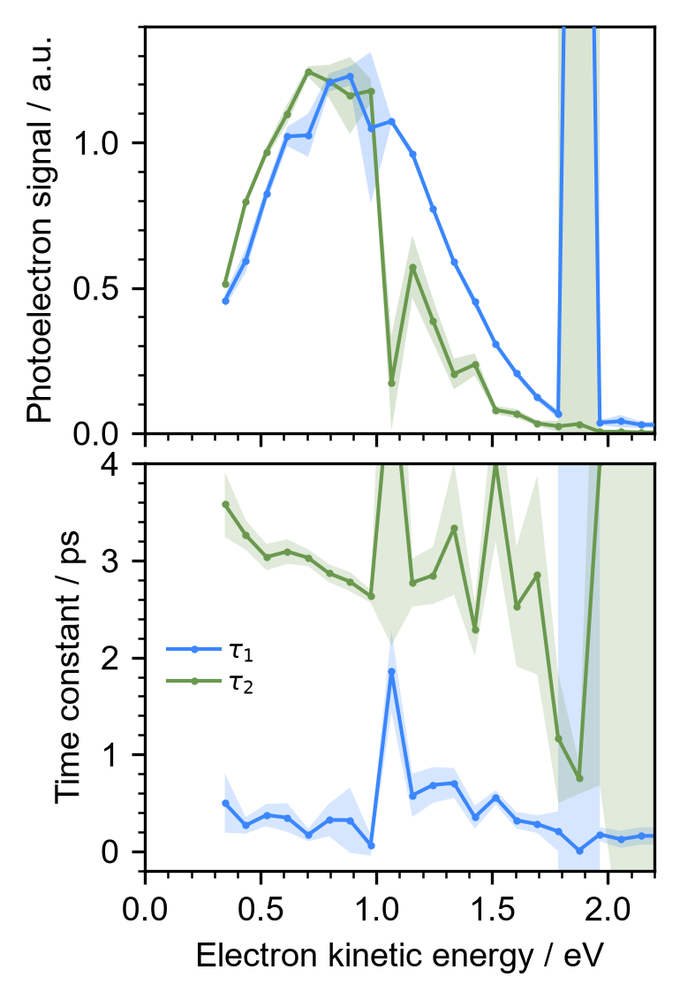

In [552]:
fig,(ax0,ax1) = plt.subplots(2)
plt.subplots_adjust(hspace=0.075)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid*0.75)


energies = scanSet.energies_rebinned[mask]
energies = np.arange(0.3,2.2,energyStep)+energyStep/2

ax0.plot(energies,A1s,'o-',c=blue,ms=1,zorder=100)
ax0.plot(energies,A2s,'o-',c=green,ms=1)
ax0.fill_between(energies,A1s-A1s_err,A1s+A1s_err,alpha=.25,color=blue,lw=0)
ax0.fill_between(energies,A2s-A2s_err,A2s+A2s_err,alpha=.25,color=green,lw=0)

ax1.plot(energies,tau1,'o-',c=blue,ms=1,label="$\\tau_1$")
ax1.fill_between(energies,tau1-tau1_err,tau1+tau1_err,alpha=.2,color=blue,lw=0)
ax1.plot(energies,tau2,'o-',c=green,ms=1,label="$\\tau_2$")
ax1.fill_between(energies,tau2-tau2_err,tau2+tau2_err,alpha=.2,color=green,lw=0)

# ax2.errorbar(energies,tau1,tau1_err,capsize=2,fmt='o',ms=2)



# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax0.set_xlim(0,2.2)
ax1.set_xlim(0,2.2)
ax0.set_ylim(0,1.4)
ax1.set_ylim(-.2,4)

for ax in (ax0,ax1):
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(0.1))
ax1.yaxis.set_major_locator(MultipleLocator(1))
ax1.yaxis.set_minor_locator(MultipleLocator(0.2))
    
ax1.set_xlabel("Electron kinetic energy / eV",)
ax0.set_ylabel("Photoelectron signal / a.u.")
ax1.set_ylabel("Time constant / ps")


ax0.set_xticklabels([])
ax1.legend()
# ax2.yaxis.label.set_color(green)

# ax2.spines["right"].set_edgecolor(blue)
# ax2.tick_params(axis='y', which='both',colors=blue)

### GLobal fitting with constraints

#### The model



In [1161]:
def I(t,k,sigma):
    """Monoexponential helper function"""
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2*(k1/(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    

def kinetic_model_gau(x,A1,A2,tau1,tau2):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A_model(x-t0,A1,tau1,sigma) + B_model(x-t0,A2,tau1,tau2,sigma)

def global_fit(flat_delays, tau1, tau2, *amplitudes,traces_number = 70):
    # traces_number = 70
    points_per_trace = 47

    delays = flat_delays.reshape(traces_number, points_per_trace)
    amps = np.array(amplitudes).reshape(traces_number, 2)  

    return kinetic_model_gau(
        delays,
        amps[:, 0][:, None], 
        amps[:, 1][:, None],
        tau1, tau2,
    ).ravel()

#### Flatten delays + traces

In [1162]:
#Mask traces
mask = scanSet.energies_rebinned<2.2
traces = scanSet.subtracted_rebinned[:,mask]
traces.shape

(47, 70)

In [1163]:
# Normalise traces
#Total counts
trace = -np.trapezoid(scanSet.subtracted_rebinned,axis=1,x=scanSet.energies_rebinned)
traces /= max(trace)
traces.shape

(47, 70)

In [1164]:
energies = scanSet.energies_rebinned[mask]

#Set limits for time ranges
energyStep = .2
energyLimit = 0.3 # eV

traces_grouped = []
energies_grouped = []

    
while energyLimit<2.2:
    #Mask data outside of time range
    mask_bins = (np.logical_and(energies>energyLimit,
                                energies<=energyLimit+energyStep))
    # print(energyLimit,energyLimit+energyStep)
    masked_data = traces[:,mask_bins]
    masked_energies = energies[mask_bins]
    
    
        
    
    traces_grouped.append(masked_data)
    energies_grouped.append(masked_energies)
    energyLimit += energyStep
    energyLimit = round(energyLimit,2)
    
# traces_grouped

In [1165]:
delays_grouped = []
delays = scanSet.delays-scanSet.t0
# Tile delays
for trace_group in traces_grouped:
    flat_delays = np.tile(delays,(trace_group.shape[1]))
    delays_grouped.append(flat_delays)

In [1166]:
# define functions
def make_fit_model(traces_number):
    """Generates a custom fit_model function for a specific traces_number."""
    def fit_model(flat_delays, tau1, *amplitudes):
        tau2=2.8433
        # tau1=0.54994703
        return global_fit(
            flat_delays, 
            tau1, 
            tau2, 
            *amplitudes, 
            traces_number=traces_number
        )
    return fit_model
    
fit_models = [make_fit_model(len(trace_group.T)) for trace_group in traces_grouped] 
fit_models[0]

<function __main__.make_fit_model.<locals>.fit_model(flat_delays, tau1, *amplitudes)>

In [1167]:
#flatten traces
traces_grouped_flat = []
for i,trace_group in enumerate(traces_grouped):
    traces_grouped_flat.append(trace_group.T.flatten())

In [1168]:
traces_grouped_flat[1].shape,delays_grouped[1].shape

((517,), (517,))

#### Fit

In [1169]:
all_params = []
all_perrs = []
for i in range(len(traces_grouped)):
    trace_group = traces_grouped[i]
    flat_delays = delays_grouped[i]
    fit_model = fit_models[i]
    flat_traces = traces_grouped_flat[i]

    p0 = [1]+[1 for n in range(len(trace_group.T)) for x in (1,1)]

    print(trace_group.shape)
    
    params, pcov = curve_fit(fit_model,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
    perr = np.sqrt(np.diag(pcov))

    all_params.append(params)
    all_perrs.append(perr)
# all_params = np.array(all_params)
# all_perrs
# all_params.shape

(47, 13)
(47, 11)
(47, 10)
(47, 8)
(47, 6)
(47, 6)
(47, 6)
(47, 4)
(47, 4)
(47, 2)


C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\223128000.py:4: RuntimeWarning: overflow encountered in exp
  return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))
C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\223128000.py:18: RuntimeWarning: invalid value encountered in add
  return A_model(x-t0,A1,tau1,sigma) + B_model(x-t0,A2,tau1,tau2,sigma)


#### Results

In [1170]:
tau1 = []
tau2 = []
A1s = []
A2s = []
tau1_err = []
tau2_err = []
A1s_err = []
A2s_err = []
energies_plot = []
for i, params in enumerate(all_params[::-1]):
    A1s += list(params[1::2])
    A2s += list(params[2::2])
    energies_plot += list(energies_grouped[-i-1])

    tau1.append(params[0])
    # tau2.append(params[1])
    #errors
    A1s_err += list(all_perrs[-i-1][1::2])
    A2s_err += list(all_perrs[-i-1][2::2])
    tau1_err.append(all_perrs[-i-1][0])
    # tau2_err.append(all_perrs[-i-1][1])
tau1 = np.array(tau1)
tau2 = np.array(tau2)
A1s = np.array(A1s)
A2s = np.array(A2s)
tau1_err = np.array(tau1_err)
tau2_err = np.array(tau2_err)
A1s_err = np.array(A1s_err)
A2s_err = np.array(A2s_err)

energies_plot = np.array(energies_plot)
energies_tau = np.arange(0.3,2.2,energyStep)+energyStep/2
energies_tau = energies_tau[::-1]

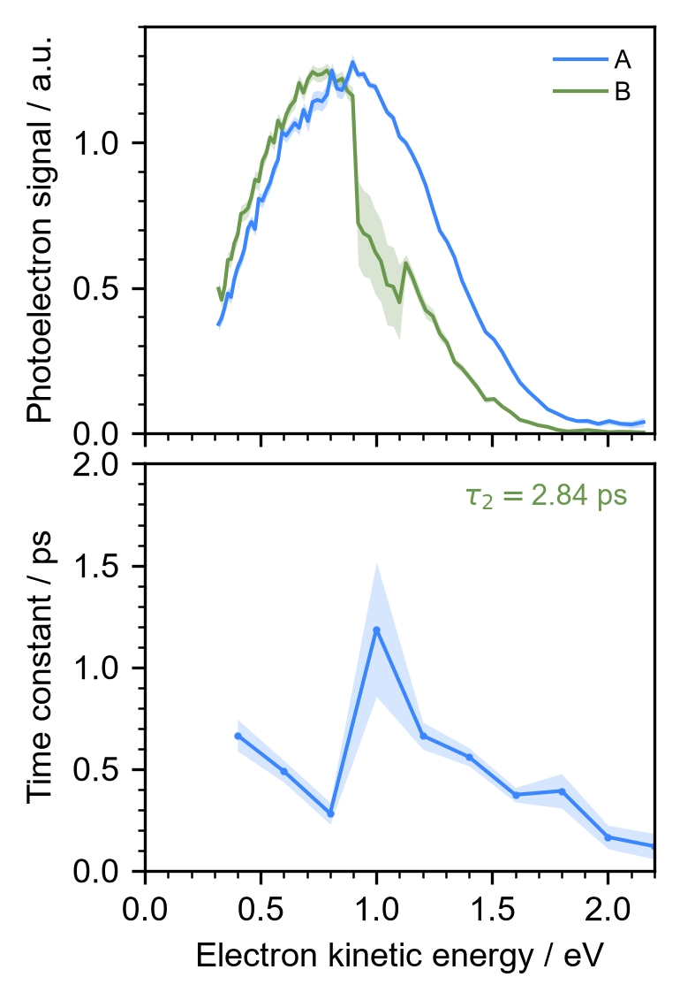

In [1173]:
fig,(ax0,ax1) = plt.subplots(2)
plt.subplots_adjust(hspace=0.075)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid*0.75)


ax0.plot(energies_plot,A1s,'-',c=blue,ms=1,zorder=100,label='A')
ax0.plot(energies_plot,A2s,'-',c=green,ms=1,label='B')
ax0.fill_between(energies_plot,A1s-A1s_err,A1s+A1s_err,alpha=.25,color=blue,lw=0)
ax0.fill_between(energies_plot,A2s-A2s_err,A2s+A2s_err,alpha=.25,color=green,lw=0)

ax1.plot(energies_tau,tau1,'o-',c=blue,ms=1,label="$\\tau_1$")
ax1.fill_between(energies_tau,tau1-tau1_err,tau1+tau1_err,alpha=.2,color=blue,lw=0)
# ax1.errorbar(energies_tau,tau1,tau1_err,capsize=2,fmt='o',ms=2,color=blue)

# ax1.plot(energies_tau,tau2,'o-',c=green,ms=1,label="$\\tau_2$")
# ax1.fill_between(energies_tau,tau2-tau2_err,tau2+tau2_err,alpha=.2,color=green,lw=0)


ax1.text(.95,.82,f"$\\tau_2 =${2.84:.2f} ps\n",ha='right',c=green,fontsize=8,transform=ax1.transAxes,alpha=1)



ax0.set_xlim(0,2.2)
ax1.set_xlim(0,2.2)
ax0.set_ylim(-0.499,1.6)
ax0.set_ylim(0,1.4)
ax1.set_ylim(0,2)
ax1.set_ylim(0,2)

for ax in (ax0,ax1):
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(0.1))
ax1.yaxis.set_major_locator(MultipleLocator(.5))
ax1.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax1.set_xlabel("Electron kinetic energy / eV",)
ax0.set_ylabel("Photoelectron signal / a.u.")
ax1.set_ylabel("Time constant / ps")


ax0.set_xticklabels([])
ax0.legend()
# ax2.yaxis.label.set_color(green)

# ax2.spines["right"].set_edgecolor(blue)
# ax2.tick_params(axis='y', which='both',colors=blue)


### GLobal fitting (EAS) with constraints -- unbinned

#### The model



In [1038]:
def I(t,k,sigma):
    """Monoexponential helper function"""
    sig=sigma
    return 0.5*np.exp(-k*t + 0.5*(k**2)*(sig**2)) * (1 + erf((t-k*sig**2)/(sig*np.sqrt(2))))

def B_model(t,A2,tau1,tau2,sig):
    """Concentration of [B] as a function of time. Convoluted with Gaussian"""
    k1, k2 = 1/tau1, 1/tau2
    return A2*(k1/(k2-k1))*(I(t,k1,sig) - I(t,k2,sig))

def A_model(t,A1,tau1,sig):
    return A1*I(t,1/tau1,sig)
    

def kinetic_model_gau(x,A1,A2,tau1,tau2):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A_model(x-t0,A1,tau1,sigma) + B_model(x-t0,A2,tau1,tau2,sigma)

def global_fit(flat_delays, tau1, tau2, *amplitudes,traces_number = 70):
    # traces_number = 70
    points_per_trace = 47

    delays = flat_delays.reshape(traces_number, points_per_trace)
    amps = np.array(amplitudes).reshape(traces_number, 2)  

    return kinetic_model_gau(
        delays,
        amps[:, 0][:, None], 
        amps[:, 1][:, None],
        tau1, tau2,
    ).ravel()

#### Flatten delays + traces

In [1039]:
scanSet.__dict__.keys()

dict_keys(['subtracted', 'energies', 'delays', 'subtracted_rebinned', 'energies_rebinned', 'rebins', 't0', 'subtracted_retrieved', 'subtracted_fit', 'subtracted_retrieved_full', 'delays_retrieved', 'energies_retrieved', 'energies_retrieved_full', 'params_retrieved', 'subtracted_grid'])

In [1040]:
#Mask traces
mask = scanSet.energies<2.2
traces = scanSet.subtracted[:,mask]
traces.shape

(47, 705)

In [1041]:
# Normalise traces
#Total counts
trace = -np.trapezoid(scanSet.subtracted,axis=1,x=scanSet.energies)
traces /= max(trace)
traces.shape

(47, 705)

In [1043]:
energies = scanSet.energies[mask]

#Set limits for time ranges
energyStep = .2
energyLimit = 0.3 # eV

traces_grouped = []
energies_grouped = []

    
while energyLimit<2.2:
    #Mask data outside of time range
    mask_bins = (np.logical_and(energies>energyLimit,
                                energies<=energyLimit+energyStep))
    # print(energyLimit,energyLimit+energyStep)
    masked_data = traces[:,mask_bins]
    masked_energies = energies[mask_bins]
    
    
        
    
    traces_grouped.append(masked_data)
    energies_grouped.append(masked_energies)
    energyLimit += energyStep
    energyLimit = round(energyLimit,2)
    
# traces_grouped

In [1044]:
delays_grouped = []
delays = scanSet.delays-scanSet.t0
# Tile delays
for trace_group in traces_grouped:
    flat_delays = np.tile(delays,(trace_group.shape[1]))
    delays_grouped.append(flat_delays)

In [1045]:
# define functions
def make_fit_model(traces_number):
    """Generates a custom fit_model function for a specific traces_number."""
    def fit_model(flat_delays, tau1, tau2, *amplitudes):
        tau2=2.8433
        return global_fit(
            flat_delays, 
            tau1, 
            tau2, 
            *amplitudes, 
            traces_number=traces_number
        )
    return fit_model
    
fit_models = [make_fit_model(len(trace_group.T)) for trace_group in traces_grouped] 
fit_models[0]

<function __main__.make_fit_model.<locals>.fit_model(flat_delays, tau1, tau2, *amplitudes)>

In [1046]:
#flatten traces
traces_grouped_flat = []
for i,trace_group in enumerate(traces_grouped):
    traces_grouped_flat.append(trace_group.T.flatten())

In [1047]:
traces_grouped_flat[1].shape,delays_grouped[1].shape

((5311,), (5311,))

#### Fit

In [1048]:
p0 = [1,1,0.6,2.8]
all_params = []
all_perrs = []
for i in range(len(traces_grouped)):
    trace_group = traces_grouped[i]
    flat_delays = delays_grouped[i]
    fit_model = fit_models[i]
    flat_traces = traces_grouped_flat[i]

    p0 = [1,3.5]+[1 for n in range(len(trace_group.T)) for x in (1,1)]

    print(trace_group.shape)
    
    params, pcov = curve_fit(fit_model,flat_delays,flat_traces,
                        p0 = p0,bounds=(0,np.inf),)
    perr = np.sqrt(np.diag(pcov))

    all_params.append(params)
    all_perrs.append(perr)
# all_params = np.array(all_params)
# all_perrs = np.array(all_perrs)
# all_params.shape

(47, 131)
(47, 113)
(47, 93)
(47, 79)
(47, 68)
(47, 60)
(47, 52)
(47, 47)
(47, 42)
(47, 20)


#### Results

In [1049]:
tau1 = []
tau2 = []
A1s = []
A2s = []
tau1_err = []
tau2_err = []
A1s_err = []
A2s_err = []
energies_plot = []
for i, params in enumerate(all_params[::-1]):
    A1s += list(params[2::2])
    A2s += list(params[3::2])
    energies_plot += list(energies_grouped[-i-1])

    tau1.append(params[0])
    tau2.append(params[1])
    #errors
    A1s_err += list(all_perrs[-i-1][2::2])
    A2s_err += list(all_perrs[-i-1][3::2])
    tau1_err.append(all_perrs[-i-1][0])
    tau2_err.append(all_perrs[-i-1][1])
tau1 = np.array(tau1)
tau2 = np.array(tau2)
A1s = np.array(A1s)
A2s = np.array(A2s)
tau1_err = np.array(tau1_err)
tau2_err = np.array(tau2_err)
A1s_err = np.array(A1s_err)
A2s_err = np.array(A2s_err)

energies_plot = np.array(energies_plot)
energies_tau = np.arange(0.3,2.2,energyStep)+energyStep/2
energies_tau = energies_tau[::-1]

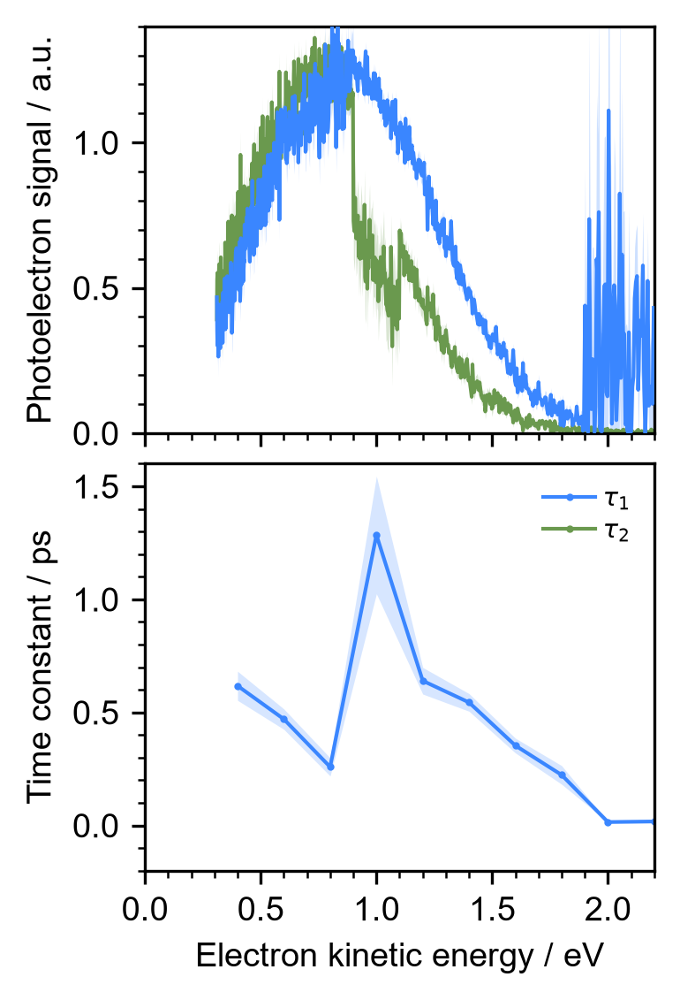

In [1053]:
fig,(ax0,ax1) = plt.subplots(2)
plt.subplots_adjust(hspace=0.075)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid*0.75)


ax0.plot(energies_plot,A1s,'-',c=blue,ms=1,zorder=100)
ax0.plot(energies_plot,A2s,'-',c=green,ms=1)
ax0.fill_between(energies_plot,A1s-A1s_err,A1s+A1s_err,alpha=.25,color=blue,lw=0)
ax0.fill_between(energies_plot,A2s-A2s_err,A2s+A2s_err,alpha=.25,color=green,lw=0)

ax1.plot(energies_tau,tau1,'o-',c=blue,ms=1,label="$\\tau_1$")
ax1.fill_between(energies_tau,tau1-tau1_err,tau1+tau1_err,alpha=.2,color=blue,lw=0)
# ax1.errorbar(energies_tau,tau1,tau1_err,capsize=2,fmt='o',ms=2,color=blue)
ax1.plot(energies_tau,tau2,'o-',c=green,ms=1,label="$\\tau_2$")
ax1.fill_between(energies_tau,tau2-tau2_err,tau2+tau2_err,alpha=.2,color=green,lw=0)

# ax2.errorbar(energies,tau1,tau1_err,capsize=2,fmt='o',ms=2)



# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax0.set_xlim(0,2.2)
ax1.set_xlim(0,2.2)
ax0.set_ylim(0,1.4)
ax1.set_ylim(-.2,1.6)

for ax in (ax0,ax1):
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(0.1))
ax1.yaxis.set_major_locator(MultipleLocator(.5))
ax1.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax1.set_xlabel("Electron kinetic energy / eV",)
ax0.set_ylabel("Photoelectron signal / a.u.")
ax1.set_ylabel("Time constant / ps")


ax0.set_xticklabels([])
ax1.legend()
# ax2.yaxis.label.set_color(green)

# ax2.spines["right"].set_edgecolor(blue)
# ax2.tick_params(axis='y', which='both',colors=blue)


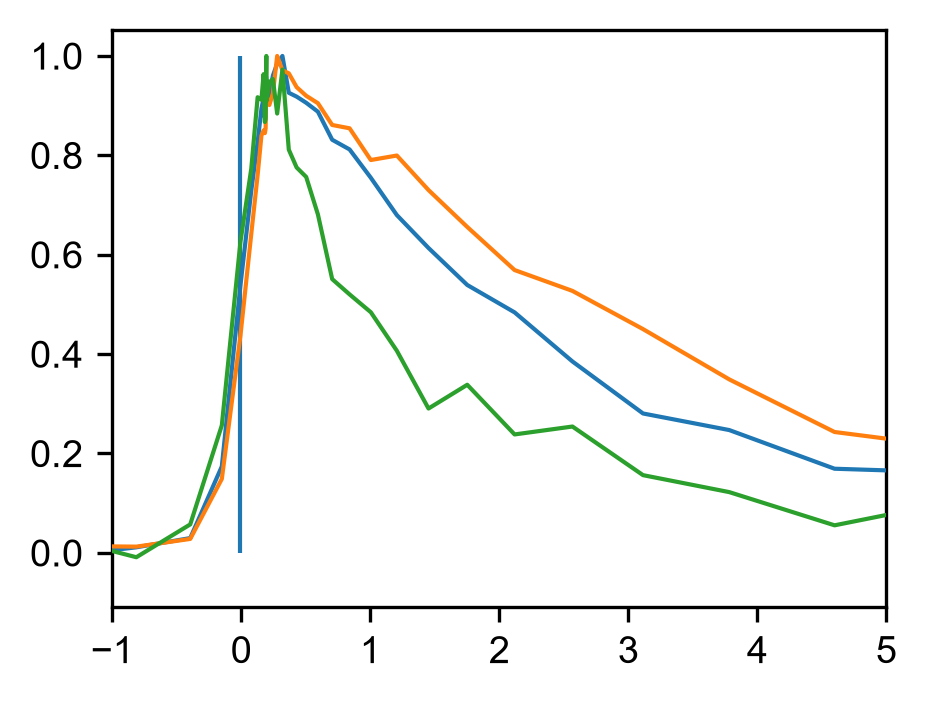

In [1051]:
plot_mask = (np.logical_and(energies>1,energies<=1.05))
sumtr = np.sum(traces[:,plot_mask],axis=1)
plt.plot(delays,sumtr/max(sumtr),zorder=20)

plot_mask = (np.logical_and(energies>.6,energies<=.65))
sumtr = np.sum(traces[:,plot_mask],axis=1)
plt.plot(delays,sumtr/max(sumtr),zorder=20)

plot_mask = (np.logical_and(energies>1.5,energies<=1.55))
sumtr = np.sum(traces[:,plot_mask],axis=1)
plt.plot(delays,sumtr/max(sumtr),zorder=20)

plt.xlim(-1,5)
plt.vlines(delays[6],0,1)

### GLobal fitting (DAS) with constraints -- unbinned

#### The model



In [1144]:
def biexponential(x,A1,A2,tau1,tau2):
    sigma = 0.320 / 2.355  # cross-correlation with 250 & 267
    t0=0
    return A1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma)))) + A2/2 * np.exp((-1/tau2)*(x-0))*np.exp((sigma**2)/(2*(tau2**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau2))/(np.sqrt(2.0)*sigma))))

def global_fit(flat_delays, tau1, tau2, *amplitudes,traces_number = 70):
    # traces_number = 70
    points_per_trace = 47

    delays = flat_delays.reshape(traces_number, points_per_trace)
    amps = np.array(amplitudes).reshape(traces_number, 2)  

    return biexponential(
        delays,
        amps[:, 0][:, None], 
        amps[:, 1][:, None],
        tau1, tau2,
    ).ravel()
    

#### Flatten delays + traces

In [1055]:
#Mask traces
mask = scanSet.energies<2.2
traces = scanSet.subtracted[:,mask]
traces.shape

(47, 705)

In [1056]:
# Normalise traces
#Total counts
trace = -np.trapezoid(scanSet.subtracted,axis=1,x=scanSet.energies)
traces /= max(trace)
traces.shape

(47, 705)

In [1057]:
energies = scanSet.energies[mask]

#Set limits for time ranges
energyStep = .2
energyLimit = 0.3 # eV

traces_grouped = []
energies_grouped = []

    
while energyLimit<2.2:
    #Mask data outside of time range
    mask_bins = (np.logical_and(energies>energyLimit,
                                energies<=energyLimit+energyStep))
    # print(energyLimit,energyLimit+energyStep)
    masked_data = traces[:,mask_bins]
    masked_energies = energies[mask_bins]
    
    
        
    
    traces_grouped.append(masked_data)
    energies_grouped.append(masked_energies)
    energyLimit += energyStep
    energyLimit = round(energyLimit,2)
    
# traces_grouped

In [1058]:
delays_grouped = []
delays = scanSet.delays-scanSet.t0
# Tile delays
for trace_group in traces_grouped:
    flat_delays = np.tile(delays,(trace_group.shape[1]))
    delays_grouped.append(flat_delays)

In [1059]:
# define functions
def make_fit_model(traces_number):
    """Generates a custom fit_model function for a specific traces_number."""
    def fit_model(flat_delays, tau1, tau2, *amplitudes):
        tau2=2.8433
        return global_fit(
            flat_delays, 
            tau1, 
            tau2, 
            *amplitudes, 
            traces_number=traces_number
        )
    return fit_model
    
fit_models = [make_fit_model(len(trace_group.T)) for trace_group in traces_grouped] 
fit_models[0]

<function __main__.make_fit_model.<locals>.fit_model(flat_delays, tau1, tau2, *amplitudes)>

In [1060]:
#flatten traces
traces_grouped_flat = []
for i,trace_group in enumerate(traces_grouped):
    traces_grouped_flat.append(trace_group.T.flatten())

In [1061]:
traces_grouped_flat[1].shape,delays_grouped[1].shape

((5311,), (5311,))

#### Fit

In [1065]:
p0 = [1,1,0.6,2.8]
all_params = []
all_perrs = []
for i in range(len(traces_grouped)):
    trace_group = traces_grouped[i]
    flat_delays = delays_grouped[i]
    fit_model = fit_models[i]
    flat_traces = traces_grouped_flat[i]

    p0 = [1,3.5]+[1 for n in range(len(trace_group.T)) for x in (1,1)]

    print(trace_group.shape)
    
    params, pcov = curve_fit(fit_model,flat_delays,flat_traces,
                        p0 = p0,bounds=(-np.inf,np.inf),)
    perr = np.sqrt(np.diag(pcov))

    all_params.append(params)
    all_perrs.append(perr)
# all_params = np.array(all_params)
# all_perrs = np.array(all_perrs)
# all_params.shape

(47, 131)


C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\3586812241.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  params, pcov = curve_fit(fit_model,flat_delays,flat_traces,


(47, 113)
(47, 93)
(47, 79)
(47, 68)
(47, 60)
(47, 52)
(47, 47)
(47, 42)
(47, 20)


C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\1252902427.py:4: RuntimeWarning: overflow encountered in exp
  return A1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma)))) + A2/2 * np.exp((-1/tau2)*(x-0))*np.exp((sigma**2)/(2*(tau2**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau2))/(np.sqrt(2.0)*sigma))))
C:\Users\edoar\AppData\Local\Temp\ipykernel_14724\1252902427.py:4: RuntimeWarning: overflow encountered in multiply
  return A1/2 * np.exp((-1/tau1)*(x-0))*np.exp((sigma**2)/(2*(tau1**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau1))/(np.sqrt(2.0)*sigma)))) + A2/2 * np.exp((-1/tau2)*(x-0))*np.exp((sigma**2)/(2*(tau2**2))) * (1 + (scipy.special.erf((x-0-((sigma**2)/tau2))/(np.sqrt(2.0)*sigma))))


#### Results

In [1066]:
tau1 = []
tau2 = []
A1s = []
A2s = []
tau1_err = []
tau2_err = []
A1s_err = []
A2s_err = []
energies_plot = []
for i, params in enumerate(all_params[::-1]):
    A1s += list(params[2::2])
    A2s += list(params[3::2])
    energies_plot += list(energies_grouped[-i-1])

    tau1.append(params[0])
    tau2.append(params[1])
    #errors
    A1s_err += list(all_perrs[-i-1][2::2])
    A2s_err += list(all_perrs[-i-1][3::2])
    tau1_err.append(all_perrs[-i-1][0])
    tau2_err.append(all_perrs[-i-1][1])
tau1 = np.array(tau1)
tau2 = np.array(tau2)
A1s = np.array(A1s)
A2s = np.array(A2s)
tau1_err = np.array(tau1_err)
tau2_err = np.array(tau2_err)
A1s_err = np.array(A1s_err)
A2s_err = np.array(A2s_err)

energies_plot = np.array(energies_plot)
energies_tau = np.arange(0.3,2.2,energyStep)+energyStep/2
energies_tau = energies_tau[::-1]

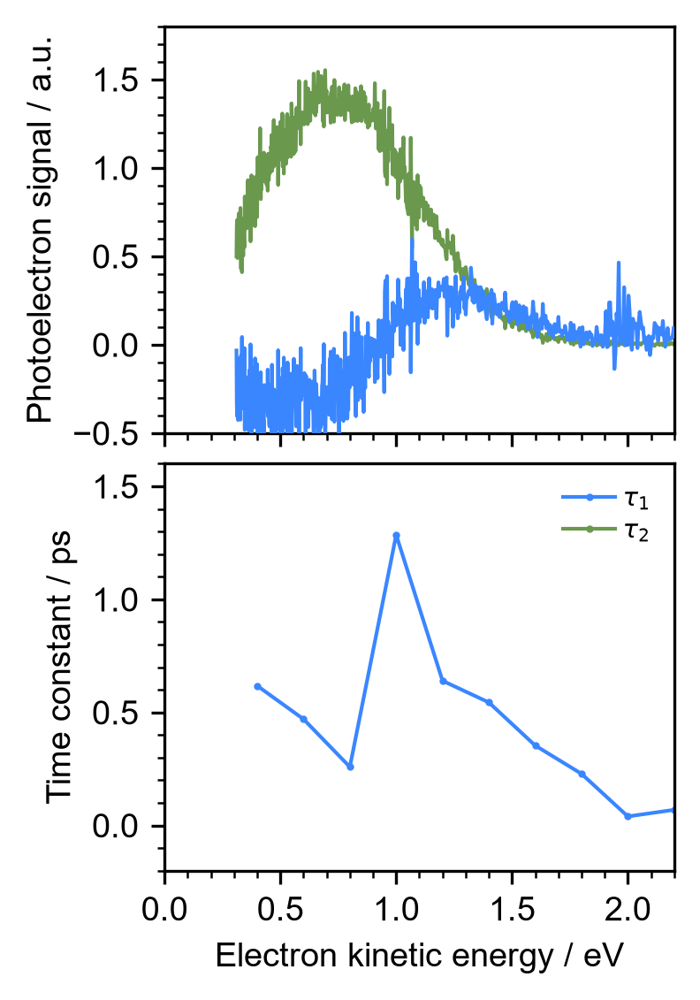

In [1068]:
fig,(ax0,ax1) = plt.subplots(2)
plt.subplots_adjust(hspace=0.075)
fig.set_dpi(300)
fig.set_size_inches(thesisWid*.45,thesisWid*0.75)


ax0.plot(energies_plot,A1s,'-',c=blue,ms=1,zorder=100)
ax0.plot(energies_plot,A2s,'-',c=green,ms=1)
ax0.fill_between(energies_plot,A1s-A1s_err,A1s+A1s_err,alpha=.25,color=blue,lw=0)
ax0.fill_between(energies_plot,A2s-A2s_err,A2s+A2s_err,alpha=.25,color=green,lw=0)

ax1.plot(energies_tau,tau1,'o-',c=blue,ms=1,label="$\\tau_1$")
ax1.fill_between(energies_tau,tau1-tau1_err,tau1+tau1_err,alpha=.2,color=blue,lw=0)
# ax1.errorbar(energies_tau,tau1,tau1_err,capsize=2,fmt='o',ms=2,color=blue)
ax1.plot(energies_tau,tau2,'o-',c=green,ms=1,label="$\\tau_2$")
ax1.fill_between(energies_tau,tau2-tau2_err,tau2+tau2_err,alpha=.2,color=green,lw=0)

# ax2.errorbar(energies,tau1,tau1_err,capsize=2,fmt='o',ms=2)



# ax.legend(frameon=False, title='EAS',title_fontsize=8)
ax0.set_xlim(0,2.2)
ax1.set_xlim(0,2.2)
ax0.set_ylim(-.5,1.8)
ax1.set_ylim(-.2,1.6)

for ax in (ax0,ax1):
    ax.xaxis.set_major_locator(MultipleLocator(.5))
    ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax0.yaxis.set_major_locator(MultipleLocator(.5))
ax0.yaxis.set_minor_locator(MultipleLocator(0.1))
ax1.yaxis.set_major_locator(MultipleLocator(.5))
ax1.yaxis.set_minor_locator(MultipleLocator(0.1))
    
ax1.set_xlabel("Electron kinetic energy / eV",)
ax0.set_ylabel("Photoelectron signal / a.u.")
ax1.set_ylabel("Time constant / ps")


ax0.set_xticklabels([])
ax1.legend()
# ax2.yaxis.label.set_color(green)

# ax2.spines["right"].set_edgecolor(blue)
# ax2.tick_params(axis='y', which='both',colors=blue)
